# Imports

## Import the folder for compatibility (if running local)

In [1]:
import os
import sys

project_root = "Incremental-Learning-MycroftMinds"
cwd = os.path.abspath(os.getcwd())
while True:
    if os.path.basename(cwd) == project_root:
        if cwd not in sys.path:
            sys.path.insert(0, cwd)
        break
    parent = os.path.dirname(cwd)
    if parent == cwd:
        raise FileNotFoundError(f"Project root '{project_root}' not found in any parent directory.")
    cwd = parent

## Import external libs and internal models

In [2]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.utils.utils import get_device_data
from src.evaluation.metrics import calculate_metrics, all_time_aggregation_metrics
from src.evaluation.visualization import plot_part_predictions, plot_hourly_predictions
from src.evaluation.training import all_valid_splits_seq_fit_predict, test_set_seq_fit_predict

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from river.forest import ARFRegressor
from river.tree import HoeffdingTreeRegressor
from src.evaluation.baseline import PreviousValueRegressor, SeasonalMeanRegressor
from src.trees import fastodt
from src.bagging import ARFRegressorFODT
from src.boosting import IncubationBoost
from src.ensemble_methods import elasticGBDT

import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

# Download the splitted data

In [3]:
# check you data dir and file prefixes
data_dir = '../../data/second_batch/industrial'

## Evaluation Settings

In [4]:
DATA_FREQUENCY = 'H'  # 1-Hour frequency
FORECAST_HORIZON = '1h'  # 1-Hour forecast horizon
SPIKE_PROMINENCE = 3.5  # For industrial data

In [5]:
# Measure loading time
start_time = time.time()

# Load data
train, valid, test = load_dataset(data_dir=data_dir, prefix='sb_ind_hour_wfv', use_numpy=True)
FEATURES = ['time', 'device_id', 'hour', 'weekday', 'month', 
           'consumption_lag_1h', 'consumption_lag_2h', 'consumption_lag_24h', 'consumption_lag_25h']

loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

[INFO] Loading train data...
[INFO] Train data loaded: 25 samples
[INFO] Loading valid data...
[INFO] Valid data loaded: 25 samples
[INFO] Loading test data...
[INFO] Test data loaded: 2 samples
Data loaded in 0.04 minutes


## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [6]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

Training data: 25 splits
Validation data: 25 splits
First train split shape: X=(1344, 9), y=(1344,)
First valid split shape: X=(1344, 9), y=(1344,)

Memory usage:
Train: 40.54 MB
Valid: 4.23 MB
Test: 1.08 MB
Total: 45.85 MB


# WFV Models Evaluation
(train+valid WFV)
- (1) `train[0]` vs `valid[0]`
- (2) `train[1]` vs `valid[1]`
- ...
- (n) `train[n]` vs `valid[n]`

, where: 
$$ train[1] = train[0]+valid[0] $$
$$...$$
$$ train[n] = train[0]+valid[0]+valid[1]+...+valid[n-1] $$

## Hourly granularity

### Baseline model (seasonal averages)

In [7]:
update_freq = "14D"
bl_mean = SeasonalMeanRegressor
bl_mean_params = {}

In [8]:
bl_mean_train_period_predictions, bl_mean_valid_period_predictions,\
bl_mean_train_period_metrics, bl_mean_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_mean,
    model_params=bl_mean_params,
    train=train,
    valid=valid,
    incremental=False,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]


Retraining model on data from 2023-02-27 03:00:00+01:00 to 2023-03-27 03:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2023-03-27 04:00:00+02:00 to 2023-04-10 04:00:00+02:00

-------------------------

Retraining model on data from 2023-02-27 03:00:00+01:00 to 2023-04-10 04:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2023-04-10 05:00:00+02:00 to 2023-04-24 03:00:00+02:00

-------------------------
Model's memory usage: 0.024620 MB
Metrics for Device: site1 | Period: 2023-03-27 04:00:00+02:00 - 2023-04-24 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1810
	MAE: 0.1506
	MAPE: 66.9285%

Directional Metrics:
	Directional Accuracy: 71.2370%
	First-Diff Correlation: 0.6743

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3043
		Recall: 0.3043
		F1: 0.3043
	Drops:
		Precision: 0.1304
		Recall: 0.1364
		F1: 0.1333

Delayed Detection (delta=

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]


Retraining model on data from 2023-02-27 03:00:00+01:00 to 2023-04-24 03:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2023-04-24 04:00:00+02:00 to 2023-05-08 04:00:00+02:00

-------------------------

Retraining model on data from 2023-02-27 03:00:00+01:00 to 2023-05-08 04:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2023-05-08 05:00:00+02:00 to 2023-05-22 03:00:00+02:00

-------------------------
Model's memory usage: 0.024460 MB
Metrics for Device: site1 | Period: 2023-04-24 04:00:00+02:00 - 2023-05-22 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1722
	MAE: 0.1432
	MAPE: 80.4504%

Directional Metrics:
	Directional Accuracy: 67.5112%
	First-Diff Correlation: 0.7176

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.4231
		Recall: 0.2558
		F1: 0.3188
	Drops:
		Precision: 0.0800
		Recall: 0.0435
		F1: 0.0563

Delayed Detection (delta=

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]


Retraining model on data from 2024-06-29 12:00:00+02:00 to 2024-12-30 02:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2024-12-30 03:00:00+01:00 to 2025-01-13 03:00:00+01:00

-------------------------

Retraining model on data from 2024-06-29 12:00:00+02:00 to 2025-01-13 03:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2025-01-13 04:00:00+01:00 to 2025-01-27 02:00:00+01:00

-------------------------
Model's memory usage: 0.024162 MB
Metrics for Device: site9 | Period: 2024-12-30 03:00:00+01:00 - 2025-01-27 02:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.9243
	MAE: 0.8541
	MAPE: 126.8179%

Directional Metrics:
	Directional Accuracy: 61.5499%
	First-Diff Correlation: 0.7444

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0500
		Recall: 0.0333
		F1: 0.0400
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]


Retraining model on data from 2024-06-29 12:00:00+02:00 to 2025-01-27 02:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2025-01-27 03:00:00+01:00 to 2025-02-10 03:00:00+01:00

-------------------------

Retraining model on data from 2024-06-29 12:00:00+02:00 to 2025-02-10 03:00:00+01:00

Time: 0.02 seconds
Predicting for chunk from 2025-02-10 04:00:00+01:00 to 2025-02-23 17:00:00+01:00

-------------------------
Model's memory usage: 0.024162 MB
Metrics for Device: site9 | Period: 2025-01-27 03:00:00+01:00 - 2025-02-23 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.1382
	MAE: 0.5677
	MAPE: 20.9447%

Directional Metrics:
	Directional Accuracy: 64.5015%
	First-Diff Correlation: 0.8101

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1000
		Recall: 0.0714
		F1: 0.0833
	Drops:
		Precision: 0.1053
		Recall: 0.0741
		F1: 0.0870

Delayed Detection (delta=

#### Results

In [9]:
print("\n\nValid period metrics:")
bl_mean_all_time_valid_metrics = all_time_aggregation_metrics(bl_mean_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.1614 ± 0.1006
	MAE: 0.1335 ± 0.0849
	MAPE: 50.4904% ± 17.8308%

	Directional Metrics:
		Directional Accuracy: 65.4823% ± 3.3109%
		First-Diff Correlation: 0.6268 ± 0.0984

	Immediate Detection (delta=0):
		Spike Precision: 0.3037 ± 0.1855
		Spike Recall: 0.2412 ± 0.1335
		Spike F1: 0.2362 ± 0.1166
		Drop Precision: 0.1140 ± 0.0817
		Drop Recall: 0.1236 ± 0.1216
		Drop F1: 0.0982 ± 0.0664

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.5002 ± 0.2719
		Spike Recall: 0.4144 ± 0.1594
		Spike F1: 0.3896 ± 0.1299
		Drop Precision: 0.2001 ± 0.1402
		Drop Recall: 0.1932 ± 0.1804
		Drop F1: 0.1636 ± 0.1056
Daily Metrics:
	RMSE: 3.1103 ± 2.4729
	MAE: 2.7020 ± 2.0833
	MAPE: 41.2317% ± 17.3577%

	Directional Metrics:
		Directional Accuracy: 62.0342% ± 10.0156%
		First-Diff Correlation: 0.6821 ± 0.1232

	Immediate Detection (delta=0):
		

#### Validation plots

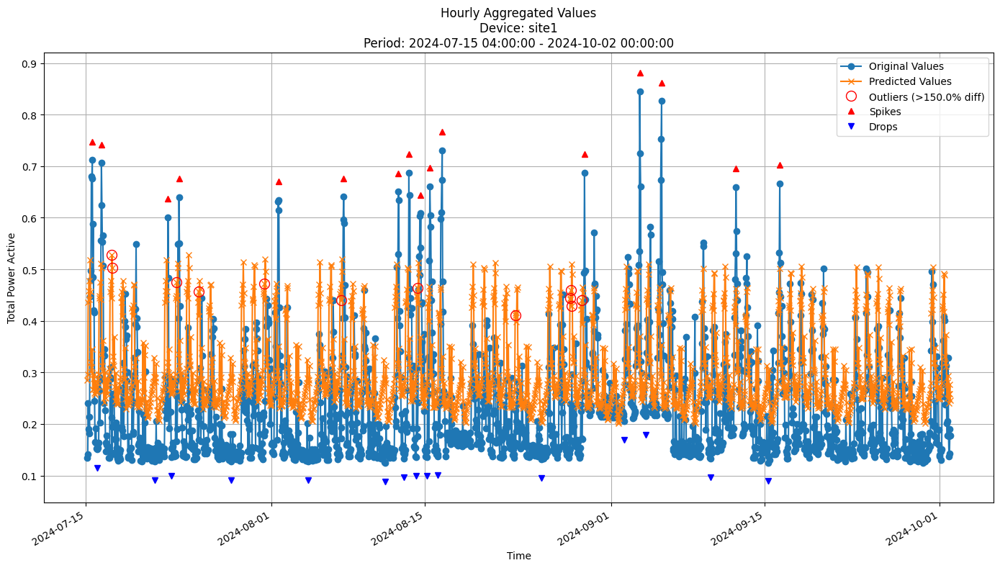


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1232
MAE: 0.1054
MAPE: 53.5682%

Directional Metrics:
Directional Accuracy: 61.7865%
First-Diff Correlation: 0.5003

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


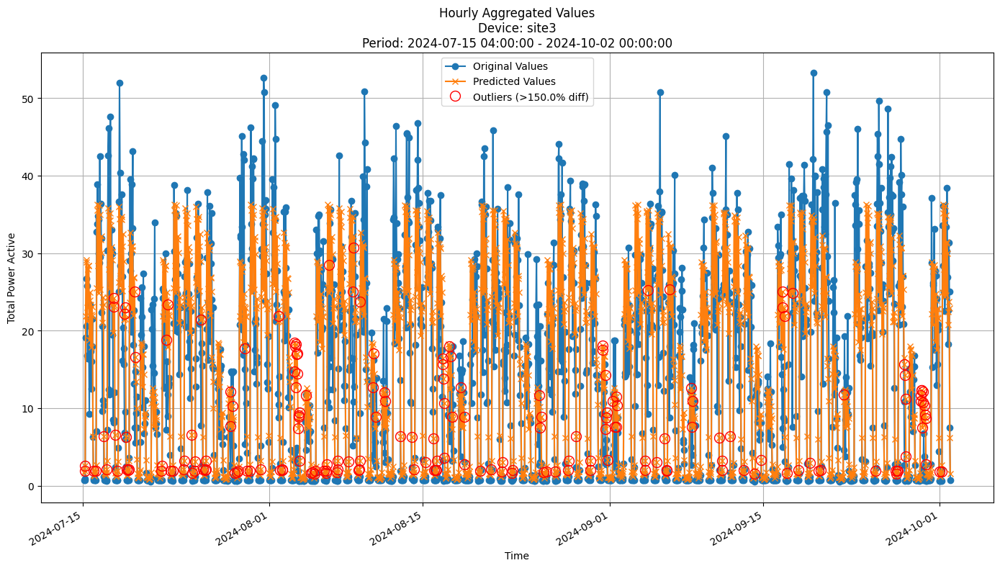


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 6.4288
MAE: 4.3697
MAPE: 72.4176%

Directional Metrics:
Directional Accuracy: 56.8182%
First-Diff Correlation: 0.6603

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


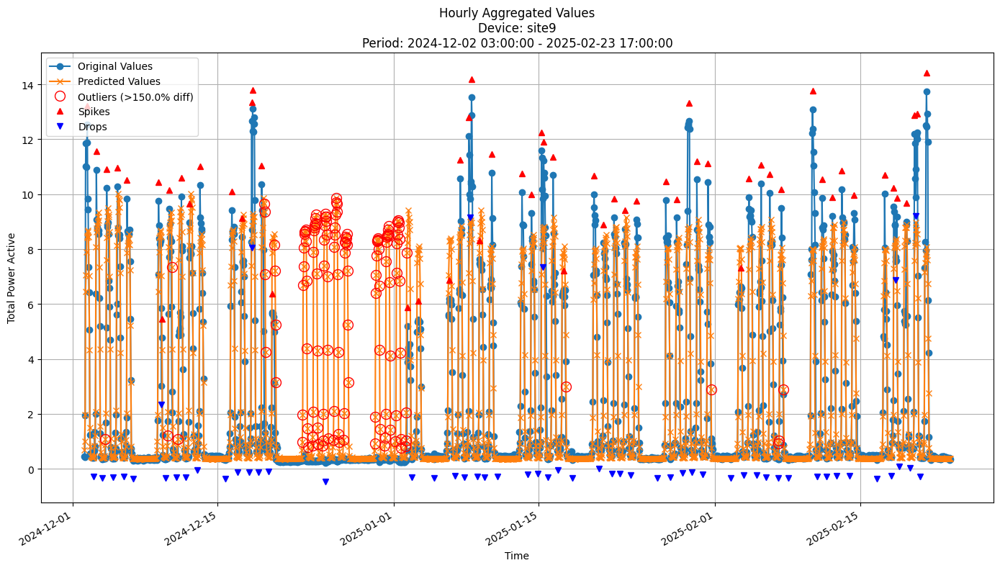


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.8996
MAE: 0.8304
MAPE: 122.6409%

Directional Metrics:
Directional Accuracy: 61.1167%
First-Diff Correlation: 0.7381

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0500
  Recall: 0.0517
  F1 Score: 0.0508
Drops:
  Precision: 0.0847
  Recall: 0.0877
  F1 Score: 0.0862

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2333
  Recall: 0.2414
  F1 Score: 0.2373
Drops:
  Precision: 0.2542
  Recall: 0.2632
  F1 Score: 0.2586


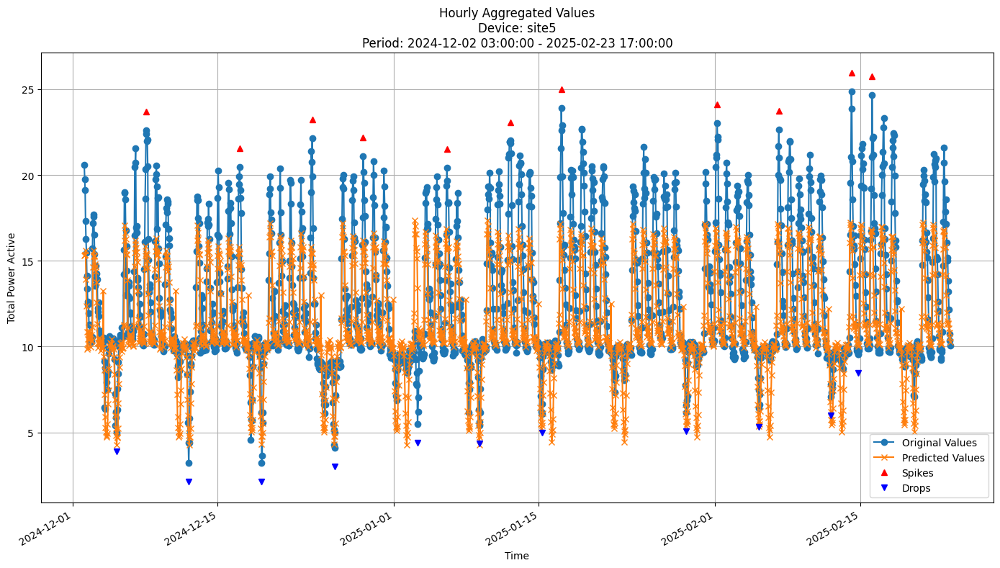


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.5591
MAE: 1.8497
MAPE: 13.8020%

Directional Metrics:
Directional Accuracy: 66.8495%
First-Diff Correlation: 0.4987

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.2500
  Recall: 0.2727
  F1 Score: 0.2609

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.4167
  Recall: 0.4545
  F1 Score: 0.4348


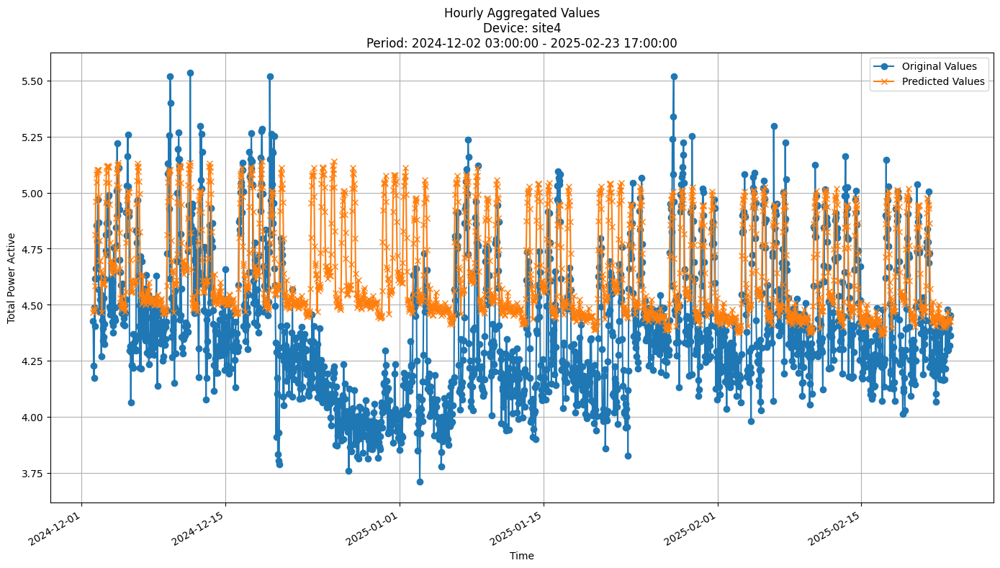


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3577
MAE: 0.2834
MAPE: 6.7034%

Directional Metrics:
Directional Accuracy: 53.7886%
First-Diff Correlation: 0.2921

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


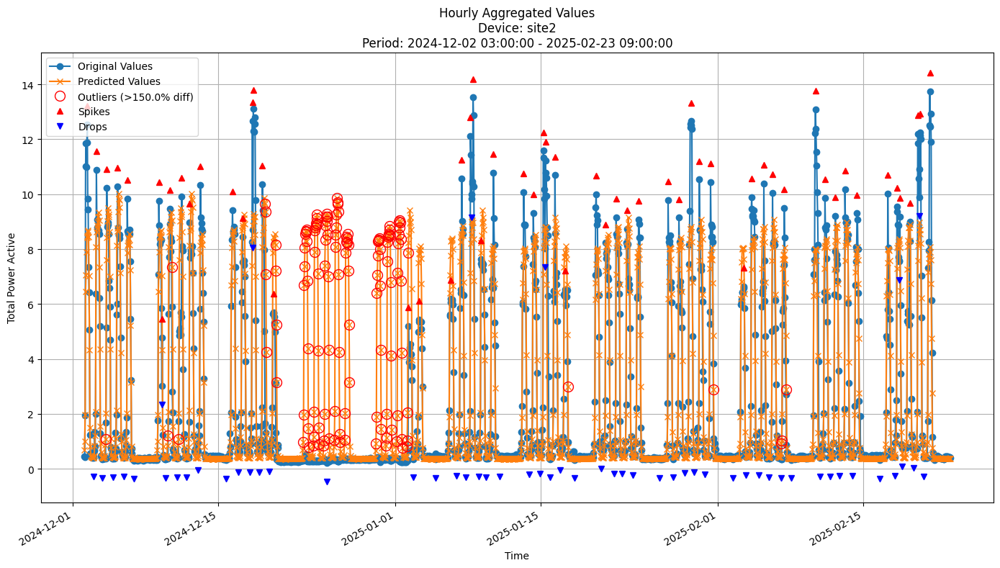


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.9034
MAE: 0.8336
MAPE: 123.1054%

Directional Metrics:
Directional Accuracy: 61.2112%
First-Diff Correlation: 0.7381

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0500
  Recall: 0.0517
  F1 Score: 0.0508
Drops:
  Precision: 0.0847
  Recall: 0.0877
  F1 Score: 0.0862

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2333
  Recall: 0.2414
  F1 Score: 0.2373
Drops:
  Precision: 0.2542
  Recall: 0.2632
  F1 Score: 0.2586


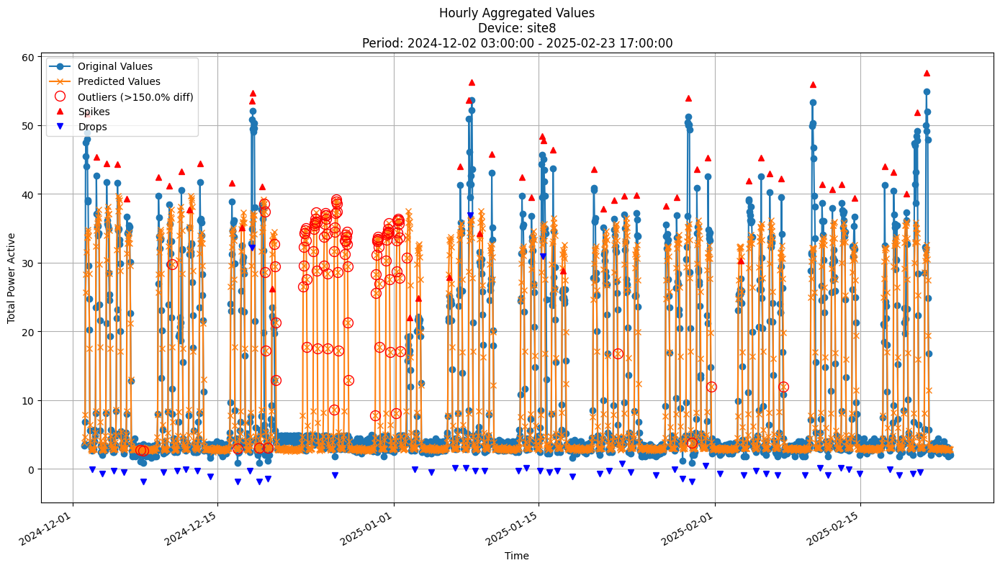


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 7.2461
MAE: 3.3662
MAPE: 54.5130%

Directional Metrics:
Directional Accuracy: 57.7767%
First-Diff Correlation: 0.7228

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0333
  Recall: 0.0364
  F1 Score: 0.0348
Drops:
  Precision: 0.0847
  Recall: 0.0926
  F1 Score: 0.0885

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2167
  Recall: 0.2364
  F1 Score: 0.2261
Drops:
  Precision: 0.2373
  Recall: 0.2593
  F1 Score: 0.2478


In [10]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in bl_mean_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_mean_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_mean_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### Baseline model (predict previous value)

In [11]:
update_freq = "1H"
bl_prev = PreviousValueRegressor
bl_prev_params = {}

In [12]:
bl_prev_train_period_predictions, bl_prev_valid_period_predictions,\
bl_prev_train_period_metrics, bl_prev_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_prev,
    model_params=bl_prev_params,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 03:00:00+01:00 to 2023-03-27 03:00:00+02:00
Model's memory usage: 0.000420 MB
Metrics for Device: site1 | Period: 2023-03-27 04:00:00+02:00 - 2023-04-24 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0783
	MAE: 0.0527
	MAPE: 19.0481%

Directional Metrics:
	Directional Accuracy: 49.7765%
	First-Diff Correlation: -0.0117

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9583
		Recall: 1.0000
		F1: 0.9787
	Drops:
		Precision: 0.9565
		Recall: 1.0000
		F1: 0.9778
--------------------------------------------------
Da

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 03:00:00+01:00 to 2023-04-24 03:00:00+02:00
Model's memory usage: 0.000404 MB
Metrics for Device: site1 | Period: 2023-04-24 04:00:00+02:00 - 2023-05-22 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0604
	MAE: 0.0385
	MAPE: 18.1361%

Directional Metrics:
	Directional Accuracy: 41.7288%
	First-Diff Correlation: -0.2240

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Da

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 12:00:00+02:00 to 2024-12-30 02:00:00+01:00
Model's memory usage: 0.000214 MB
Metrics for Device: site9 | Period: 2024-12-30 03:00:00+01:00 - 2025-01-27 02:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.2118
	MAE: 0.4857
	MAPE: 22.5320%

Directional Metrics:
	Directional Accuracy: 51.1177%
	First-Diff Correlation: 0.2656

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 12:00:00+02:00 to 2025-01-27 02:00:00+01:00
Model's memory usage: 0.000214 MB
Metrics for Device: site9 | Period: 2025-01-27 03:00:00+01:00 - 2025-02-23 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.4321
	MAE: 0.6436
	MAPE: 25.8170%

Directional Metrics:
	Directional Accuracy: 52.5680%
	First-Diff Correlation: 0.2853

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

#### Results

In [13]:
print("\n\nValid period metrics:")
bl_prev_all_time_valid_metrics = all_time_aggregation_metrics(bl_prev_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0721 ± 0.0085
	MAE: 0.0470 ± 0.0072
	MAPE: 17.6682% ± 2.2495%

	Directional Metrics:
		Directional Accuracy: 44.6712% ± 3.5092%
		First-Diff Correlation: -0.0971 ± 0.0960

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.9829 ± 0.0479
		Spike Recall: 0.9972 ± 0.0093
		Spike F1: 0.9893 ± 0.0262
		Drop Precision: 0.9978 ± 0.0095
		Drop Recall: 0.9971 ± 0.0096
		Drop F1: 0.9974 ± 0.0066
Daily Metrics:
	RMSE: 0.0722 ± 0.0497
	MAE: 0.0505 ± 0.0388
	MAPE: 0.7561% ± 0.2958%

	Directional Metrics:
		Directional Accuracy: 98.0357% ± 3.2878%
		First-Diff Correlation: 0.9981 ± 0.0017

	Immediate Detection (delta=0):
		Spi

#### Validation plots

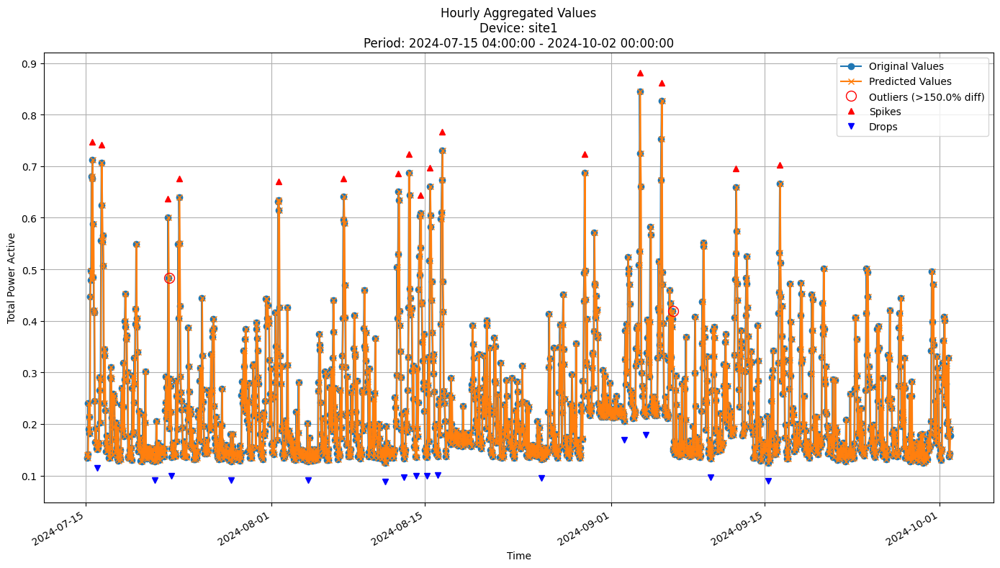


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0706
MAE: 0.0462
MAPE: 19.0152%

Directional Metrics:
Directional Accuracy: 42.0719%
First-Diff Correlation: -0.0916

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


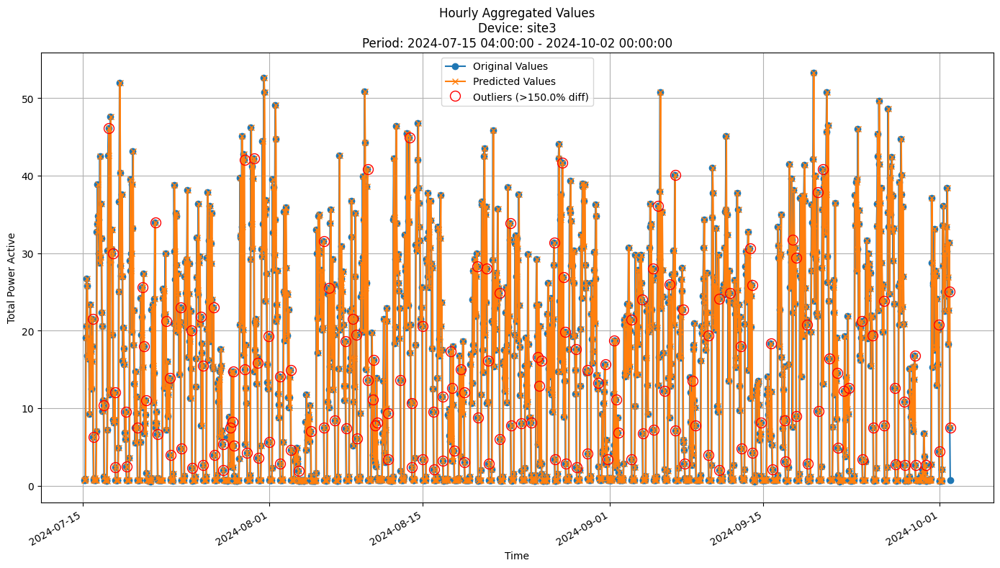


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 8.5881
MAE: 5.4868
MAPE: 64.5183%

Directional Metrics:
Directional Accuracy: 45.8245%
First-Diff Correlation: -0.0977

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


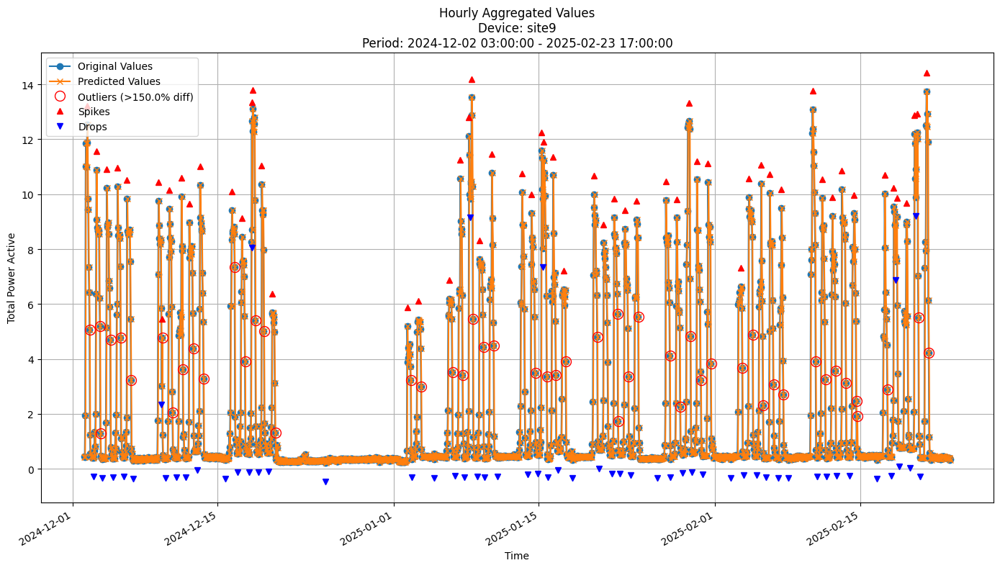


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2977
MAE: 0.5397
MAPE: 24.0322%

Directional Metrics:
Directional Accuracy: 47.6072%
First-Diff Correlation: 0.2728

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


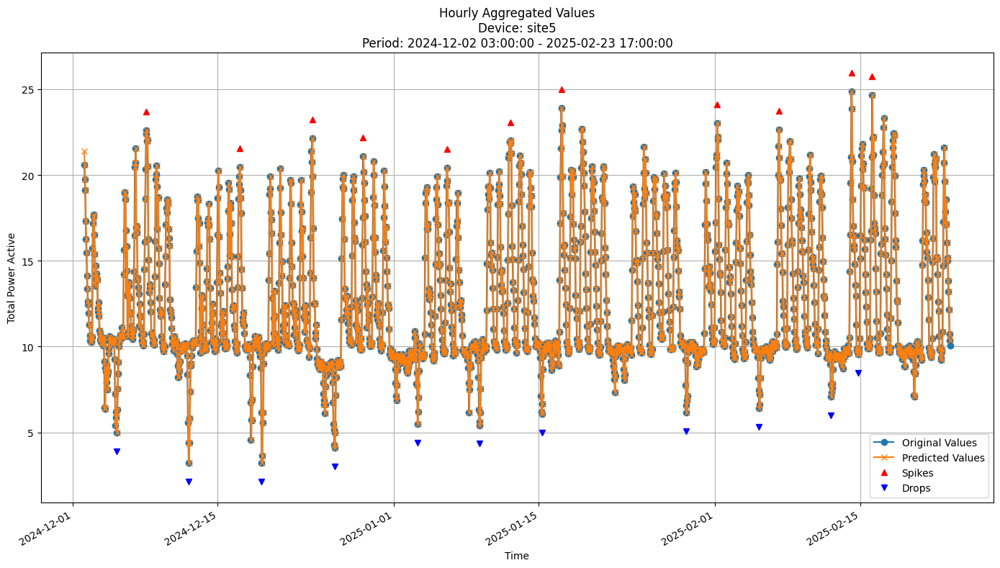


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2851
MAE: 0.8559
MAPE: 6.5353%

Directional Metrics:
Directional Accuracy: 61.3161%
First-Diff Correlation: 0.4708

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


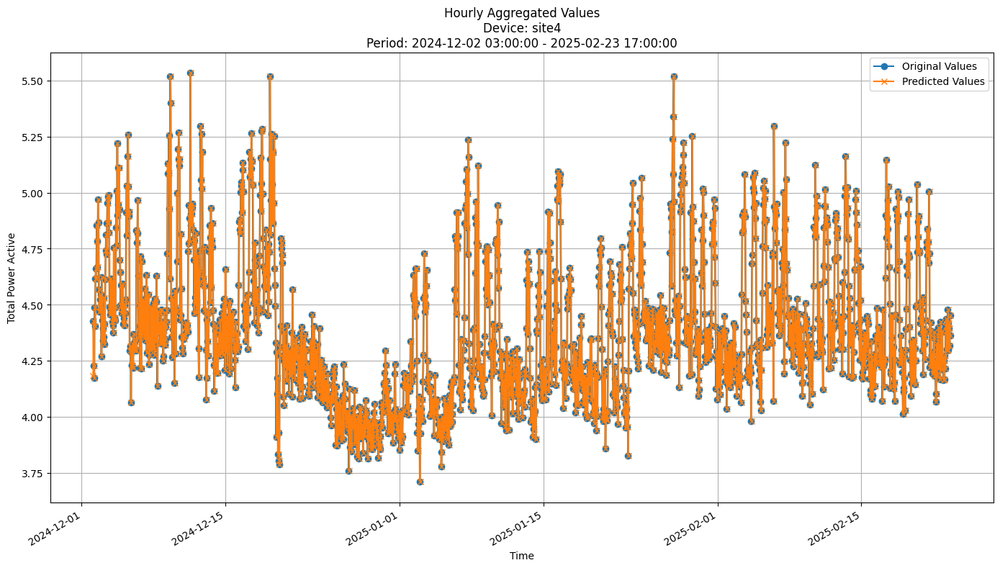


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1841
MAE: 0.1346
MAPE: 3.0333%

Directional Metrics:
Directional Accuracy: 35.3440%
First-Diff Correlation: -0.2873

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


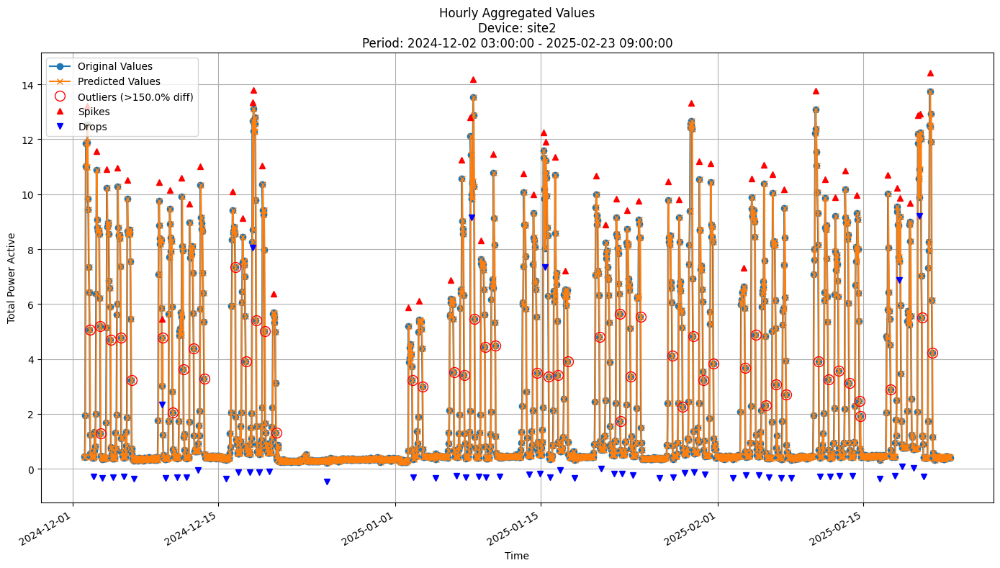


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.3003
MAE: 0.5418
MAPE: 24.0907%

Directional Metrics:
Directional Accuracy: 47.6476%
First-Diff Correlation: 0.2728

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


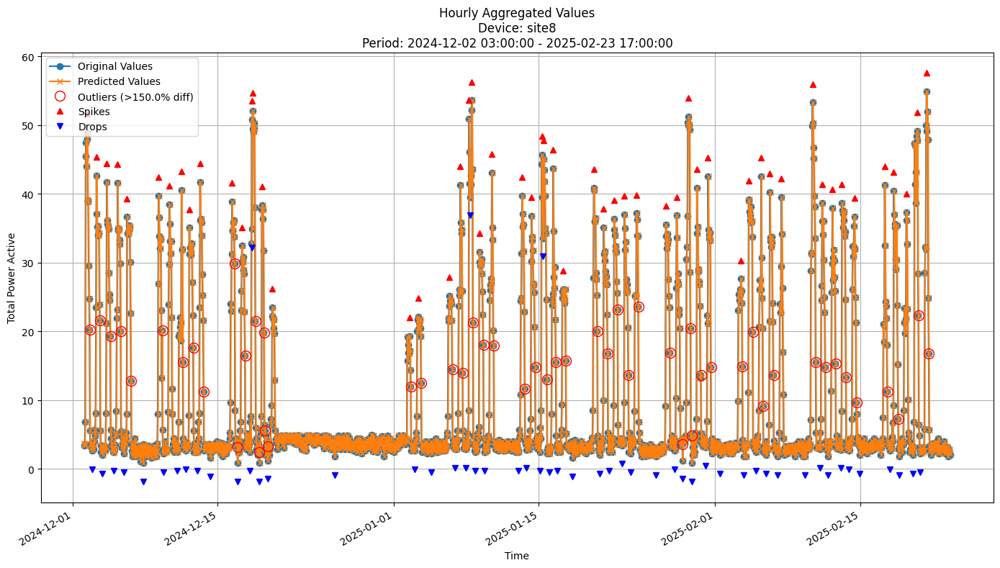


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 5.2299
MAE: 2.4375
MAPE: 29.7593%

Directional Metrics:
Directional Accuracy: 43.9182%
First-Diff Correlation: 0.2371

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


In [14]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in bl_prev_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_prev_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_prev_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### GBDT

In [15]:
update_freq = "14D"  # Update the model every 14 days
gbdt = GradientBoostingRegressor
gbdt_params = {
    'n_estimators': 150, 
     'learning_rate': 0.05, 
     'max_depth': 7, 
     'subsample': 0.8, 
     'random_state': 42
}

In [16]:
gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=gbdt,
    model_params=gbdt_params,
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]


Retraining model on data from 2023-02-27 03:00:00+01:00 to 2023-03-27 03:00:00+02:00

Time: 0.26 seconds
Predicting for chunk from 2023-03-27 04:00:00+02:00 to 2023-04-10 04:00:00+02:00

-------------------------

Retraining model on data from 2023-02-27 03:00:00+01:00 to 2023-04-10 04:00:00+02:00

Time: 0.37 seconds
Predicting for chunk from 2023-04-10 05:00:00+02:00 to 2023-04-24 03:00:00+02:00

-------------------------
Model's memory usage: 0.012306 MB
Metrics for Device: site1 | Period: 2023-03-27 04:00:00+02:00 - 2023-04-24 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0737
	MAE: 0.0554
	MAPE: 22.9616%

Directional Metrics:
	Directional Accuracy: 63.4873%
	First-Diff Correlation: 0.4868

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3333
		Recall: 0.3043
		F1: 0.3182
	Drops:
		Precision: 0.1000
		Recall: 0.0909
		F1: 0.0952

Delayed Detection (delta=

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]


Retraining model on data from 2023-02-27 03:00:00+01:00 to 2023-04-24 03:00:00+02:00

Time: 0.45 seconds
Predicting for chunk from 2023-04-24 04:00:00+02:00 to 2023-05-08 04:00:00+02:00

-------------------------

Retraining model on data from 2023-02-27 03:00:00+01:00 to 2023-05-08 04:00:00+02:00

Time: 0.51 seconds
Predicting for chunk from 2023-05-08 05:00:00+02:00 to 2023-05-22 03:00:00+02:00

-------------------------
Model's memory usage: 0.012154 MB
Metrics for Device: site1 | Period: 2023-04-24 04:00:00+02:00 - 2023-05-22 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0454
	MAE: 0.0315
	MAPE: 16.1568%

Directional Metrics:
	Directional Accuracy: 60.3577%
	First-Diff Correlation: 0.4583

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1935
		Recall: 0.1395
		F1: 0.1622
	Drops:
		Precision: 0.0667
		Recall: 0.0435
		F1: 0.0526

Delayed Detection (delta=

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]


Retraining model on data from 2024-06-29 12:00:00+02:00 to 2024-12-30 02:00:00+01:00

Time: 1.50 seconds
Predicting for chunk from 2024-12-30 03:00:00+01:00 to 2025-01-13 03:00:00+01:00

-------------------------

Retraining model on data from 2024-06-29 12:00:00+02:00 to 2025-01-13 03:00:00+01:00

Time: 1.65 seconds
Predicting for chunk from 2025-01-13 04:00:00+01:00 to 2025-01-27 02:00:00+01:00

-------------------------
Model's memory usage: 0.011543 MB
Metrics for Device: site9 | Period: 2024-12-30 03:00:00+01:00 - 2025-01-27 02:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.0383
	MAE: 0.4916
	MAPE: 31.2040%

Directional Metrics:
	Directional Accuracy: 59.3145%
	First-Diff Correlation: 0.6214

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0606
		Recall: 0.0667
		F1: 0.0635
	Drops:
		Precision: 0.0312
		Recall: 0.0345
		F1: 0.0328

Delayed Detection (delta=

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]


Retraining model on data from 2024-06-29 12:00:00+02:00 to 2025-01-27 02:00:00+01:00

Time: 1.87 seconds
Predicting for chunk from 2025-01-27 03:00:00+01:00 to 2025-02-10 03:00:00+01:00

-------------------------

Retraining model on data from 2024-06-29 12:00:00+02:00 to 2025-02-10 03:00:00+01:00

Time: 1.91 seconds
Predicting for chunk from 2025-02-10 04:00:00+01:00 to 2025-02-23 17:00:00+01:00

-------------------------
Model's memory usage: 0.011543 MB
Metrics for Device: site9 | Period: 2025-01-27 03:00:00+01:00 - 2025-02-23 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.9773
	MAE: 0.4809
	MAPE: 19.0716%

Directional Metrics:
	Directional Accuracy: 60.2719%
	First-Diff Correlation: 0.6998

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1250
		Recall: 0.1429
		F1: 0.1333
	Drops:
		Precision: 0.0323
		Recall: 0.0370
		F1: 0.0345

Delayed Detection (delta=

#### Results

In [17]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0321 ± 0.0101
	MAE: 0.0226 ± 0.0067
	MAPE: 9.1707% ± 2.3489%

	Directional Metrics:
		Directional Accuracy: 74.6200% ± 6.5999%
		First-Diff Correlation: 0.8548 ± 0.0768

	Immediate Detection (delta=0):
		Spike Precision: 0.6084 ± 0.1477
		Spike Recall: 0.5039 ± 0.1674
		Spike F1: 0.5488 ± 0.1551
		Drop Precision: 0.2915 ± 0.1377
		Drop Recall: 0.2365 ± 0.1389
		Drop F1: 0.2601 ± 0.1386

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.7355 ± 0.1051
		Spike Recall: 0.6062 ± 0.1418
		Spike F1: 0.6619 ± 0.1211
		Drop Precision: 0.4639 ± 0.1200
		Drop Recall: 0.3727 ± 0.1382
		Drop F1: 0.4118 ± 0.1308
Daily Metrics:
	RMSE: 0.2197 ± 0.0675
	MAE: 0.1726 ± 0.0519
	MAPE: 2.8582% ± 0.7872%

	Directional Metrics:
		Directional Accuracy: 93.2650% ± 2.8342%
		First-Diff Correlation: 0.9874 ± 0.0054

	Immediate Detection (delta=0):
		Spike

#### Training plots

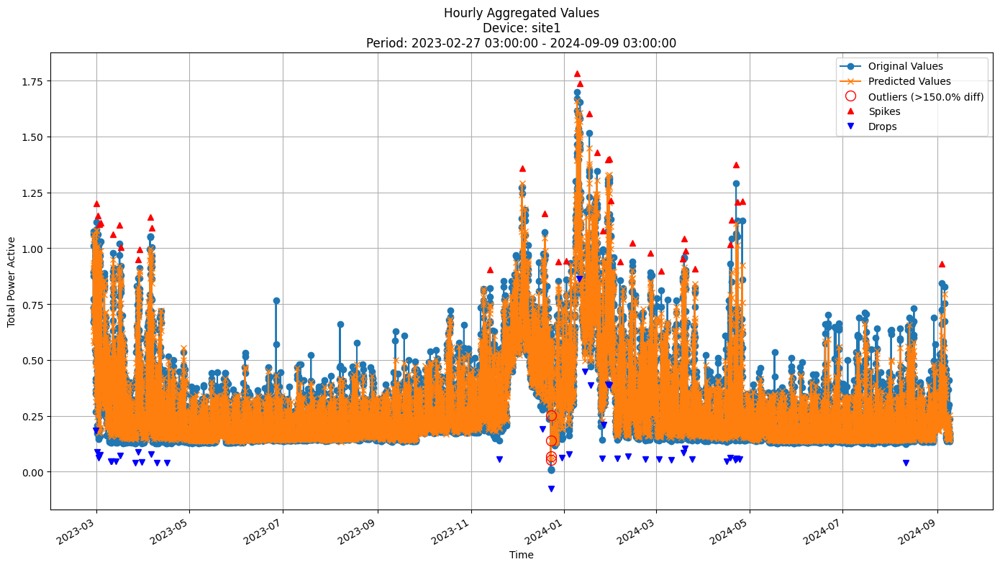


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0451
MAE: 0.0308
MAPE: 12.0722%

Directional Metrics:
Directional Accuracy: 67.7655%
First-Diff Correlation: 0.7361

Immediate Detection (delta=0):
Spikes:
  Precision: 0.5312
  Recall: 0.4474
  F1 Score: 0.4857
Drops:
  Precision: 0.3125
  Recall: 0.2500
  F1 Score: 0.2778

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7188
  Recall: 0.6053
  F1 Score: 0.6571
Drops:
  Precision: 0.6250
  Recall: 0.5000
  F1 Score: 0.5556


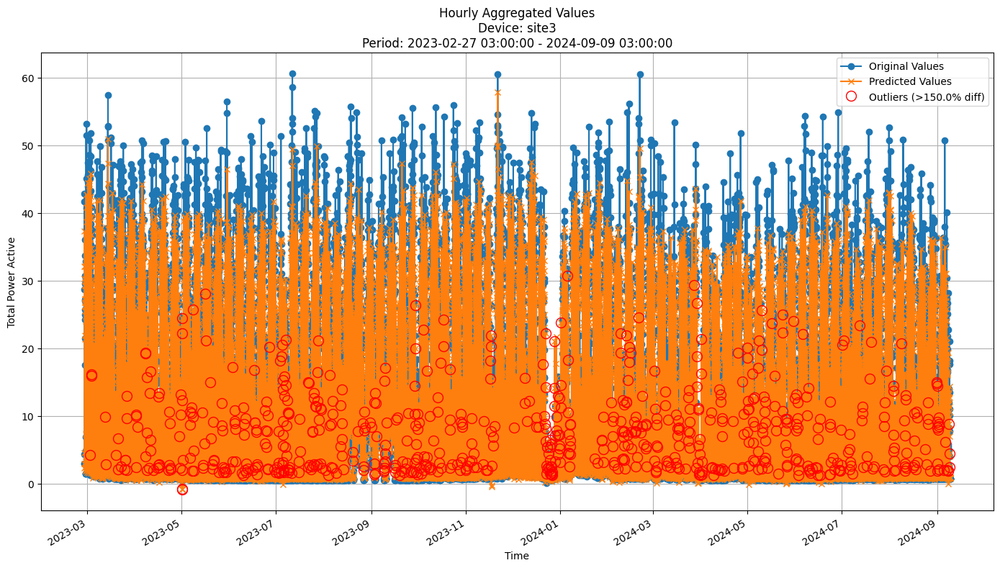


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 4.8573
MAE: 3.1908
MAPE: 46.5917%

Directional Metrics:
Directional Accuracy: 65.9424%
First-Diff Correlation: 0.7714

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


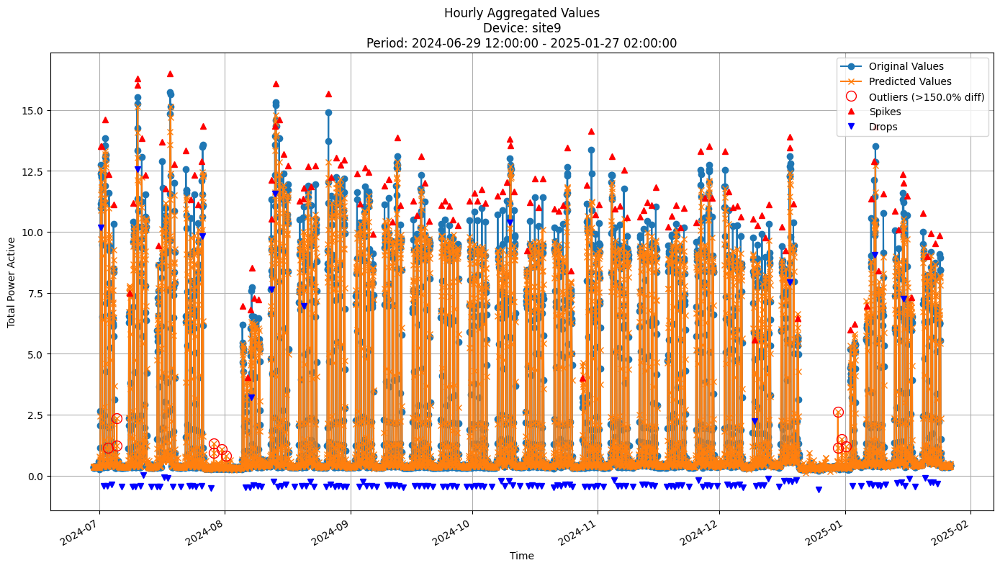


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3902
MAE: 0.2023
MAPE: 12.3190%

Directional Metrics:
Directional Accuracy: 69.9547%
First-Diff Correlation: 0.9513

Immediate Detection (delta=0):
Spikes:
  Precision: 0.4653
  Recall: 0.4527
  F1 Score: 0.4589
Drops:
  Precision: 0.1469
  Recall: 0.1419
  F1 Score: 0.1443

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5486
  Recall: 0.5338
  F1 Score: 0.5411
Drops:
  Precision: 0.3077
  Recall: 0.2973
  F1 Score: 0.3024


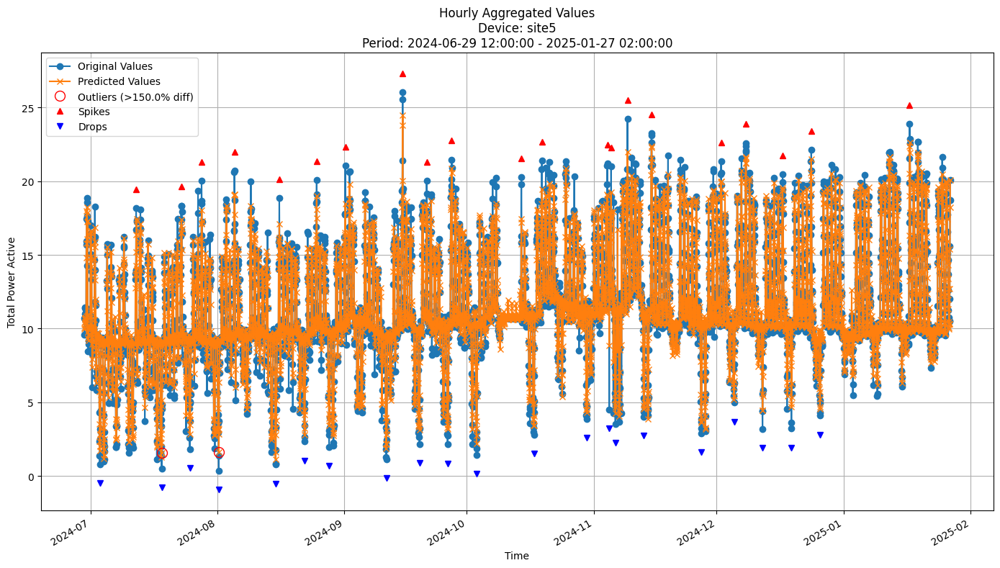


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.6940
MAE: 0.4975
MAPE: 5.2744%

Directional Metrics:
Directional Accuracy: 72.3961%
First-Diff Correlation: 0.8484

Immediate Detection (delta=0):
Spikes:
  Precision: 0.4167
  Recall: 0.2381
  F1 Score: 0.3030
Drops:
  Precision: 0.3077
  Recall: 0.1905
  F1 Score: 0.2353

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6667
  Recall: 0.3810
  F1 Score: 0.4848
Drops:
  Precision: 0.4615
  Recall: 0.2857
  F1 Score: 0.3529


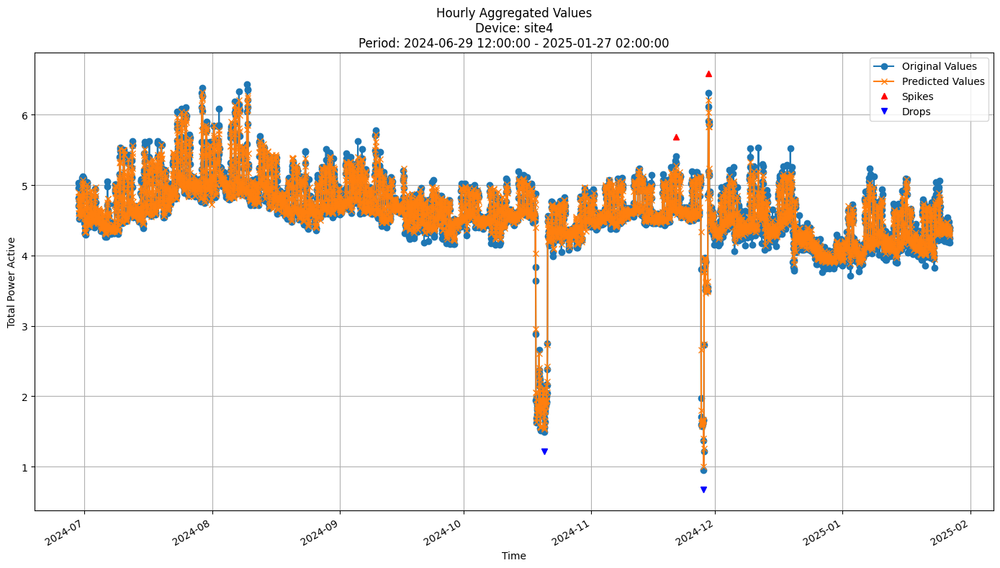


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0893
MAE: 0.0654
MAPE: 1.4240%

Directional Metrics:
Directional Accuracy: 65.8791%
First-Diff Correlation: 0.7297

Immediate Detection (delta=0):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


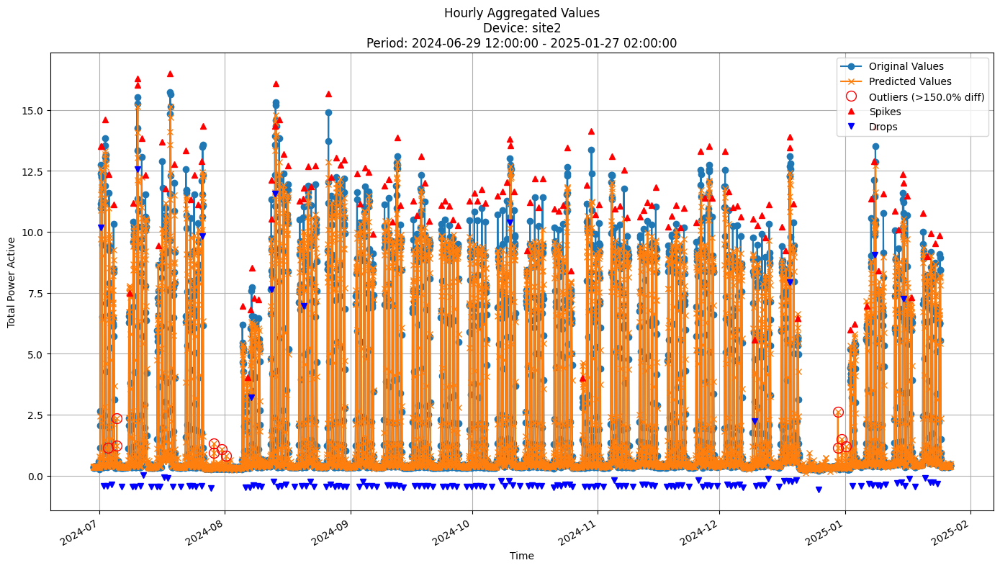


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3902
MAE: 0.2023
MAPE: 12.3190%

Directional Metrics:
Directional Accuracy: 69.9547%
First-Diff Correlation: 0.9513

Immediate Detection (delta=0):
Spikes:
  Precision: 0.4653
  Recall: 0.4527
  F1 Score: 0.4589
Drops:
  Precision: 0.1469
  Recall: 0.1419
  F1 Score: 0.1443

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5486
  Recall: 0.5338
  F1 Score: 0.5411
Drops:
  Precision: 0.3077
  Recall: 0.2973
  F1 Score: 0.3024


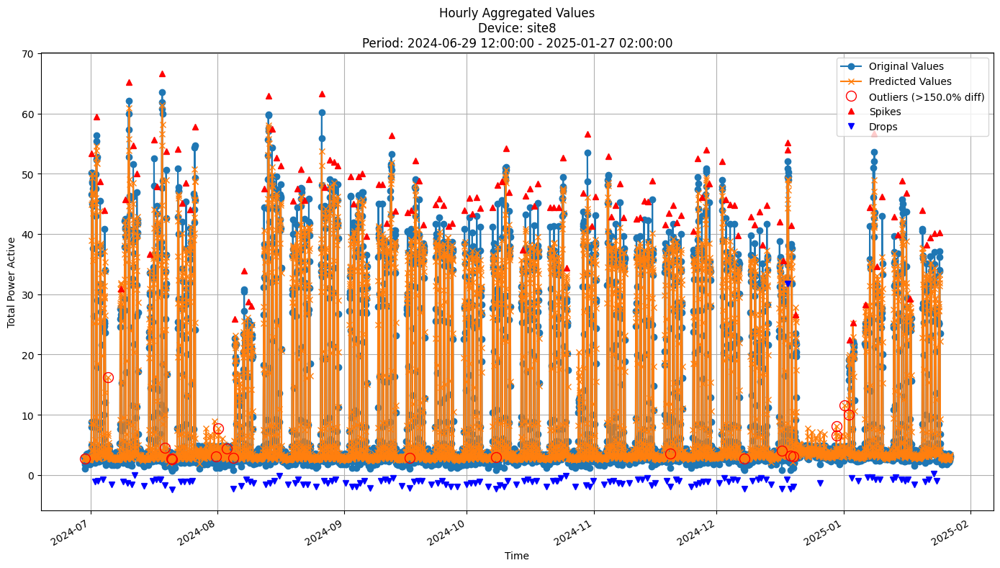


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.6407
MAE: 1.0232
MAPE: 16.5899%

Directional Metrics:
Directional Accuracy: 68.8718%
First-Diff Correlation: 0.9446

Immediate Detection (delta=0):
Spikes:
  Precision: 0.4929
  Recall: 0.5111
  F1 Score: 0.5018
Drops:
  Precision: 0.1727
  Recall: 0.1765
  F1 Score: 0.1745

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6214
  Recall: 0.6444
  F1 Score: 0.6327
Drops:
  Precision: 0.3381
  Recall: 0.3456
  F1 Score: 0.3418


In [18]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last few periods of predictions

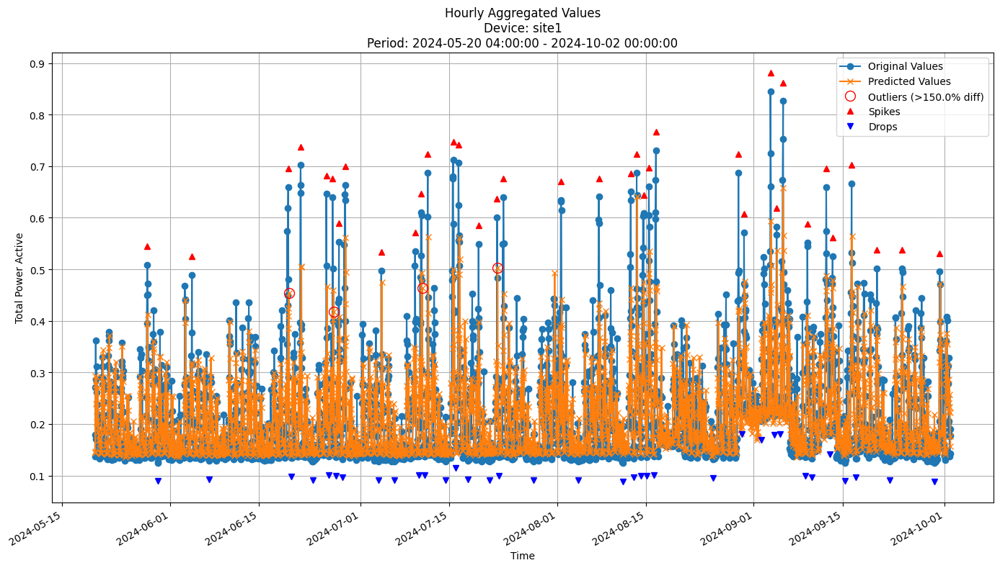


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0683
MAE: 0.0394
MAPE: 15.9561%

Directional Metrics:
Directional Accuracy: 59.7342%
First-Diff Correlation: 0.3901

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1250
  Recall: 0.0278
  F1 Score: 0.0455
Drops:
  Precision: 0.1429
  Recall: 0.0286
  F1 Score: 0.0476

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3750
  Recall: 0.0833
  F1 Score: 0.1364
Drops:
  Precision: 0.1429
  Recall: 0.0286
  F1 Score: 0.0476


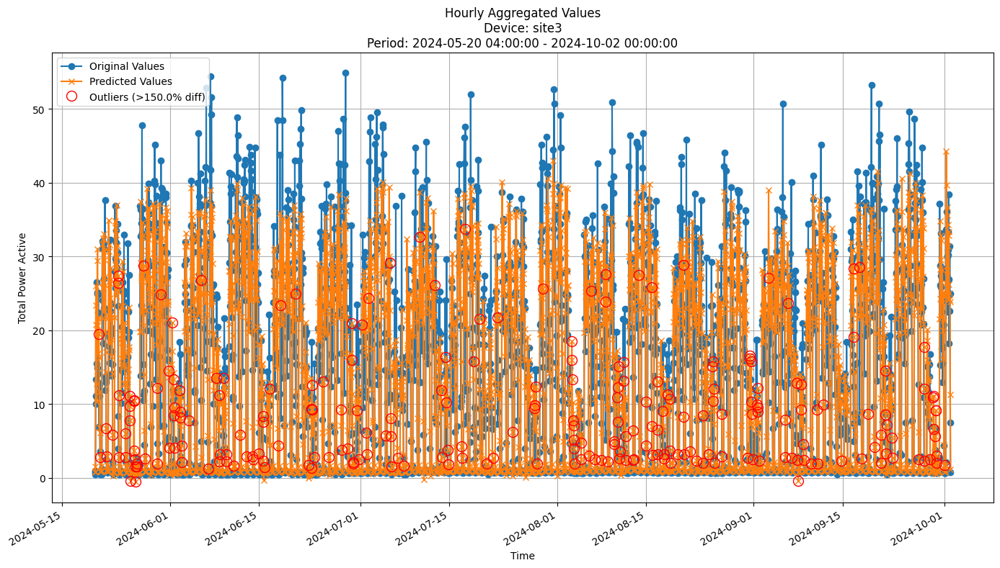


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 6.4393
MAE: 4.2467
MAPE: 55.9389%

Directional Metrics:
Directional Accuracy: 56.7676%
First-Diff Correlation: 0.5487

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


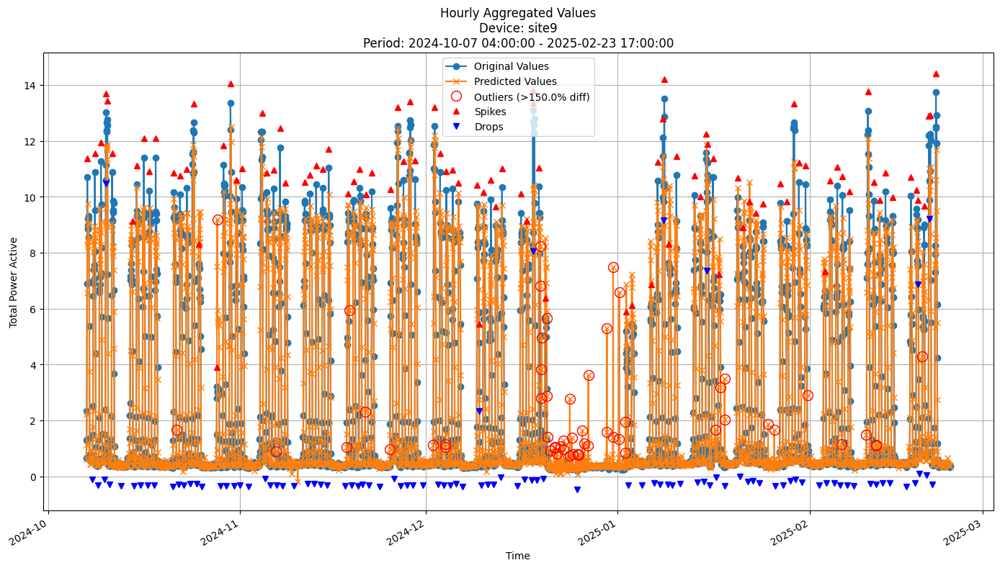


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.9416
MAE: 0.4529
MAPE: 23.6754%

Directional Metrics:
Directional Accuracy: 62.2687%
First-Diff Correlation: 0.7123

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0619
  Recall: 0.0707
  F1 Score: 0.0660
Drops:
  Precision: 0.0619
  Recall: 0.0714
  F1 Score: 0.0664

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2920
  Recall: 0.3333
  F1 Score: 0.3113
Drops:
  Precision: 0.1593
  Recall: 0.1837
  F1 Score: 0.1706


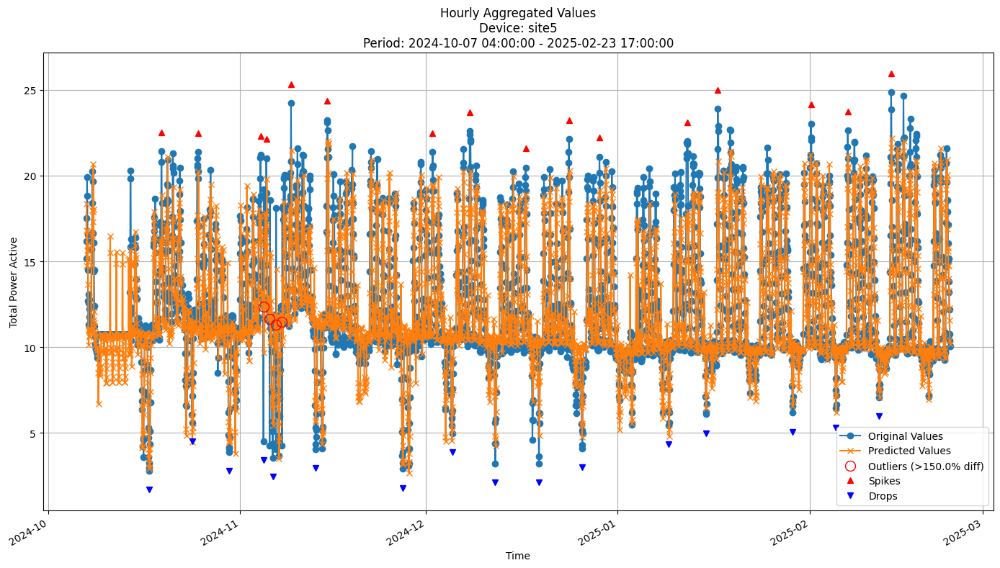


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.5887
MAE: 1.0574
MAPE: 8.6733%

Directional Metrics:
Directional Accuracy: 60.8358%
First-Diff Correlation: 0.3670

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0909
  Recall: 0.0625
  F1 Score: 0.0741

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.4545
  Recall: 0.3125
  F1 Score: 0.3704


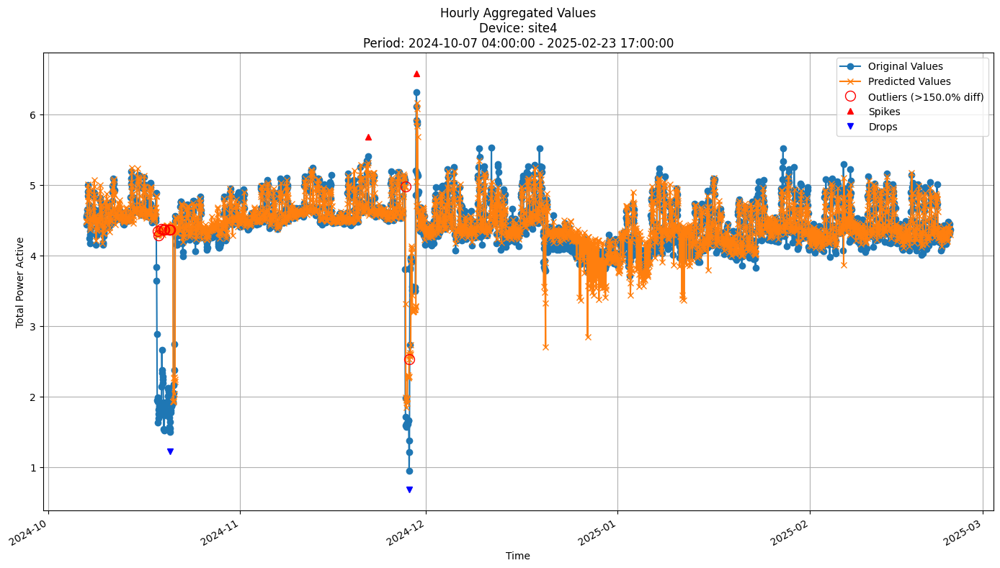


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3998
MAE: 0.1756
MAPE: 5.6179%

Directional Metrics:
Directional Accuracy: 53.4627%
First-Diff Correlation: 0.0957

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2500
  Recall: 0.5000
  F1 Score: 0.3333
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2500
  Recall: 0.5000
  F1 Score: 0.3333
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


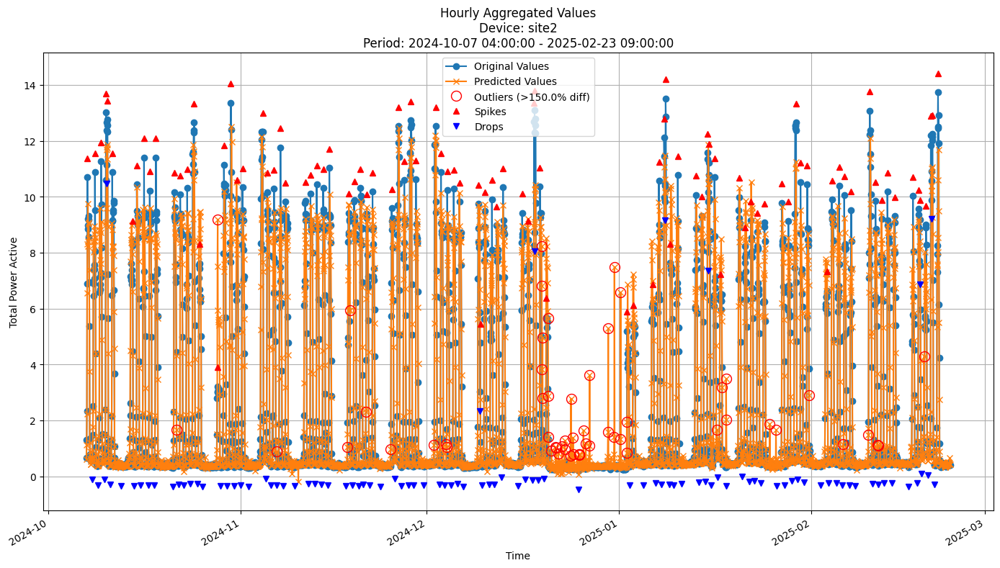


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.9427
MAE: 0.4539
MAPE: 23.7074%

Directional Metrics:
Directional Accuracy: 62.2980%
First-Diff Correlation: 0.7123

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0631
  Recall: 0.0707
  F1 Score: 0.0667
Drops:
  Precision: 0.0631
  Recall: 0.0714
  F1 Score: 0.0670

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2793
  Recall: 0.3131
  F1 Score: 0.2952
Drops:
  Precision: 0.1622
  Recall: 0.1837
  F1 Score: 0.1722


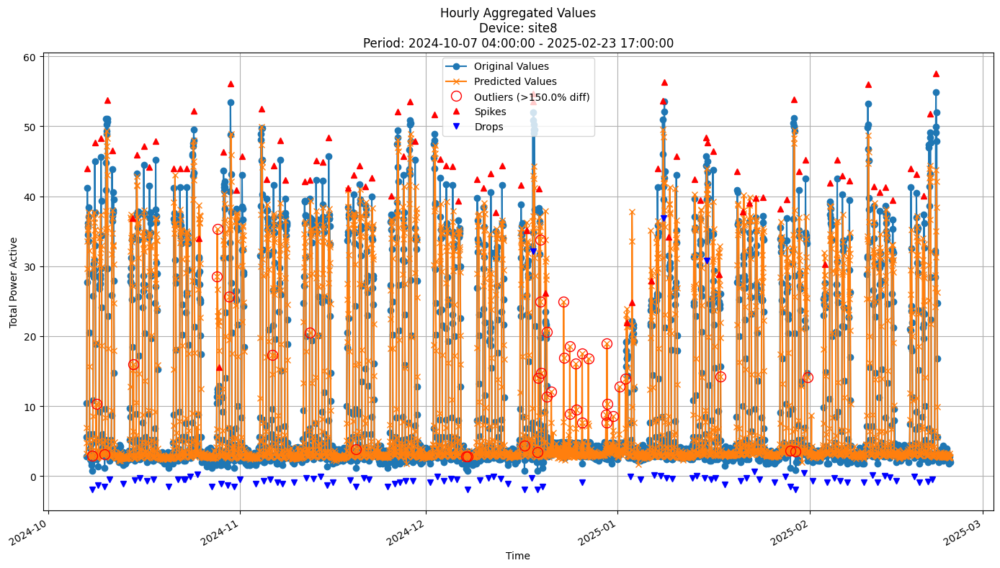


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 3.8693
MAE: 2.0415
MAPE: 23.8720%

Directional Metrics:
Directional Accuracy: 58.0896%
First-Diff Correlation: 0.6864

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0579
  Recall: 0.0737
  F1 Score: 0.0648
Drops:
  Precision: 0.1000
  Recall: 0.1263
  F1 Score: 0.1116

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1983
  Recall: 0.2526
  F1 Score: 0.2222
Drops:
  Precision: 0.1917
  Recall: 0.2421
  F1 Score: 0.2140


In [19]:
join_periods = [-5, -4, -3, -2, -1]
# Device iteration
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Random Forest model

In [20]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor
rf_params = {
    'n_estimators': 300, 
     'max_depth': 20, 
     'max_features': 0.7, 
     'random_state': 42, 
     'n_jobs': -1
}

In [21]:
rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=rf, 
    model_params=rf_params,
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]


Retraining model on data from 2023-02-27 03:00:00+01:00 to 2023-03-27 03:00:00+02:00

Time: 0.30 seconds
Predicting for chunk from 2023-03-27 04:00:00+02:00 to 2023-04-10 04:00:00+02:00

-------------------------

Retraining model on data from 2023-02-27 03:00:00+01:00 to 2023-04-10 04:00:00+02:00

Time: 0.37 seconds
Predicting for chunk from 2023-04-10 05:00:00+02:00 to 2023-04-24 03:00:00+02:00

-------------------------
Model's memory usage: 0.119949 MB
Metrics for Device: site1 | Period: 2023-03-27 04:00:00+02:00 - 2023-04-24 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0781
	MAE: 0.0598
	MAPE: 24.8769%

Directional Metrics:
	Directional Accuracy: 57.9732%
	First-Diff Correlation: 0.3682

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0909
		Recall: 0.0870
		F1: 0.0889
	Drops:
		Precision: 0.0952
		Recall: 0.0909
		F1: 0.0930

Delayed Detection (delta=

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]


Retraining model on data from 2023-02-27 03:00:00+01:00 to 2023-04-24 03:00:00+02:00

Time: 0.31 seconds
Predicting for chunk from 2023-04-24 04:00:00+02:00 to 2023-05-08 04:00:00+02:00

-------------------------

Retraining model on data from 2023-02-27 03:00:00+01:00 to 2023-05-08 04:00:00+02:00

Time: 0.31 seconds
Predicting for chunk from 2023-05-08 05:00:00+02:00 to 2023-05-22 03:00:00+02:00

-------------------------
Model's memory usage: 0.119942 MB
Metrics for Device: site1 | Period: 2023-04-24 04:00:00+02:00 - 2023-05-22 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0483
	MAE: 0.0353
	MAPE: 18.4064%

Directional Metrics:
	Directional Accuracy: 56.1848%
	First-Diff Correlation: 0.2761

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2500
		Recall: 0.1395
		F1: 0.1791
	Drops:
		Precision: 0.1304
		Recall: 0.0652
		F1: 0.0870

Delayed Detection (delta=

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]


Retraining model on data from 2024-06-29 12:00:00+02:00 to 2024-12-30 02:00:00+01:00

Time: 0.47 seconds
Predicting for chunk from 2024-12-30 03:00:00+01:00 to 2025-01-13 03:00:00+01:00

-------------------------

Retraining model on data from 2024-06-29 12:00:00+02:00 to 2025-01-13 03:00:00+01:00

Time: 0.49 seconds
Predicting for chunk from 2025-01-13 04:00:00+01:00 to 2025-01-27 02:00:00+01:00

-------------------------
Model's memory usage: 0.119942 MB
Metrics for Device: site9 | Period: 2024-12-30 03:00:00+01:00 - 2025-01-27 02:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.9681
	MAE: 0.4737
	MAPE: 26.1334%

Directional Metrics:
	Directional Accuracy: 60.3577%
	First-Diff Correlation: 0.6845

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0345
		Recall: 0.0333
		F1: 0.0339
	Drops:
		Precision: 0.0357
		Recall: 0.0345
		F1: 0.0351

Delayed Detection (delta=

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]


Retraining model on data from 2024-06-29 12:00:00+02:00 to 2025-01-27 02:00:00+01:00

Time: 0.59 seconds
Predicting for chunk from 2025-01-27 03:00:00+01:00 to 2025-02-10 03:00:00+01:00

-------------------------

Retraining model on data from 2024-06-29 12:00:00+02:00 to 2025-02-10 03:00:00+01:00

Time: 0.57 seconds
Predicting for chunk from 2025-02-10 04:00:00+01:00 to 2025-02-23 17:00:00+01:00

-------------------------
Model's memory usage: 0.119942 MB
Metrics for Device: site9 | Period: 2025-01-27 03:00:00+01:00 - 2025-02-23 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.9591
	MAE: 0.4679
	MAPE: 18.4136%

Directional Metrics:
	Directional Accuracy: 59.3656%
	First-Diff Correlation: 0.7114

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0909
		Recall: 0.1071
		F1: 0.0984
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=

#### Results

In [22]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0229 ± 0.0023
	MAE: 0.0157 ± 0.0023
	MAPE: 6.2018% ± 0.5509%

	Directional Metrics:
		Directional Accuracy: 86.8887% ± 0.4377%
		First-Diff Correlation: 0.9514 ± 0.0057

	Immediate Detection (delta=0):
		Spike Precision: 0.7931 ± 0.0541
		Spike Recall: 0.6405 ± 0.0726
		Spike F1: 0.7068 ± 0.0538
		Drop Precision: 0.5176 ± 0.0697
		Drop Recall: 0.4065 ± 0.0927
		Drop F1: 0.4543 ± 0.0837

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8543 ± 0.0551
		Spike Recall: 0.6903 ± 0.0826
		Spike F1: 0.7616 ± 0.0611
		Drop Precision: 0.6444 ± 0.0736
		Drop Recall: 0.5052 ± 0.1048
		Drop F1: 0.5650 ± 0.0923
Daily Metrics:
	RMSE: 0.1604 ± 0.0219
	MAE: 0.1235 ± 0.0207
	MAPE: 1.8947% ± 0.1720%

	Directional Metrics:
		Directional Accuracy: 96.9371% ± 1.1511%
		First-Diff Correlation: 0.9943 ± 0.0016

	Immediate Detection (delta=0):
		Spike

#### Training plots
Plot only the last period of predictions

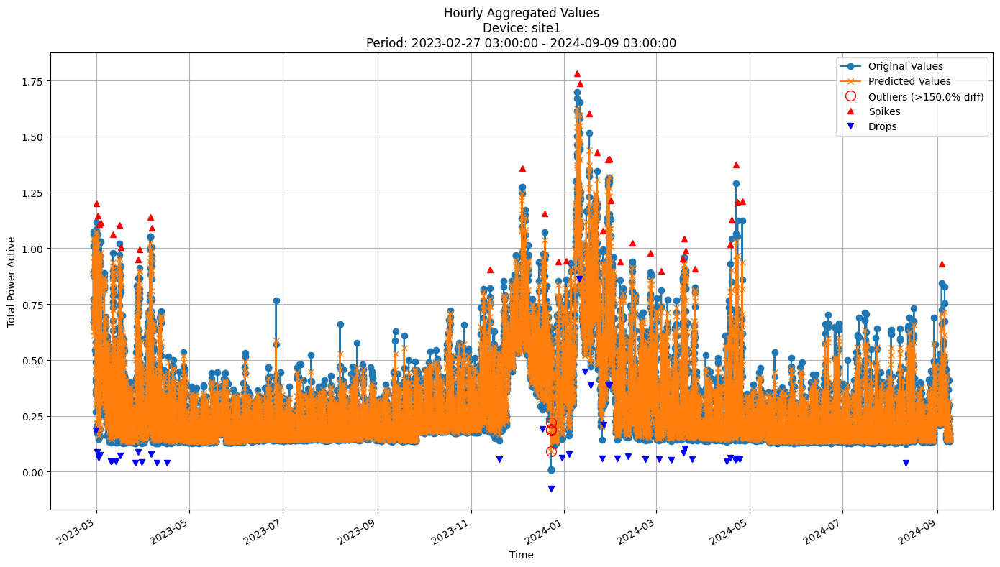


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0247
MAE: 0.0163
MAPE: 6.4343%

Directional Metrics:
Directional Accuracy: 86.5689%
First-Diff Correlation: 0.9440

Immediate Detection (delta=0):
Spikes:
  Precision: 0.7778
  Recall: 0.5526
  F1 Score: 0.6462
Drops:
  Precision: 0.5556
  Recall: 0.3750
  F1 Score: 0.4478

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8148
  Recall: 0.5789
  F1 Score: 0.6769
Drops:
  Precision: 0.6667
  Recall: 0.4500
  F1 Score: 0.5373


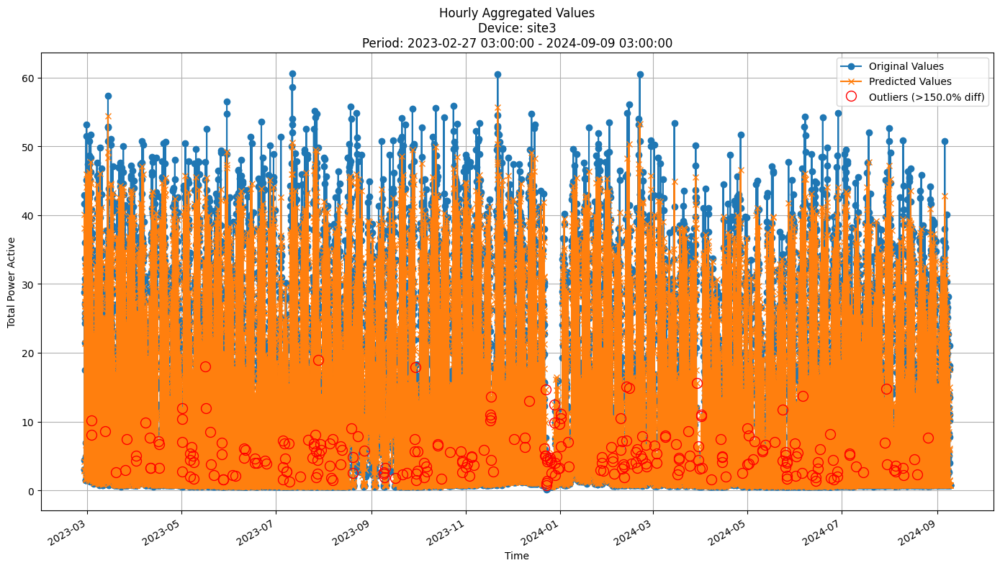


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.5703
MAE: 1.6671
MAPE: 21.8148%

Directional Metrics:
Directional Accuracy: 80.4673%
First-Diff Correlation: 0.9528

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


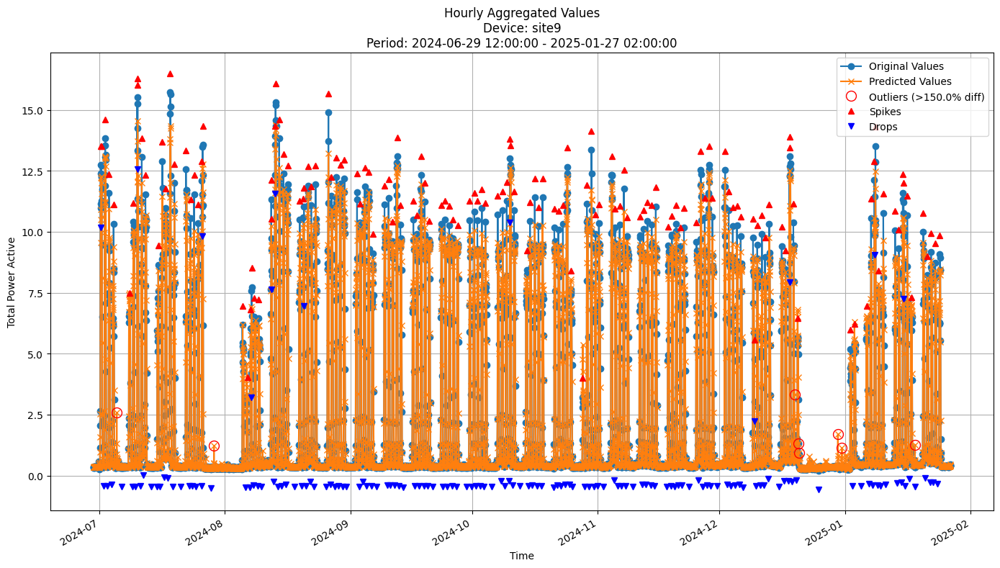


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3198
MAE: 0.1462
MAPE: 6.8017%

Directional Metrics:
Directional Accuracy: 86.7690%
First-Diff Correlation: 0.9704

Immediate Detection (delta=0):
Spikes:
  Precision: 0.6643
  Recall: 0.6419
  F1 Score: 0.6529
Drops:
  Precision: 0.4507
  Recall: 0.4324
  F1 Score: 0.4414

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7692
  Recall: 0.7432
  F1 Score: 0.7560
Drops:
  Precision: 0.5634
  Recall: 0.5405
  F1 Score: 0.5517


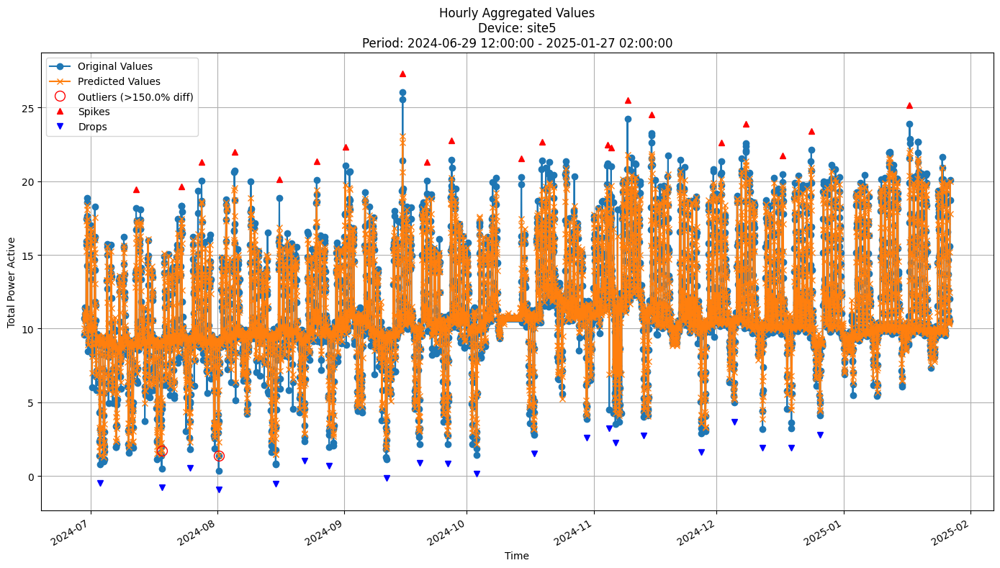


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.4945
MAE: 0.3299
MAPE: 3.5190%

Directional Metrics:
Directional Accuracy: 84.2882%
First-Diff Correlation: 0.9367

Immediate Detection (delta=0):
Spikes:
  Precision: 0.6364
  Recall: 0.3333
  F1 Score: 0.4375
Drops:
  Precision: 0.4167
  Recall: 0.2381
  F1 Score: 0.3030

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7273
  Recall: 0.3810
  F1 Score: 0.5000
Drops:
  Precision: 0.5833
  Recall: 0.3333
  F1 Score: 0.4242


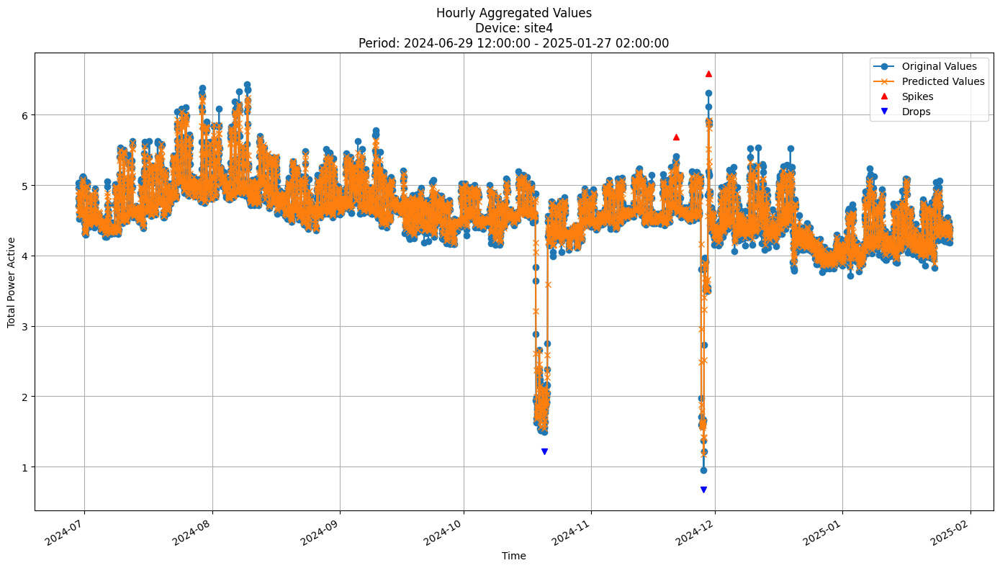


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0620
MAE: 0.0392
MAPE: 0.8866%

Directional Metrics:
Directional Accuracy: 84.5836%
First-Diff Correlation: 0.9221

Immediate Detection (delta=0):
Spikes:
  Precision: 1.0000
  Recall: 0.5000
  F1 Score: 0.6667
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 0.5000
  F1 Score: 0.6667
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


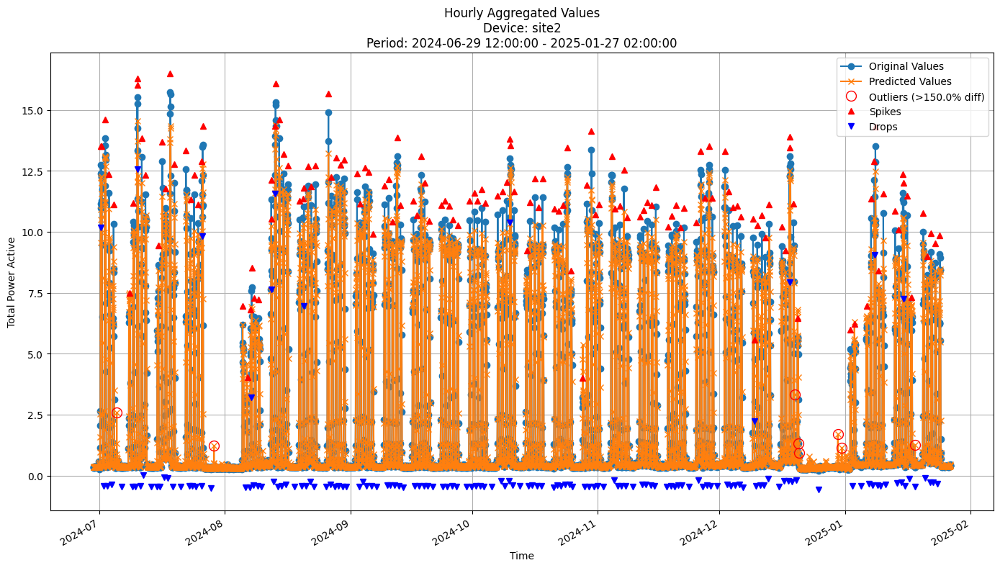


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3198
MAE: 0.1462
MAPE: 6.8016%

Directional Metrics:
Directional Accuracy: 86.7690%
First-Diff Correlation: 0.9704

Immediate Detection (delta=0):
Spikes:
  Precision: 0.6643
  Recall: 0.6419
  F1 Score: 0.6529
Drops:
  Precision: 0.4507
  Recall: 0.4324
  F1 Score: 0.4414

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7692
  Recall: 0.7432
  F1 Score: 0.7560
Drops:
  Precision: 0.5634
  Recall: 0.5405
  F1 Score: 0.5517


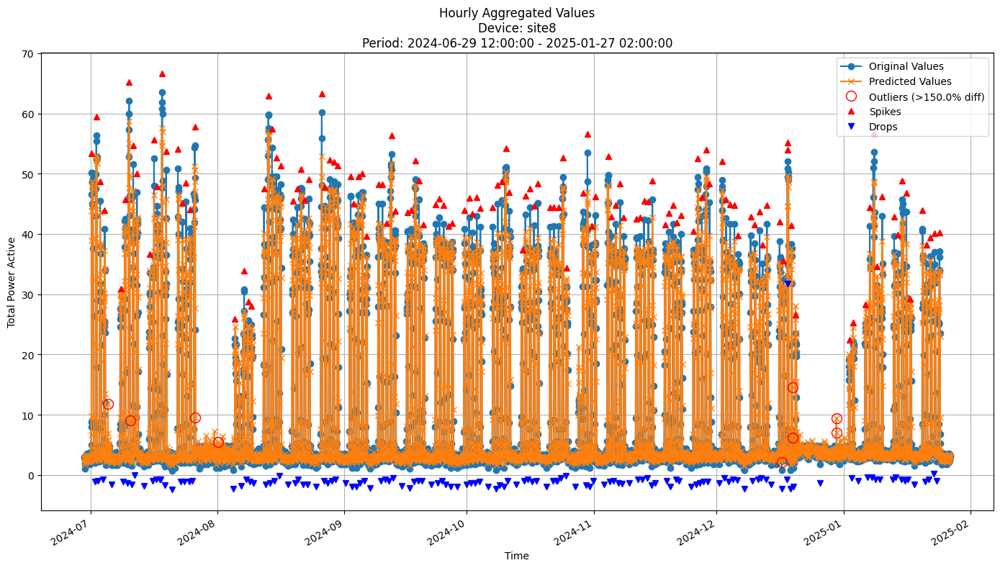


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.3243
MAE: 0.7010
MAPE: 9.1182%

Directional Metrics:
Directional Accuracy: 89.9390%
First-Diff Correlation: 0.9690

Immediate Detection (delta=0):
Spikes:
  Precision: 0.5797
  Recall: 0.5926
  F1 Score: 0.5861
Drops:
  Precision: 0.7372
  Recall: 0.7426
  F1 Score: 0.7399

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7101
  Recall: 0.7259
  F1 Score: 0.7179
Drops:
  Precision: 0.7591
  Recall: 0.7647
  F1 Score: 0.7619


In [23]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last periods of predictions

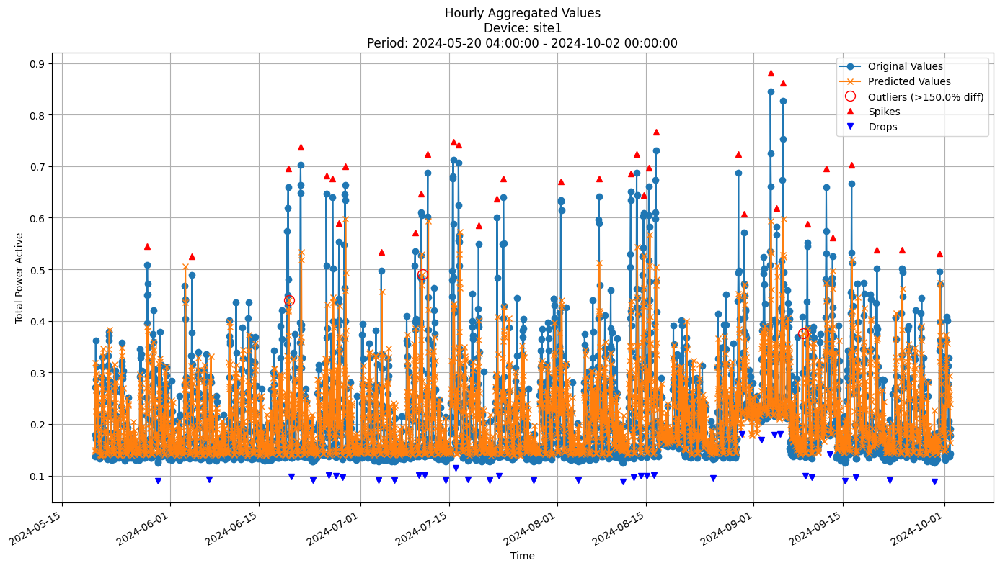


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0689
MAE: 0.0405
MAPE: 16.7661%

Directional Metrics:
Directional Accuracy: 57.6947%
First-Diff Correlation: 0.3488

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.4000
  Recall: 0.0556
  F1 Score: 0.0976
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


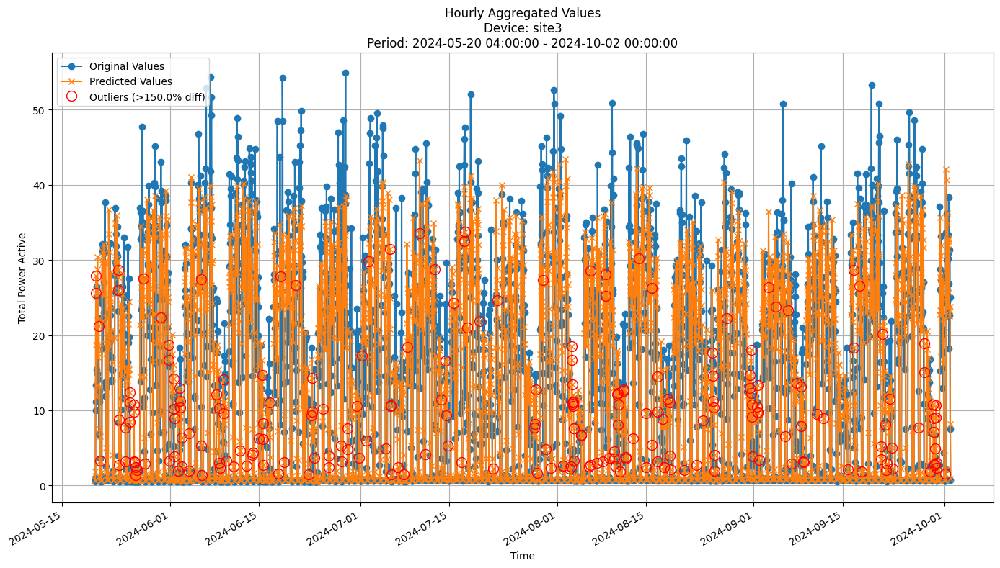


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 6.5607
MAE: 4.3033
MAPE: 52.8191%

Directional Metrics:
Directional Accuracy: 56.2732%
First-Diff Correlation: 0.5323

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


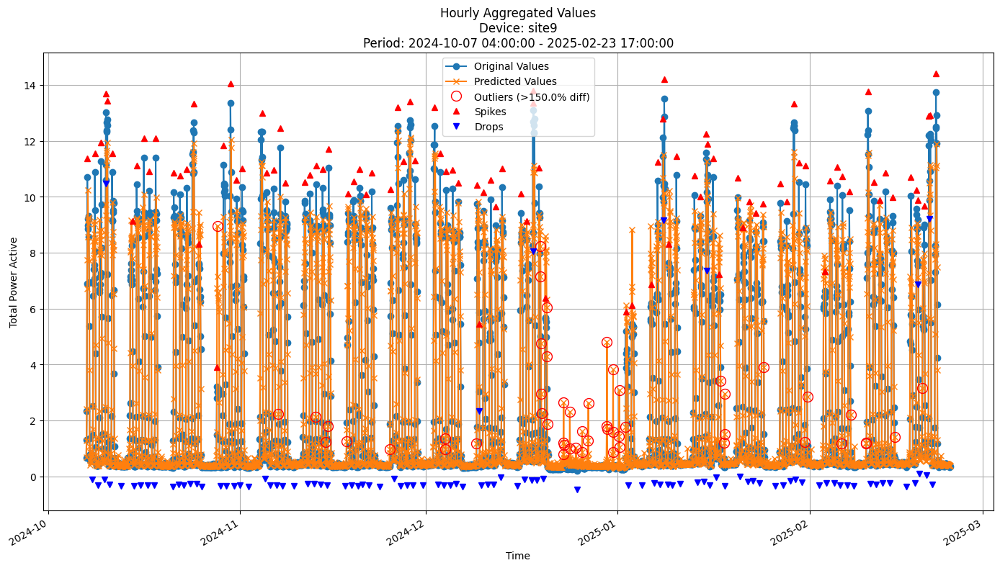


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.9244
MAE: 0.4468
MAPE: 22.7806%

Directional Metrics:
Directional Accuracy: 62.6567%
First-Diff Correlation: 0.7398

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0971
  Recall: 0.1010
  F1 Score: 0.0990
Drops:
  Precision: 0.0588
  Recall: 0.0612
  F1 Score: 0.0600

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2524
  Recall: 0.2626
  F1 Score: 0.2574
Drops:
  Precision: 0.1667
  Recall: 0.1735
  F1 Score: 0.1700


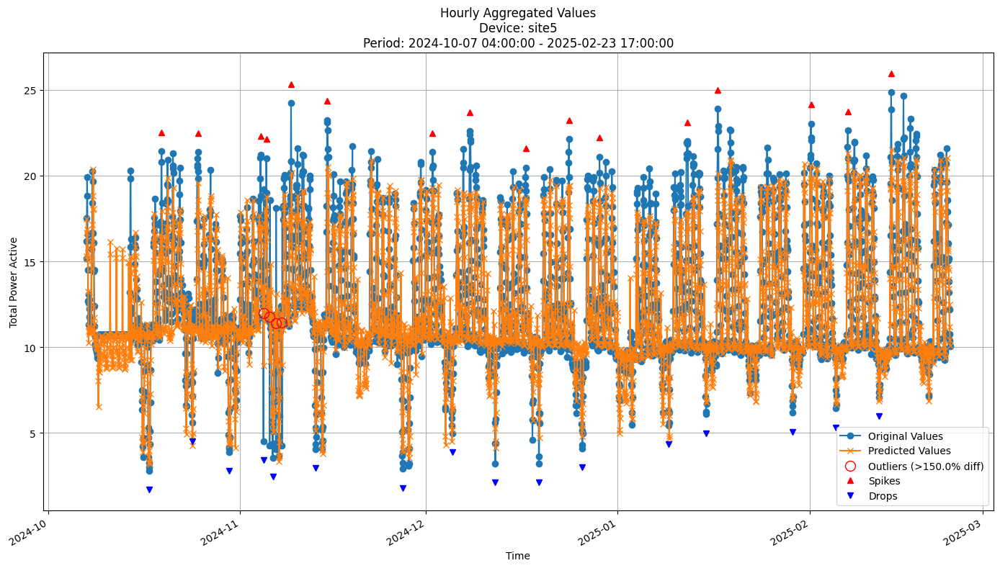


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.5869
MAE: 1.0626
MAPE: 8.6158%

Directional Metrics:
Directional Accuracy: 61.6119%
First-Diff Correlation: 0.3901

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.2000
  Recall: 0.0625
  F1 Score: 0.0952


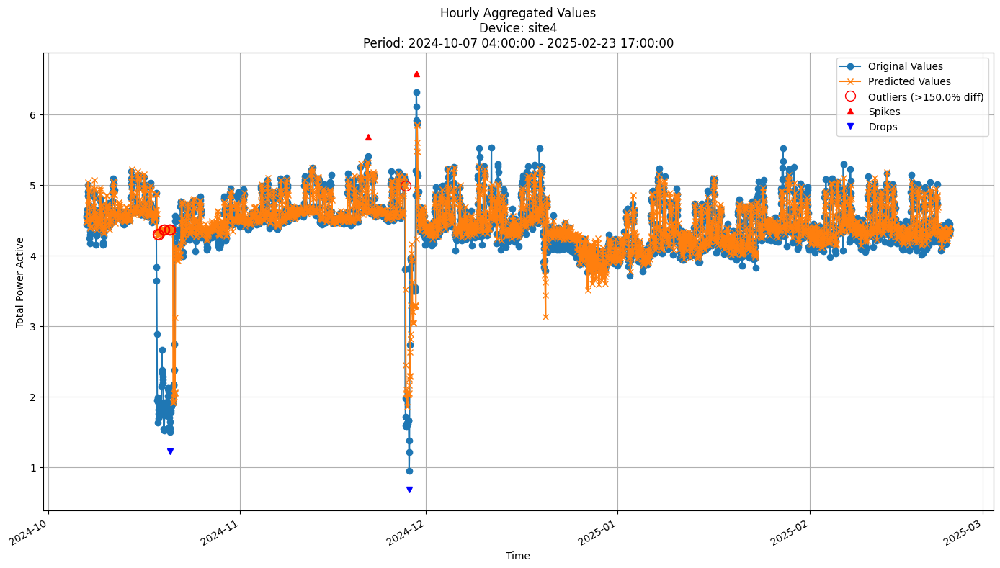


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3969
MAE: 0.1722
MAPE: 5.4989%

Directional Metrics:
Directional Accuracy: 53.1940%
First-Diff Correlation: 0.0938

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


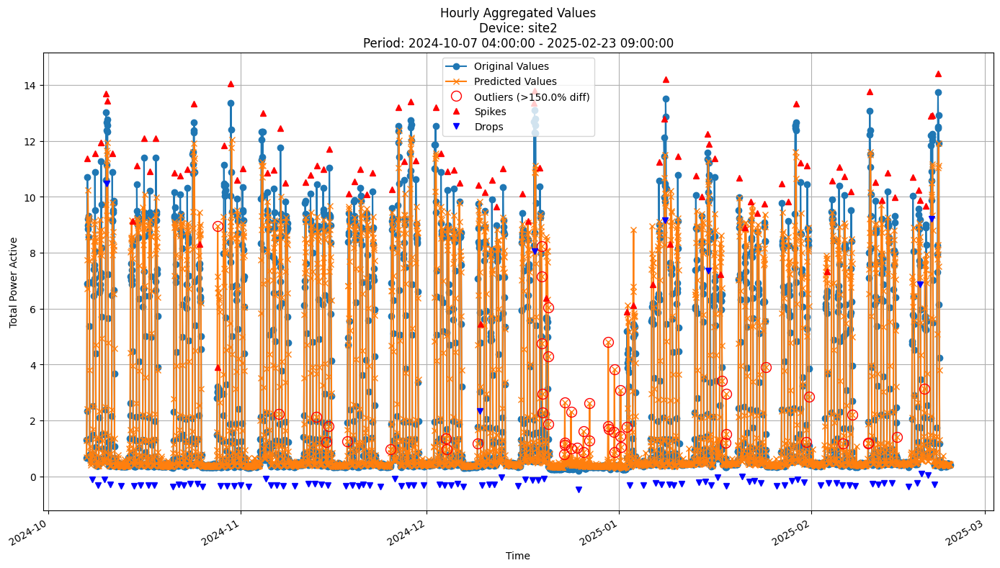


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.9255
MAE: 0.4478
MAPE: 22.8104%

Directional Metrics:
Directional Accuracy: 62.6870%
First-Diff Correlation: 0.7398

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0971
  Recall: 0.1010
  F1 Score: 0.0990
Drops:
  Precision: 0.0588
  Recall: 0.0612
  F1 Score: 0.0600

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2524
  Recall: 0.2626
  F1 Score: 0.2574
Drops:
  Precision: 0.1667
  Recall: 0.1735
  F1 Score: 0.1700


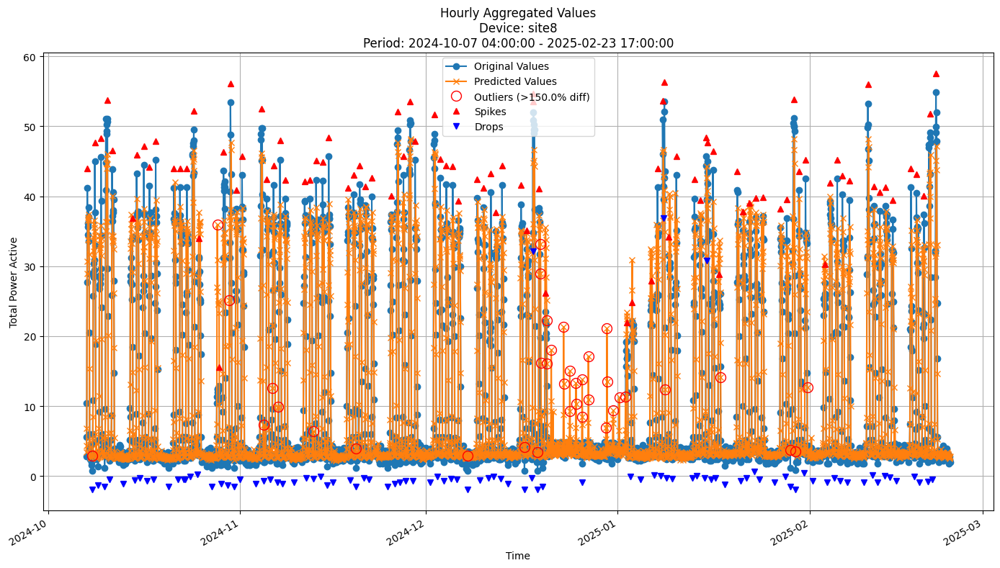


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 3.8397
MAE: 2.0143
MAPE: 23.8260%

Directional Metrics:
Directional Accuracy: 58.5970%
First-Diff Correlation: 0.7078

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0755
  Recall: 0.0842
  F1 Score: 0.0796
Drops:
  Precision: 0.0857
  Recall: 0.0947
  F1 Score: 0.0900

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1604
  Recall: 0.1789
  F1 Score: 0.1692
Drops:
  Precision: 0.1810
  Recall: 0.2000
  F1 Score: 0.1900


In [24]:
join_periods = [-5, -4, -3, -2, -1]
# Device iteration
for device_id in rf_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Hoeffding Tree

In [25]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

hoef = HoeffdingTreeRegressor
hoef_params = {
    'max_depth': 15, 
     'grace_period': 10, 
     'tau': 0.1, 
     'delta': 0.01,
    'leaf_prediction': 'mean'
}

In [26]:
hoef_all_train_preds, hoef_all_valid_preds, \
hoef_all_train_metrics, hoef_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=hoef, 
    model_params=hoef_params,
    train=train, 
    valid=valid, 
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 03:00:00+01:00 to 2023-03-27 03:00:00+02:00
Model's memory usage: 0.356728 MB
Metrics for Device: site1 | Period: 2023-03-27 04:00:00+02:00 - 2023-04-24 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1032
	MAE: 0.0767
	MAPE: 29.5006%

Directional Metrics:
	Directional Accuracy: 53.2042%
	First-Diff Correlation: 0.3351

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1786
		Recall: 0.2174
		F1: 0.1961
	Drops:
		Precision: 0.1111
		Recall: 0.1364
		F1: 0.1224

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2857
		Recall: 0.3478
		F1: 0.3137
	Drops:
		Precision: 0.2222
		Recall: 0.2727
		F1: 0.2449
--------------------------------------------------
Dai

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 03:00:00+01:00 to 2023-04-24 03:00:00+02:00
Model's memory usage: 0.500450 MB
Metrics for Device: site1 | Period: 2023-04-24 04:00:00+02:00 - 2023-05-22 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0638
	MAE: 0.0415
	MAPE: 22.4879%

Directional Metrics:
	Directional Accuracy: 52.4590%
	First-Diff Correlation: 0.4407

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1800
		Recall: 0.2093
		F1: 0.1935
	Drops:
		Precision: 0.0204
		Recall: 0.0217
		F1: 0.0211

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3600
		Recall: 0.4186
		F1: 0.3871
	Drops:
		Precision: 0.3265
		Recall: 0.3478
		F1: 0.3368
--------------------------------------------------
Dai

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 12:00:00+02:00 to 2024-12-30 02:00:00+01:00
Model's memory usage: 1.601738 MB
Metrics for Device: site9 | Period: 2024-12-30 03:00:00+01:00 - 2025-01-27 02:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.2812
	MAE: 0.5913
	MAPE: 42.1844%

Directional Metrics:
	Directional Accuracy: 53.0551%
	First-Diff Correlation: 0.3833

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0930
		Recall: 0.1333
		F1: 0.1096
	Drops:
		Precision: 0.0476
		Recall: 0.0690
		F1: 0.0563

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2791
		Recall: 0.4000
		F1: 0.3288
	Drops:
		Precision: 0.0952
		Recall: 0.1379
		F1: 0.1127
--------------------------------------------------
Dai

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 12:00:00+02:00 to 2025-01-27 02:00:00+01:00
Model's memory usage: 1.905075 MB
Metrics for Device: site9 | Period: 2025-01-27 03:00:00+01:00 - 2025-02-23 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.1970
	MAE: 0.5601
	MAPE: 25.1442%

Directional Metrics:
	Directional Accuracy: 56.3444%
	First-Diff Correlation: 0.4795

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1220
		Recall: 0.1786
		F1: 0.1449
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2439
		Recall: 0.3571
		F1: 0.2899
	Drops:
		Precision: 0.1250
		Recall: 0.1852
		F1: 0.1493
--------------------------------------------------
Dai

#### Results

In [27]:
print("\n\nTrain period metrics:")
hoef_all_time_train_metrics = all_time_aggregation_metrics(hoef_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
hoef_all_time_valid_metrics = all_time_aggregation_metrics(hoef_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0943 ± 0.0181
	MAE: 0.0628 ± 0.0160
	MAPE: 22.9593% ± 5.3174%

	Directional Metrics:
		Directional Accuracy: 42.0072% ± 5.3217%
		First-Diff Correlation: 0.3804 ± 0.0797

	Immediate Detection (delta=0):
		Spike Precision: 0.1354 ± 0.0797
		Spike Recall: 0.1609 ± 0.1107
		Spike F1: 0.1448 ± 0.0892
		Drop Precision: 0.0828 ± 0.0247
		Drop Recall: 0.1041 ± 0.0392
		Drop F1: 0.0907 ± 0.0270

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3209 ± 0.0616
		Spike Recall: 0.3840 ± 0.0940
		Spike F1: 0.3449 ± 0.0625
		Drop Precision: 0.2207 ± 0.0444
		Drop Recall: 0.2780 ± 0.0858
		Drop F1: 0.2418 ± 0.0491
Daily Metrics:
	RMSE: 1.0925 ± 0.2815
	MAE: 0.6926 ± 0.2554
	MAPE: 9.9853% ± 3.9812%

	Directional Metrics:
		Directional Accuracy: 85.7140% ± 4.1799%
		First-Diff Correlation: 0.9040 ± 0.0212

	Immediate Detection (delta=0):
		Spik

#### Training plots
Plot only the last period of predictions

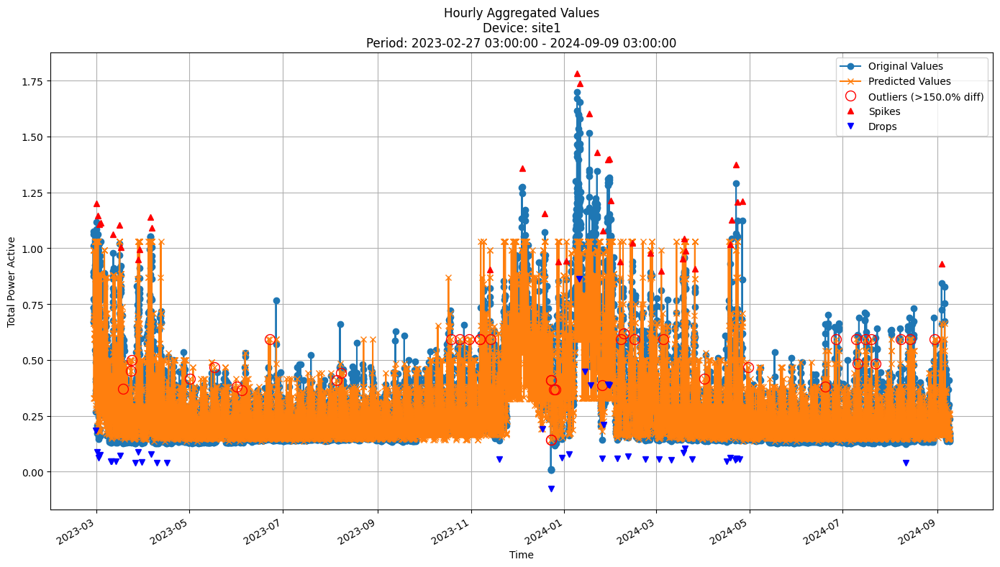


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0982
MAE: 0.0628
MAPE: 22.0876%

Directional Metrics:
Directional Accuracy: 43.7309%
First-Diff Correlation: 0.3229

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0375
  Recall: 0.0789
  F1 Score: 0.0508
Drops:
  Precision: 0.0707
  Recall: 0.1750
  F1 Score: 0.1007

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2000
  Recall: 0.4211
  F1 Score: 0.2712
Drops:
  Precision: 0.1414
  Recall: 0.3500
  F1 Score: 0.2014


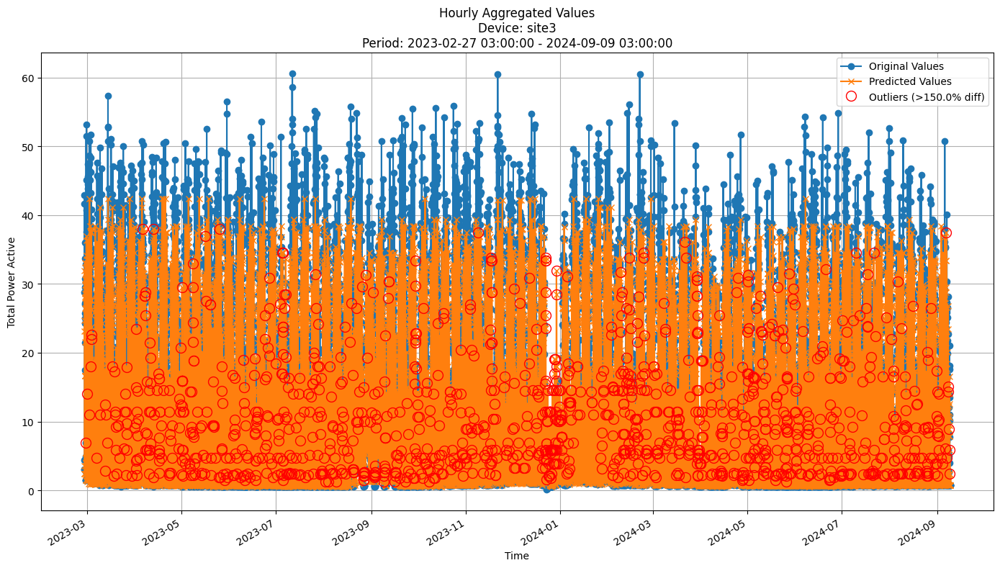


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 7.3418
MAE: 4.8749
MAPE: 89.8835%

Directional Metrics:
Directional Accuracy: 53.5084%
First-Diff Correlation: 0.4309

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


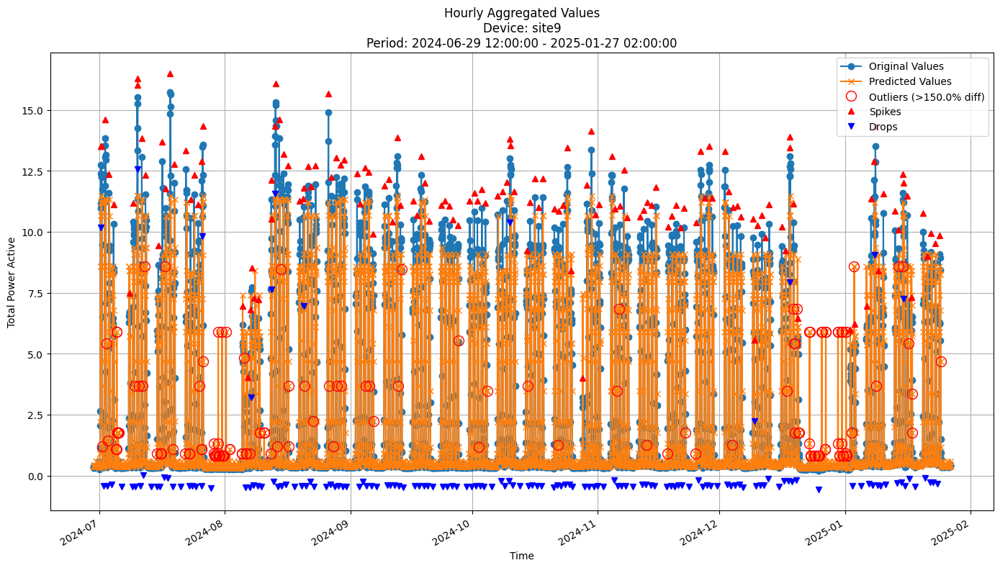


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.0934
MAE: 0.5146
MAPE: 30.0383%

Directional Metrics:
Directional Accuracy: 43.4534%
First-Diff Correlation: 0.6384

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0595
  Recall: 0.0743
  F1 Score: 0.0661
Drops:
  Precision: 0.0657
  Recall: 0.0878
  F1 Score: 0.0751

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1568
  Recall: 0.1959
  F1 Score: 0.1742
Drops:
  Precision: 0.1970
  Recall: 0.2635
  F1 Score: 0.2254


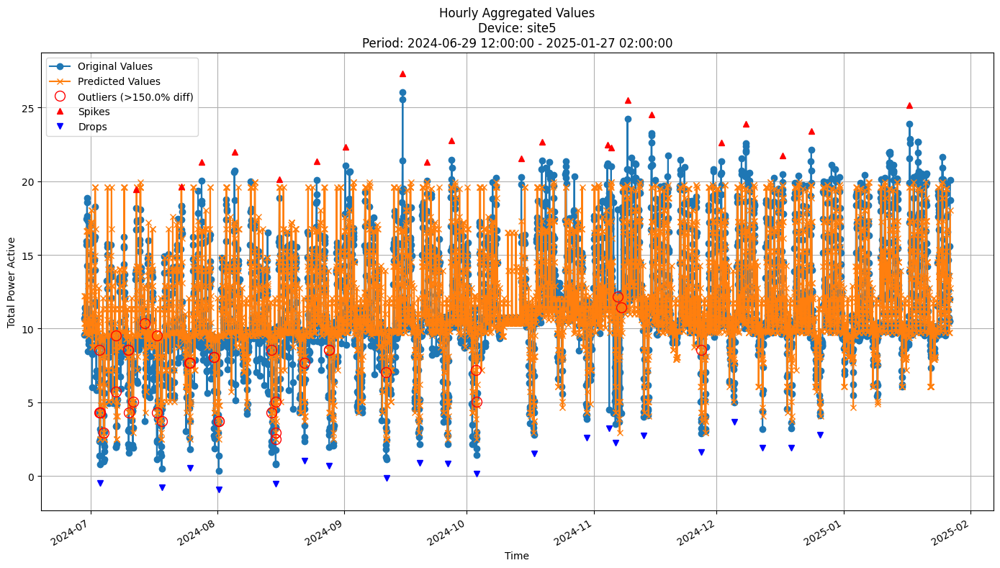


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.0049
MAE: 1.3933
MAPE: 15.0211%

Directional Metrics:
Directional Accuracy: 38.4721%
First-Diff Correlation: 0.2062

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0222
  Recall: 0.0476
  F1 Score: 0.0303
Drops:
  Precision: 0.0606
  Recall: 0.0952
  F1 Score: 0.0741

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0667
  Recall: 0.1429
  F1 Score: 0.0909
Drops:
  Precision: 0.1818
  Recall: 0.2857
  F1 Score: 0.2222


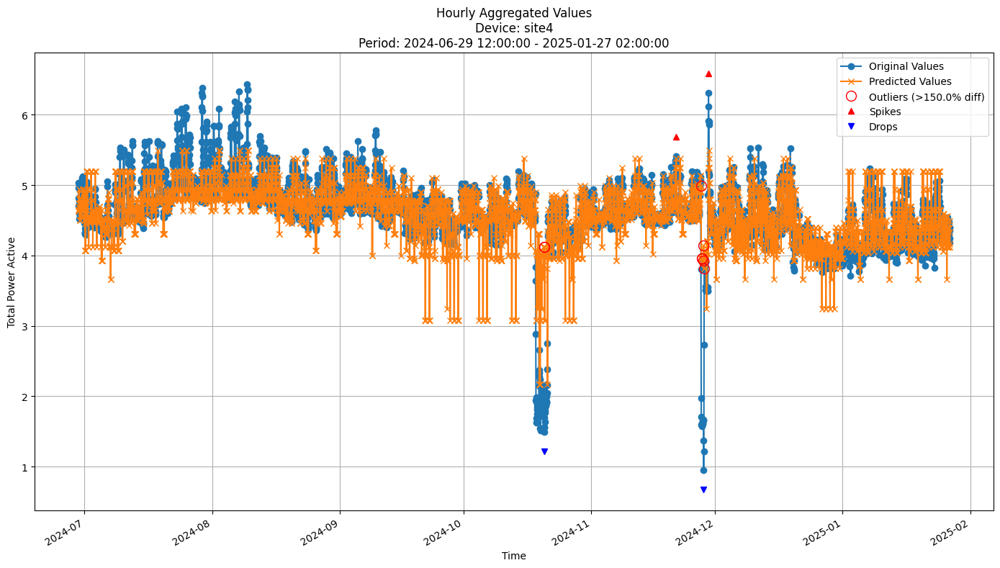


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3766
MAE: 0.2190
MAPE: 5.8658%

Directional Metrics:
Directional Accuracy: 26.5013%
First-Diff Correlation: 0.1082

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


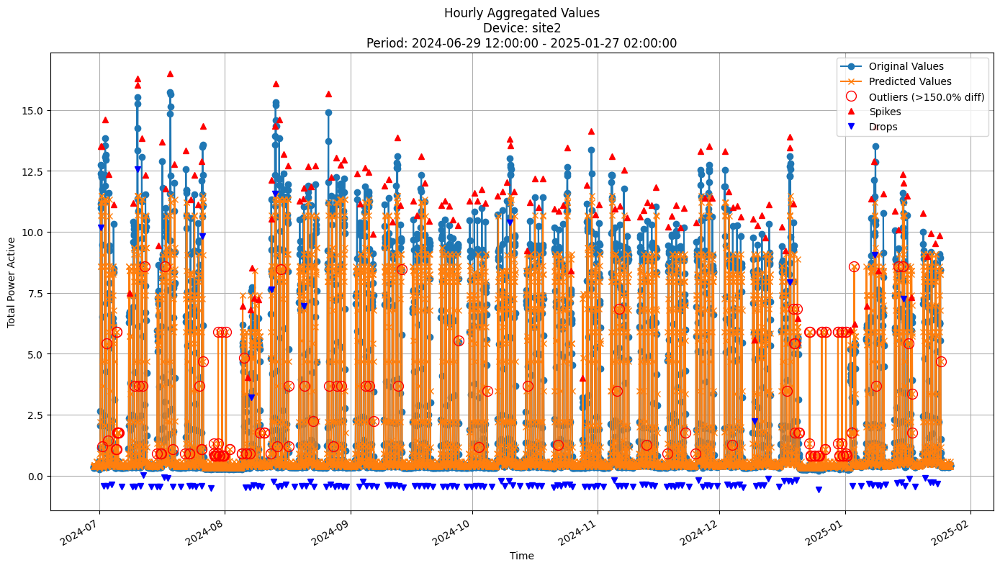


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.0934
MAE: 0.5146
MAPE: 30.0383%

Directional Metrics:
Directional Accuracy: 43.4534%
First-Diff Correlation: 0.6384

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0595
  Recall: 0.0743
  F1 Score: 0.0661
Drops:
  Precision: 0.0657
  Recall: 0.0878
  F1 Score: 0.0751

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1568
  Recall: 0.1959
  F1 Score: 0.1742
Drops:
  Precision: 0.1970
  Recall: 0.2635
  F1 Score: 0.2254


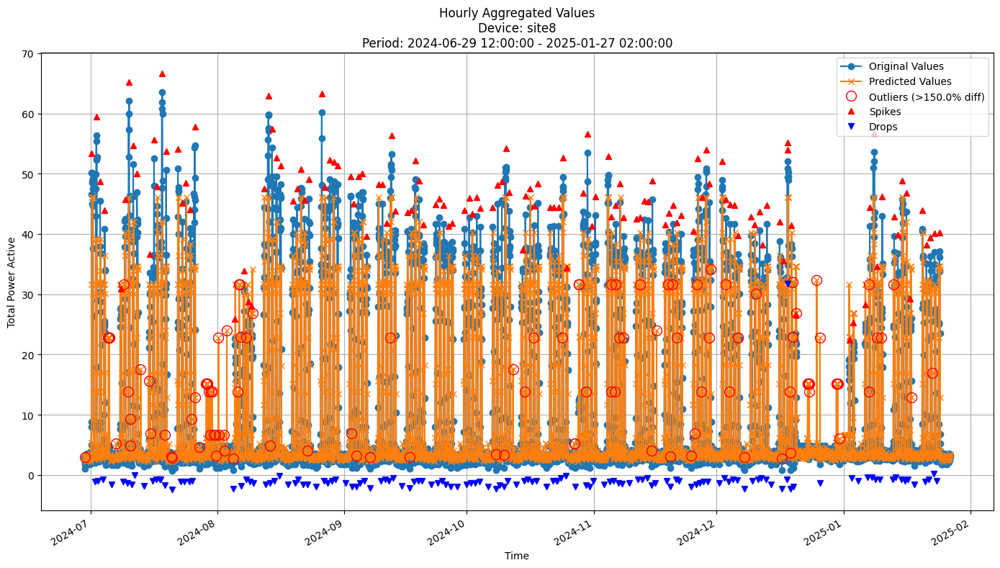


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 4.8202
MAE: 2.5030
MAPE: 30.4263%

Directional Metrics:
Directional Accuracy: 47.0565%
First-Diff Correlation: 0.5698

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0663
  Recall: 0.0963
  F1 Score: 0.0785
Drops:
  Precision: 0.1038
  Recall: 0.1618
  F1 Score: 0.1264

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2143
  Recall: 0.3111
  F1 Score: 0.2538
Drops:
  Precision: 0.2075
  Recall: 0.3235
  F1 Score: 0.2529


In [28]:
for device_id in hoef_all_train_preds.keys():
    y_train = hoef_all_train_preds[device_id][-1]['y_true']
    y_pred_train = hoef_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

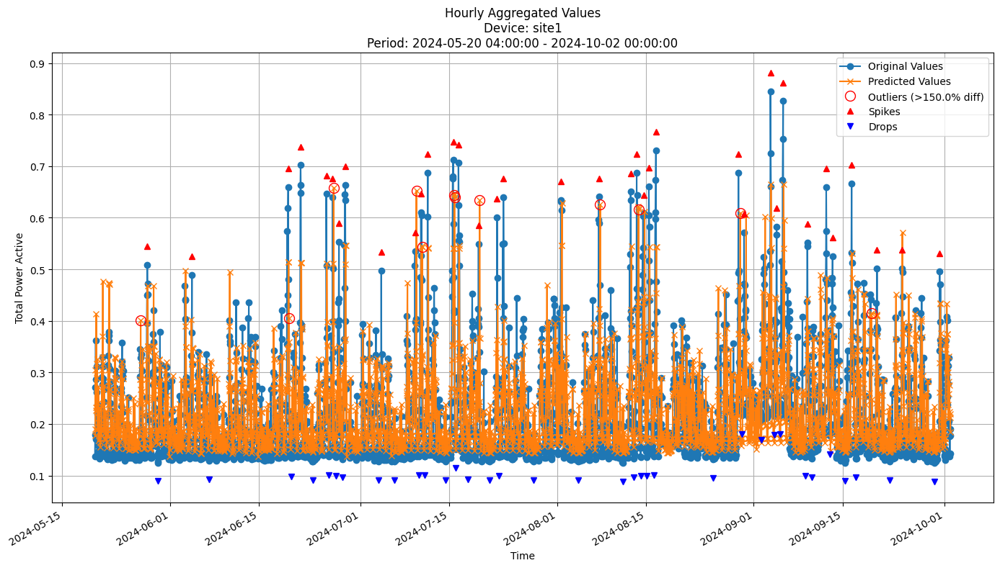


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0810
MAE: 0.0516
MAPE: 22.9345%

Directional Metrics:
Directional Accuracy: 53.7701%
First-Diff Correlation: 0.2017

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.2143
  Recall: 0.1714
  F1 Score: 0.1905

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1786
  Recall: 0.1389
  F1 Score: 0.1563
Drops:
  Precision: 0.3929
  Recall: 0.3143
  F1 Score: 0.3492


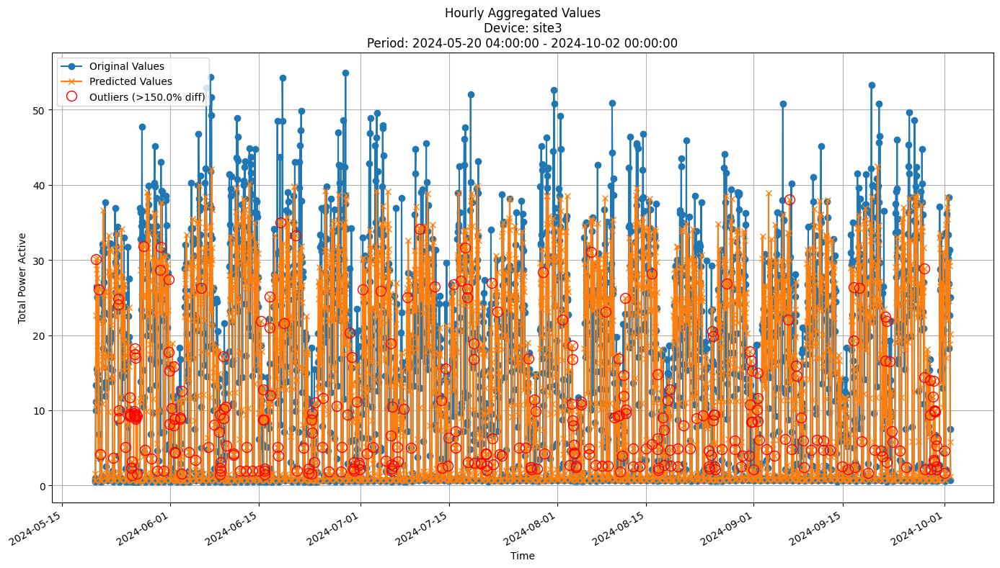


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 7.5768
MAE: 5.0388
MAPE: 78.9162%

Directional Metrics:
Directional Accuracy: 48.7639%
First-Diff Correlation: 0.3138

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


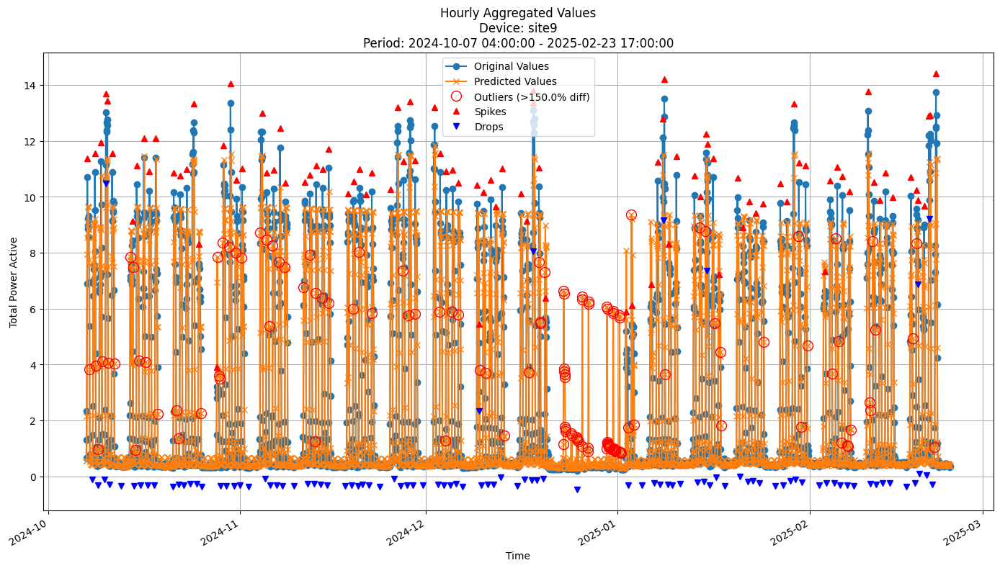


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2653
MAE: 0.5957
MAPE: 34.6834%

Directional Metrics:
Directional Accuracy: 53.4925%
First-Diff Correlation: 0.3829

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0537
  Recall: 0.0808
  F1 Score: 0.0645
Drops:
  Precision: 0.0473
  Recall: 0.0714
  F1 Score: 0.0569

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2081
  Recall: 0.3131
  F1 Score: 0.2500
Drops:
  Precision: 0.1959
  Recall: 0.2959
  F1 Score: 0.2358


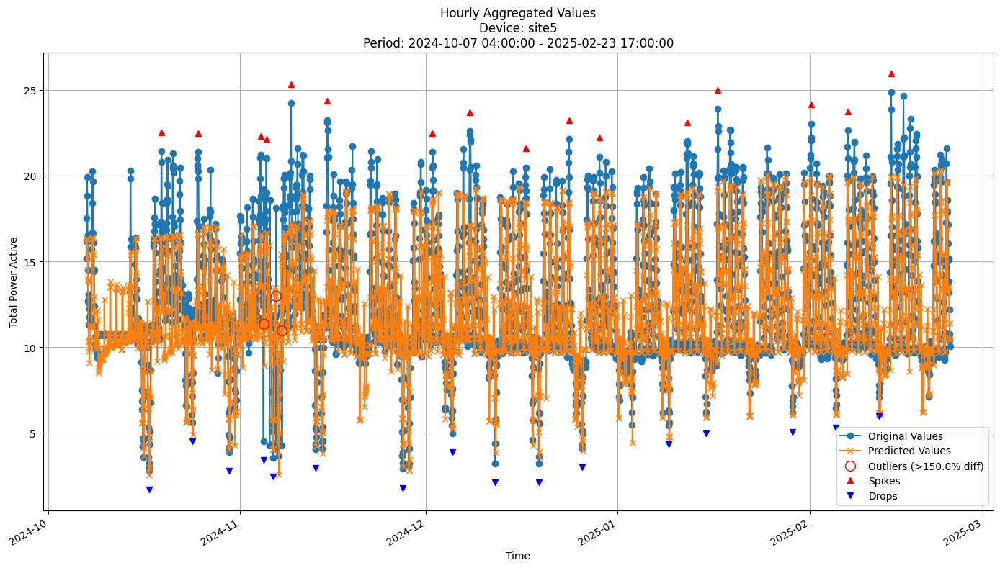


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.1332
MAE: 1.4826
MAPE: 11.9918%

Directional Metrics:
Directional Accuracy: 50.5970%
First-Diff Correlation: 0.2240

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


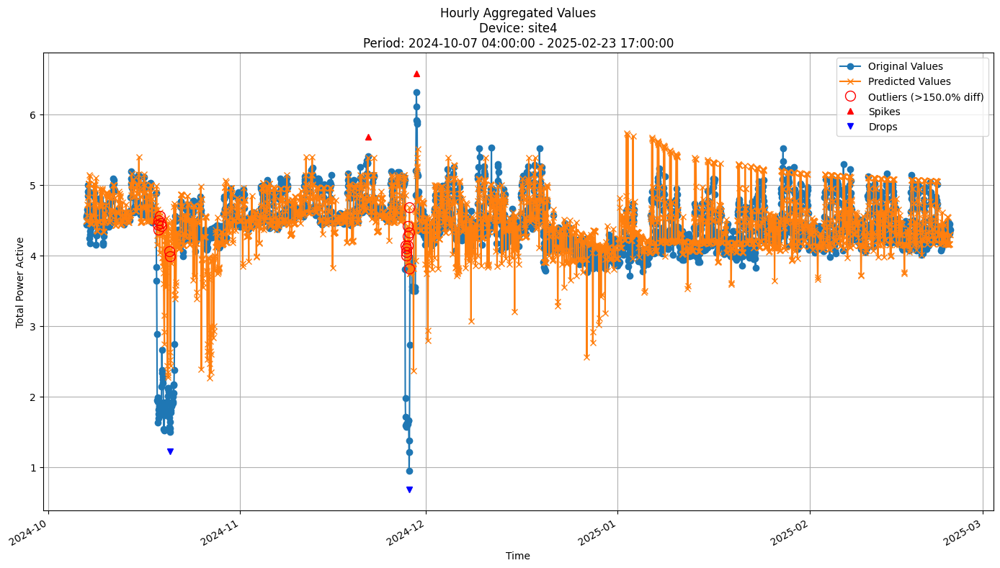


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.4645
MAE: 0.2481
MAPE: 7.4885%

Directional Metrics:
Directional Accuracy: 46.9552%
First-Diff Correlation: 0.0136

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


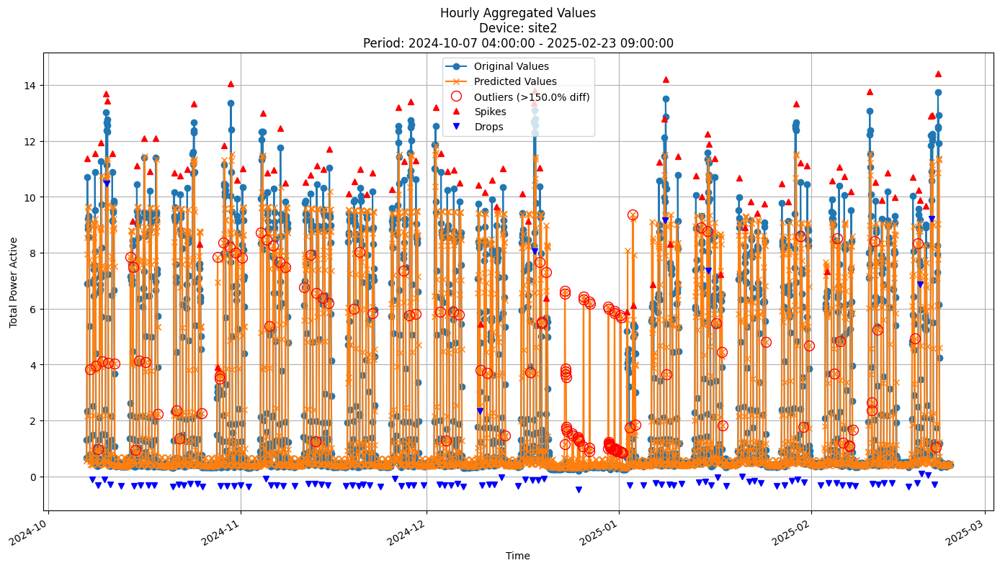


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2668
MAE: 0.5970
MAPE: 34.7388%

Directional Metrics:
Directional Accuracy: 53.5607%
First-Diff Correlation: 0.3829

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0537
  Recall: 0.0808
  F1 Score: 0.0645
Drops:
  Precision: 0.0473
  Recall: 0.0714
  F1 Score: 0.0569

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2081
  Recall: 0.3131
  F1 Score: 0.2500
Drops:
  Precision: 0.1959
  Recall: 0.2959
  F1 Score: 0.2358


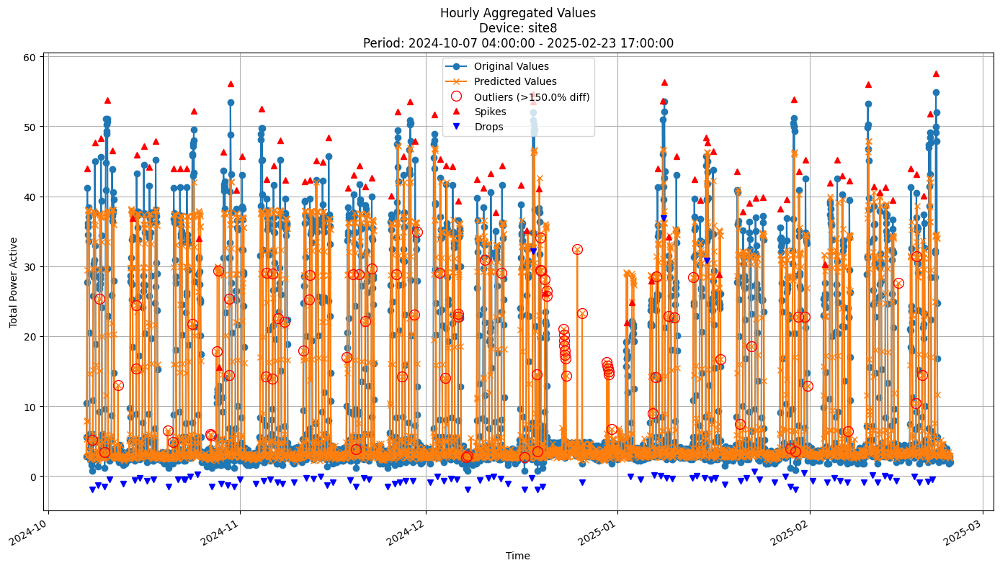


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 5.0617
MAE: 2.6005
MAPE: 30.8624%

Directional Metrics:
Directional Accuracy: 53.0149%
First-Diff Correlation: 0.4890

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0465
  Recall: 0.0632
  F1 Score: 0.0536
Drops:
  Precision: 0.0703
  Recall: 0.0947
  F1 Score: 0.0807

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2403
  Recall: 0.3263
  F1 Score: 0.2768
Drops:
  Precision: 0.2500
  Recall: 0.3368
  F1 Score: 0.2870


In [29]:
join_periods = [-5, -4, -3, -2, -1]
# Device iteration
for device_id in hoef_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (Hoeffding Tree)

In [30]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf_hf = ARFRegressor
arf_hf_params = {
    'n_models': 20,
    'max_features': 0.8,
    'aggregation_method': 'mean',
    'grace_period': 24,
    'max_depth': 10,
    'delta': 0.05,  # split confidence
    'tau': 0.05,  # break ties
    'seed': 42
}

In [31]:
arf_hf_all_train_preds, arf_hf_all_valid_preds, \
arf_hf_all_train_metrics, arf_hf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf_hf,
    model_params=arf_hf_params,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 03:00:00+01:00 to 2023-03-27 03:00:00+02:00
Model's memory usage: 10.192474 MB
Metrics for Device: site1 | Period: 2023-03-27 04:00:00+02:00 - 2023-04-24 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0890
	MAE: 0.0678
	MAPE: 28.6120%

Directional Metrics:
	Directional Accuracy: 63.0402%
	First-Diff Correlation: 0.4030

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2000
		Recall: 0.1739
		F1: 0.1860
	Drops:
		Precision: 0.2000
		Recall: 0.1818
		F1: 0.1905

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.4000
		Recall: 0.3478
		F1: 0.3721
	Drops:
		Precision: 0.3000
		Recall: 0.2727
		F1: 0.2857
--------------------------------------------------
Da

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 03:00:00+01:00 to 2023-04-24 03:00:00+02:00
Model's memory usage: 12.614670 MB
Metrics for Device: site1 | Period: 2023-04-24 04:00:00+02:00 - 2023-05-22 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0519
	MAE: 0.0412
	MAPE: 23.1118%

Directional Metrics:
	Directional Accuracy: 60.5067%
	First-Diff Correlation: 0.5220

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1071
		Recall: 0.0698
		F1: 0.0845
	Drops:
		Precision: 0.0741
		Recall: 0.0435
		F1: 0.0548

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3571
		Recall: 0.2326
		F1: 0.2817
	Drops:
		Precision: 0.4074
		Recall: 0.2391
		F1: 0.3014
--------------------------------------------------
Da

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (6 outputs left out)

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 03:00:00+01:00 to 2023-08-14 03:00:00+02:00
Model's memory usage: 13.086929 MB
Metrics for Device: site1 | Period: 2023-08-14 04:00:00+02:00 - 2023-09-11 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0539
	MAE: 0.0364
	MAPE: 16.9237%

Directional Metrics:
	Directional Accuracy: 60.2086%
	First-Diff Correlation: 0.5198

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3600
		Recall: 0.1667
		F1: 0.2278
	Drops:
		Precision: 0.1667
		Recall: 0.0741
		F1: 0.1026

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6400
		Recall: 0.2963
		F1: 0.4051
	Drops:
		Precision: 0.2917
		Recall: 0.1296
		F1: 0.1795
--------------------------------------------------
Da

Processing devices in split 6:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 03:00:00+01:00 to 2023-09-11 03:00:00+02:00
Model's memory usage: 9.885231 MB
Metrics for Device: site1 | Period: 2023-09-11 04:00:00+02:00 - 2023-10-09 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0561
	MAE: 0.0371
	MAPE: 14.9013%

Directional Metrics:
	Directional Accuracy: 56.4829%
	First-Diff Correlation: 0.6020

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2800
		Recall: 0.1707
		F1: 0.2121
	Drops:
		Precision: 0.0417
		Recall: 0.0238
		F1: 0.0303

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5200
		Recall: 0.3171
		F1: 0.3939
	Drops:
		Precision: 0.2500
		Recall: 0.1429
		F1: 0.1818
--------------------------------------------------
Dai

KeyboardInterrupt: 

#### Results

In [ ]:
print("\n\nTrain period metrics:")
arf_hf_all_time_train_metrics = all_time_aggregation_metrics(arf_hf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_hf_all_time_valid_metrics = all_time_aggregation_metrics(arf_hf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.1057 ± 0.0322
	MAE: 0.0766 ± 0.0338
	MAPE: 31.9123% ± 20.7777%

	Directional Metrics:
		Directional Accuracy: 52.8375% ± 6.1183%
		First-Diff Correlation: 0.3554 ± 0.1083

	Immediate Detection (delta=0):
		Spike Precision: 0.1444 ± 0.0594
		Spike Recall: 0.1300 ± 0.0327
		Spike F1: 0.1326 ± 0.0379
		Drop Precision: 0.0937 ± 0.0295
		Drop Recall: 0.0892 ± 0.0296
		Drop F1: 0.0891 ± 0.0251

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3783 ± 0.0821
		Spike Recall: 0.3602 ± 0.0928
		Spike F1: 0.3585 ± 0.0653
		Drop Precision: 0.2515 ± 0.0499
		Drop Recall: 0.2503 ± 0.0985
		Drop F1: 0.2442 ± 0.0613
Daily Metrics:
	RMSE: 1.7412 ± 0.8898
	MAE: 1.2674 ± 0.9075
	MAPE: 20.3651% ± 19.4043%

	Directional Metrics:
		Directional Accuracy: 79.7221% ± 6.6988%
		First-Diff Correlation: 0.8067 ± 0.1300

	Immediate Detection (delta=0):
		S

#### Training plots

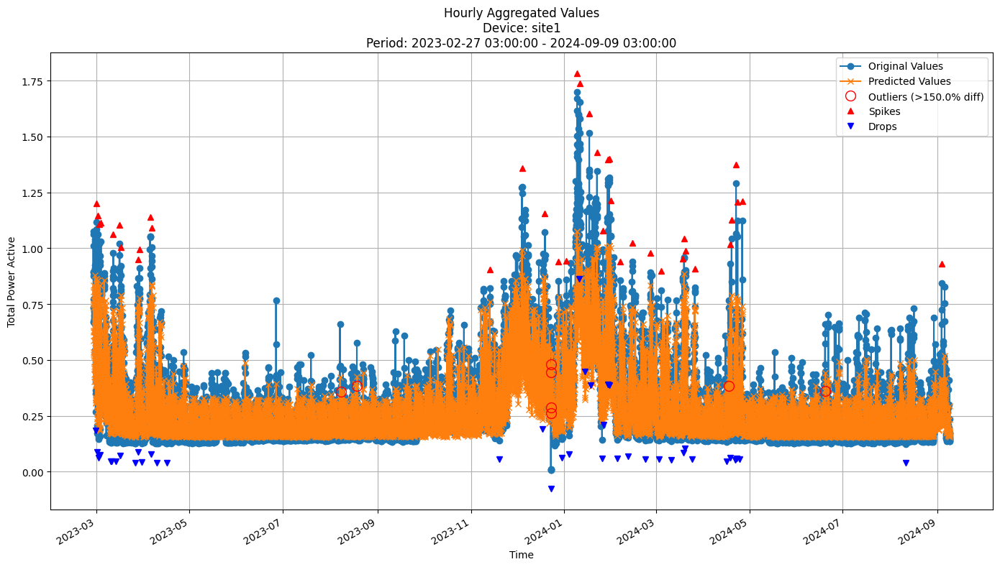


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0975
MAE: 0.0647
MAPE: 22.7899%

Directional Metrics:
Directional Accuracy: 53.0992%
First-Diff Correlation: 0.2752

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0577
  Recall: 0.0789
  F1 Score: 0.0667
Drops:
  Precision: 0.0833
  Recall: 0.1250
  F1 Score: 0.1000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1923
  Recall: 0.2632
  F1 Score: 0.2222
Drops:
  Precision: 0.1500
  Recall: 0.2250
  F1 Score: 0.1800


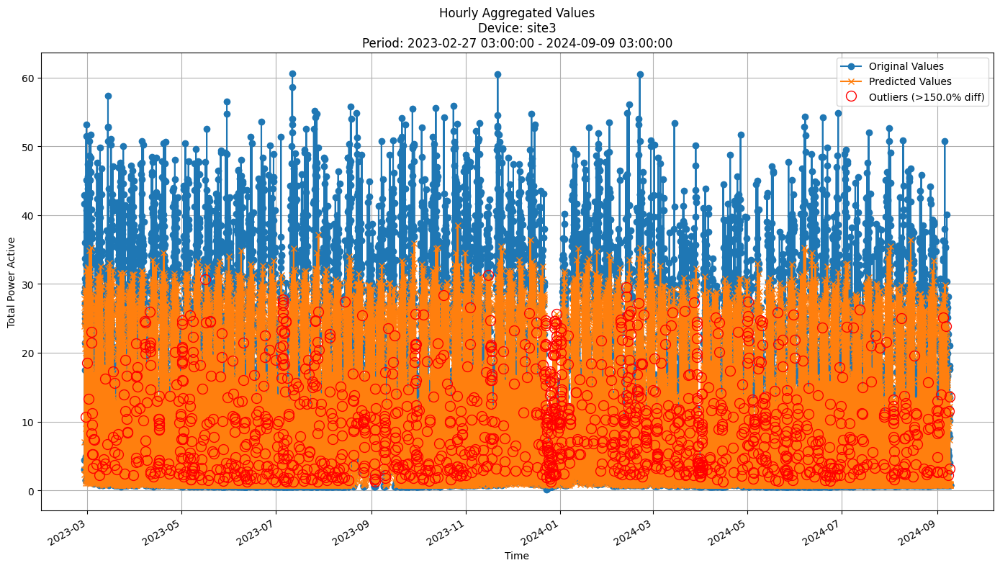


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 7.3917
MAE: 4.9455
MAPE: 84.4651%

Directional Metrics:
Directional Accuracy: 56.7304%
First-Diff Correlation: 0.5075

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


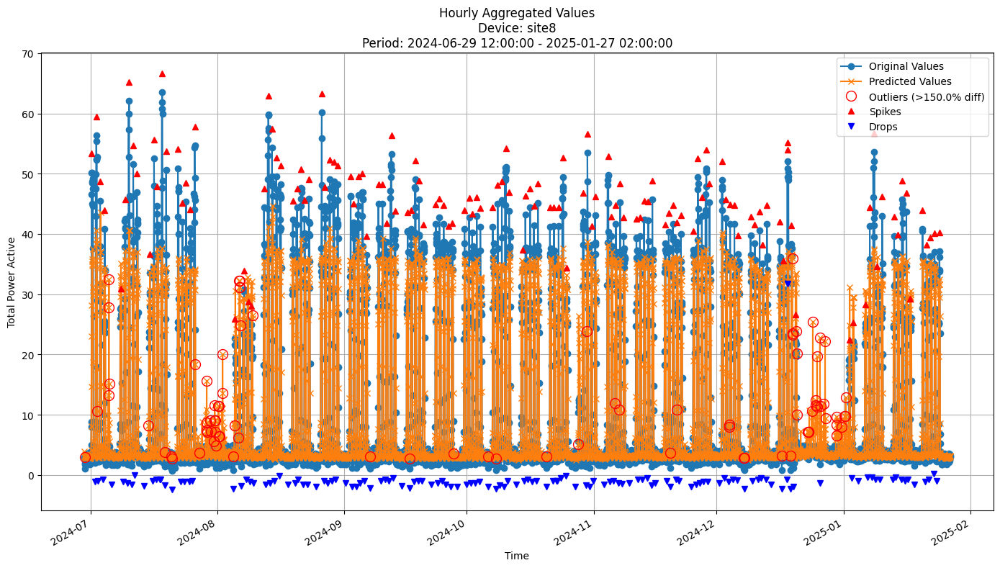


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 4.6677
MAE: 2.3947
MAPE: 27.3994%

Directional Metrics:
Directional Accuracy: 60.8191%
First-Diff Correlation: 0.6808

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1037
  Recall: 0.1259
  F1 Score: 0.1137
Drops:
  Precision: 0.1195
  Recall: 0.1397
  F1 Score: 0.1288

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2378
  Recall: 0.2889
  F1 Score: 0.2609
Drops:
  Precision: 0.2642
  Recall: 0.3088
  F1 Score: 0.2847


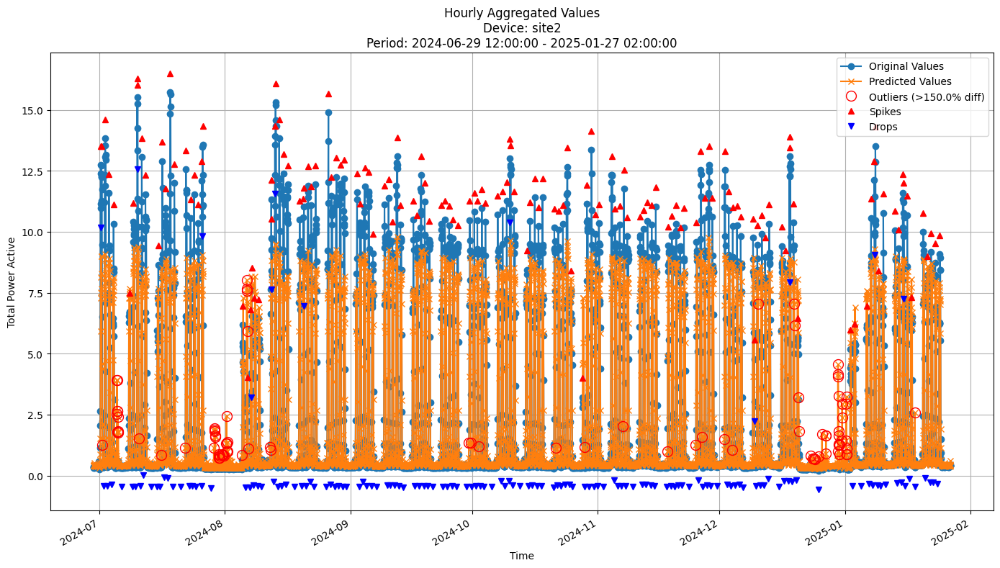


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.1521
MAE: 0.5471
MAPE: 26.7262%

Directional Metrics:
Directional Accuracy: 58.0232%
First-Diff Correlation: 0.7380

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0671
  Recall: 0.0676
  F1 Score: 0.0673
Drops:
  Precision: 0.0974
  Recall: 0.1014
  F1 Score: 0.0993

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2148
  Recall: 0.2162
  F1 Score: 0.2155
Drops:
  Precision: 0.3052
  Recall: 0.3176
  F1 Score: 0.3113


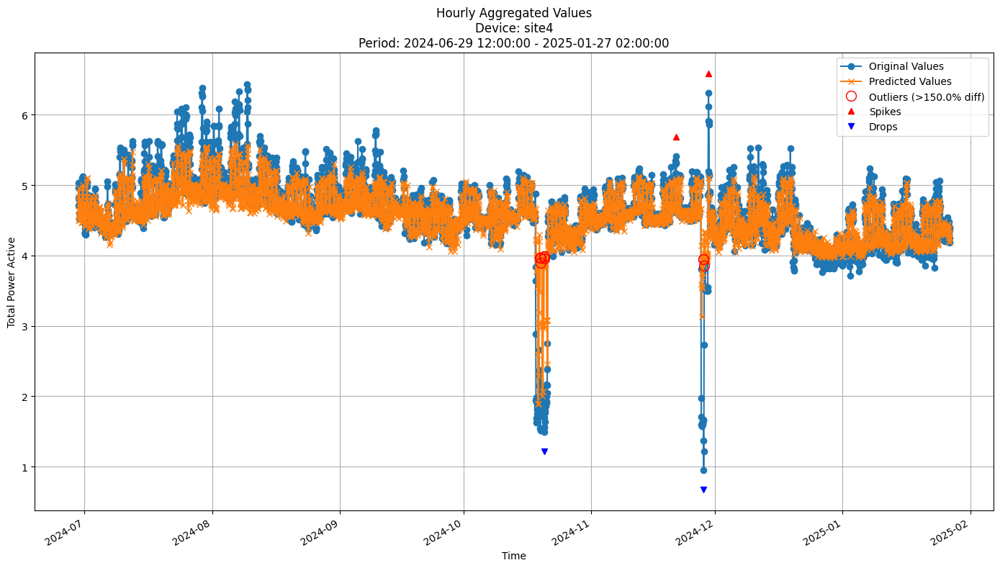


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3050
MAE: 0.1545
MAPE: 4.3061%

Directional Metrics:
Directional Accuracy: 52.4119%
First-Diff Correlation: 0.2353

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


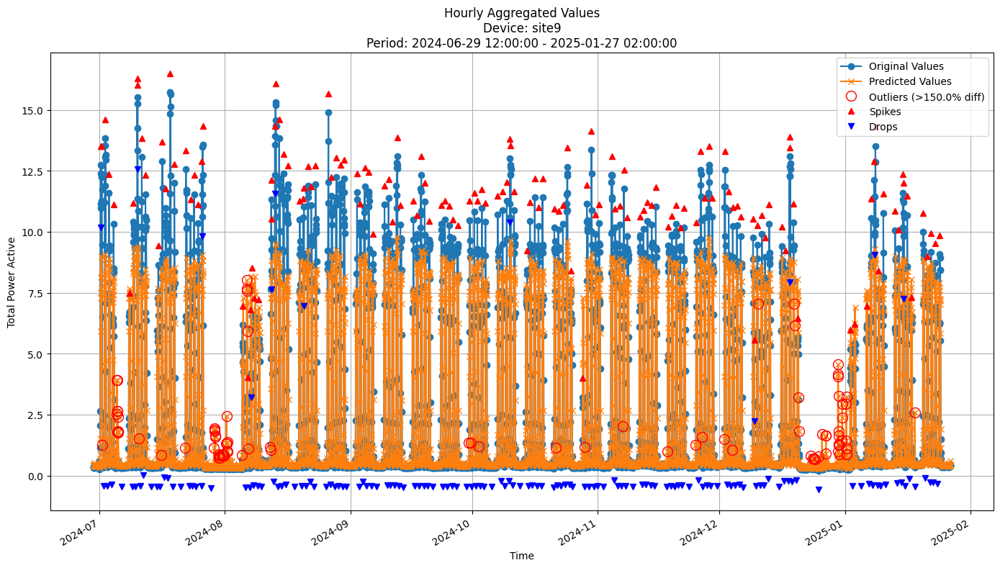


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.1521
MAE: 0.5471
MAPE: 26.7262%

Directional Metrics:
Directional Accuracy: 58.0232%
First-Diff Correlation: 0.7380

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0671
  Recall: 0.0676
  F1 Score: 0.0673
Drops:
  Precision: 0.0974
  Recall: 0.1014
  F1 Score: 0.0993

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2148
  Recall: 0.2162
  F1 Score: 0.2155
Drops:
  Precision: 0.3052
  Recall: 0.3176
  F1 Score: 0.3113


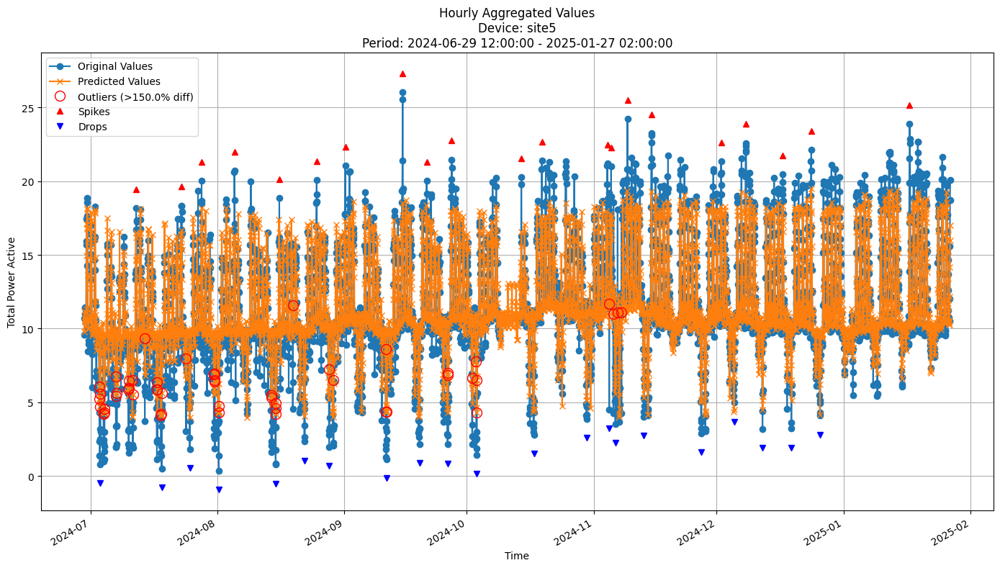


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.6669
MAE: 1.1562
MAPE: 13.5415%

Directional Metrics:
Directional Accuracy: 60.0512%
First-Diff Correlation: 0.3700

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0357
  Recall: 0.0476
  F1 Score: 0.0408
Drops:
  Precision: 0.1034
  Recall: 0.1429
  F1 Score: 0.1200

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1071
  Recall: 0.1429
  F1 Score: 0.1224
Drops:
  Precision: 0.3103
  Recall: 0.4286
  F1 Score: 0.3600


In [ ]:
for device_id in arf_hf_all_train_preds.keys():
    y_train = arf_hf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_hf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

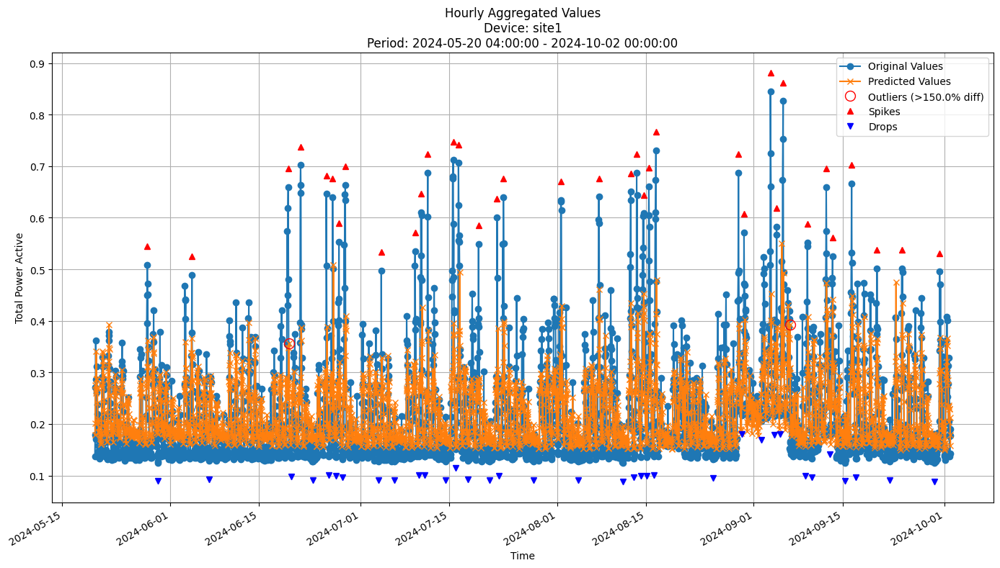


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0756
MAE: 0.0510
MAPE: 23.1293%

Directional Metrics:
Directional Accuracy: 54.1100%
First-Diff Correlation: 0.2025

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


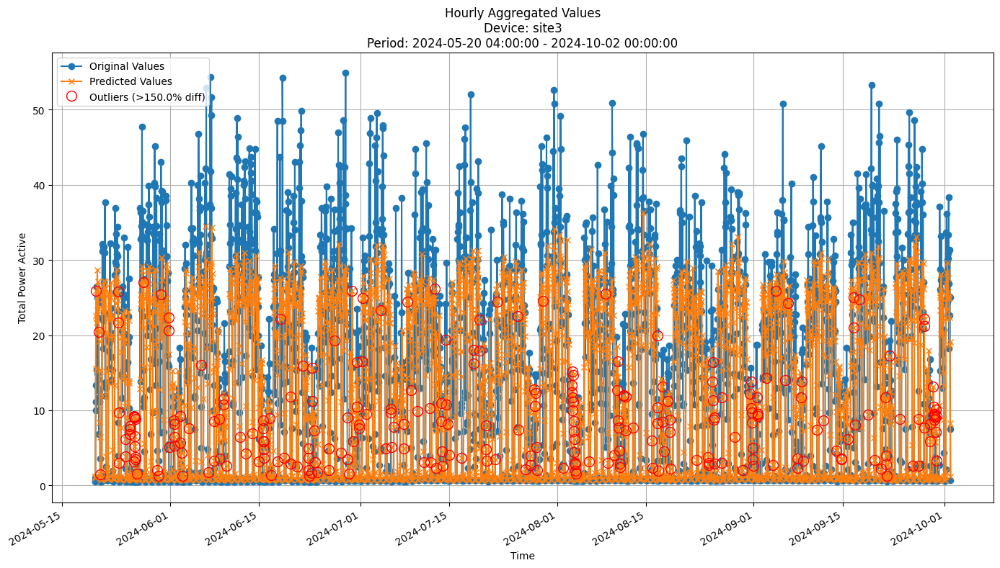


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 6.9613
MAE: 4.6069
MAPE: 64.1418%

Directional Metrics:
Directional Accuracy: 54.0173%
First-Diff Correlation: 0.4627

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


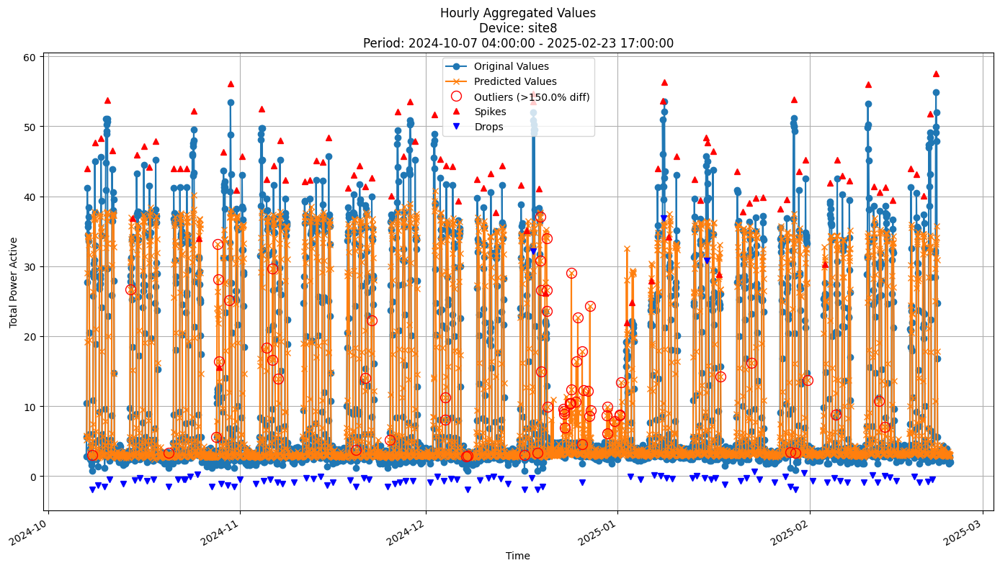


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 4.8602
MAE: 2.4861
MAPE: 27.8754%

Directional Metrics:
Directional Accuracy: 57.4925%
First-Diff Correlation: 0.5463

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0642
  Recall: 0.0737
  F1 Score: 0.0686
Drops:
  Precision: 0.1019
  Recall: 0.1158
  F1 Score: 0.1084

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2202
  Recall: 0.2526
  F1 Score: 0.2353
Drops:
  Precision: 0.2407
  Recall: 0.2737
  F1 Score: 0.2562


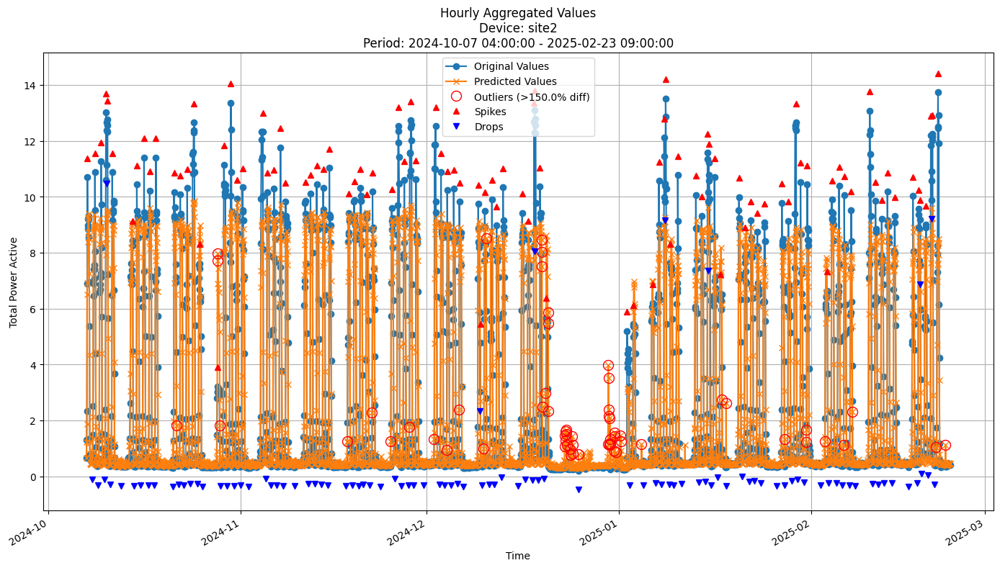


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.0563
MAE: 0.5070
MAPE: 25.6162%

Directional Metrics:
Directional Accuracy: 59.8444%
First-Diff Correlation: 0.6825

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0745
  Recall: 0.0707
  F1 Score: 0.0725
Drops:
  Precision: 0.0860
  Recall: 0.0816
  F1 Score: 0.0838

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2021
  Recall: 0.1919
  F1 Score: 0.1969
Drops:
  Precision: 0.2473
  Recall: 0.2347
  F1 Score: 0.2408


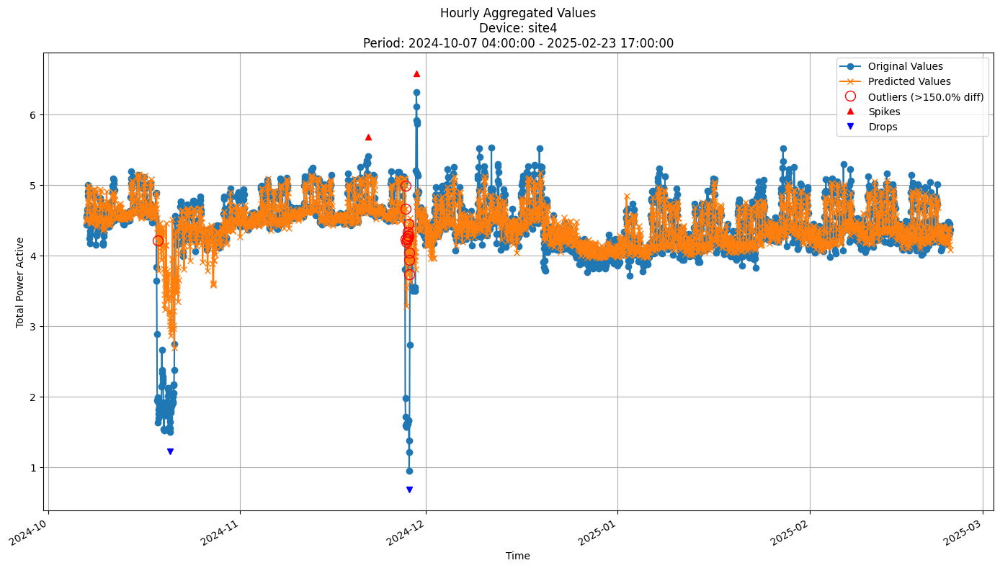


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3817
MAE: 0.1789
MAPE: 5.7381%

Directional Metrics:
Directional Accuracy: 52.1791%
First-Diff Correlation: 0.0916

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


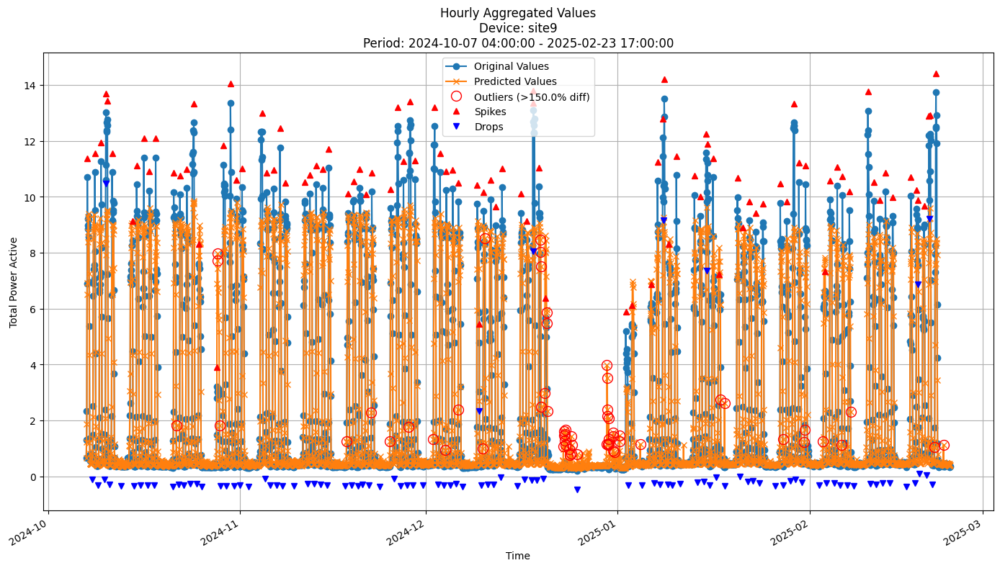


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.0550
MAE: 0.5059
MAPE: 25.5881%

Directional Metrics:
Directional Accuracy: 59.8209%
First-Diff Correlation: 0.6825

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0745
  Recall: 0.0707
  F1 Score: 0.0725
Drops:
  Precision: 0.0860
  Recall: 0.0816
  F1 Score: 0.0838

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2021
  Recall: 0.1919
  F1 Score: 0.1969
Drops:
  Precision: 0.2473
  Recall: 0.2347
  F1 Score: 0.2408


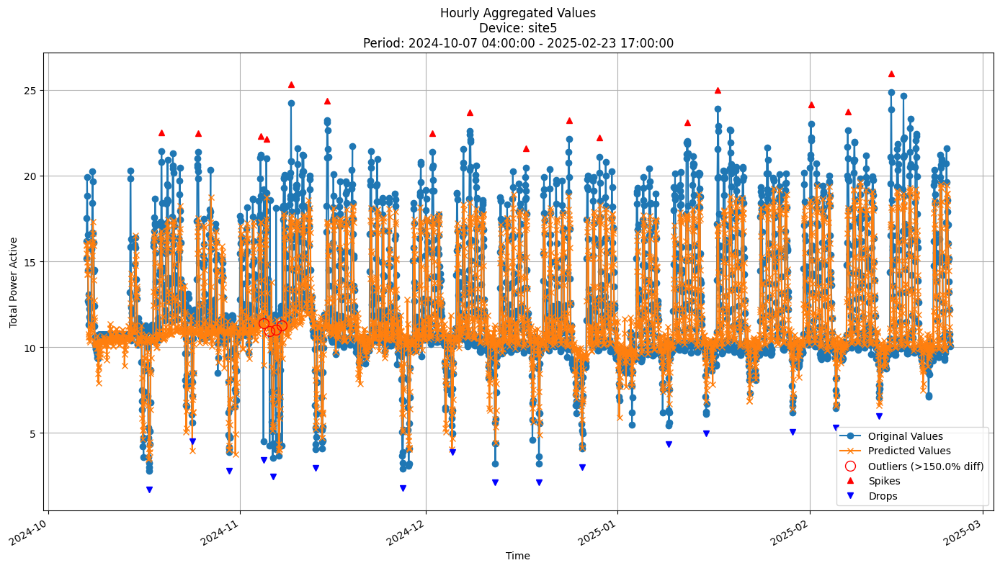


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.8636
MAE: 1.2608
MAPE: 9.8382%

Directional Metrics:
Directional Accuracy: 58.3881%
First-Diff Correlation: 0.3407

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0556
  Recall: 0.0625
  F1 Score: 0.0588
Drops:
  Precision: 0.1579
  Recall: 0.1875
  F1 Score: 0.1714

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1111
  Recall: 0.1250
  F1 Score: 0.1176
Drops:
  Precision: 0.4737
  Recall: 0.5625
  F1 Score: 0.5143


In [ ]:
join_periods = [-5, -4, -3, -2, -1]
# Device iteration
for device_id in arf_hf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### FastODT

In [ ]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

fodt = fastodt.FastODT
fodt_params = {
        'depth': 50, 
         'grace_period': 10, 
         'grace_period_depth': -1, 
         'split_confidence': 0.5, 
         'max_feature': 1.0, 
         'tie_threshold': 0.05, 
         'bin_type': 'adaptive', 
         'max_bins': 32, 
         'split_criterion': 'vr_rel'}

In [ ]:
fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=fodt,
    model_params=fodt_params,
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 03:00:00+01:00 to 2023-03-27 03:00:00+02:00
Model's memory usage: 1.316704 MB
Metrics for Device: site1 | Period: 2023-03-27 04:00:00+02:00 - 2023-04-24 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1015
	MAE: 0.0723
	MAPE: 27.0383%

Directional Metrics:
	Directional Accuracy: 51.1177%
	First-Diff Correlation: 0.2691

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0833
		Recall: 0.0870
		F1: 0.0851
	Drops:
		Precision: 0.1304
		Recall: 0.1364
		F1: 0.1333

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3750
		Recall: 0.3913
		F1: 0.3830
	Drops:
		Precision: 0.2174
		Recall: 0.2273
		F1: 0.2222
--------------------------------------------------
Dai

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 03:00:00+01:00 to 2023-04-24 03:00:00+02:00
Model's memory usage: 2.020935 MB
Metrics for Device: site1 | Period: 2023-04-24 04:00:00+02:00 - 2023-05-22 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0593
	MAE: 0.0380
	MAPE: 18.8386%

Directional Metrics:
	Directional Accuracy: 48.2861%
	First-Diff Correlation: 0.2145

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2000
		Recall: 0.1163
		F1: 0.1471
	Drops:
		Precision: 0.0800
		Recall: 0.0435
		F1: 0.0563

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.4800
		Recall: 0.2791
		F1: 0.3529
	Drops:
		Precision: 0.4000
		Recall: 0.2174
		F1: 0.2817
--------------------------------------------------
Dai

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 12:00:00+02:00 to 2024-12-30 02:00:00+01:00
Model's memory usage: 5.092331 MB
Metrics for Device: site5 | Period: 2024-12-30 03:00:00+01:00 - 2025-01-27 02:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.7384
	MAE: 1.0862
	MAPE: 8.3322%

Directional Metrics:
	Directional Accuracy: 52.7571%
	First-Diff Correlation: 0.3138

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0909
		Recall: 0.1111
		F1: 0.1000
	Drops:
		Precision: 0.0870
		Recall: 0.1053
		F1: 0.0952

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.4091
		Recall: 0.5000
		F1: 0.4500
	Drops:
		Precision: 0.3913
		Recall: 0.4737
		F1: 0.4286
--------------------------------------------------
Dail

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 12:00:00+02:00 to 2025-01-27 02:00:00+01:00
Model's memory usage: 5.791306 MB
Metrics for Device: site5 | Period: 2025-01-27 03:00:00+01:00 - 2025-02-23 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.6515
	MAE: 1.0576
	MAPE: 7.7888%

Directional Metrics:
	Directional Accuracy: 54.5317%
	First-Diff Correlation: 0.3497

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3500
		Recall: 0.3684
		F1: 0.3590
	Drops:
		Precision: 0.3000
		Recall: 0.3000
		F1: 0.3000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7000
		Recall: 0.7368
		F1: 0.7179
	Drops:
		Precision: 0.5000
		Recall: 0.5000
		F1: 0.5000
--------------------------------------------------
Dail

#### Results

In [ ]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.1228 ± 0.0185
	MAE: 0.0775 ± 0.0151
	MAPE: 26.0111% ± 3.7451%

	Directional Metrics:
		Directional Accuracy: 37.1401% ± 4.8203%
		First-Diff Correlation: 0.2723 ± 0.0951

	Immediate Detection (delta=0):
		Spike Precision: 0.1554 ± 0.0438
		Spike Recall: 0.1724 ± 0.0730
		Spike F1: 0.1568 ± 0.0407
		Drop Precision: 0.0777 ± 0.0365
		Drop Recall: 0.0785 ± 0.0263
		Drop F1: 0.0755 ± 0.0289

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3224 ± 0.0668
		Spike Recall: 0.3509 ± 0.1099
		Spike F1: 0.3231 ± 0.0495
		Drop Precision: 0.1996 ± 0.0718
		Drop Recall: 0.2040 ± 0.0403
		Drop F1: 0.1955 ± 0.0504
Daily Metrics:
	RMSE: 1.8442 ± 0.3607
	MAE: 1.0871 ± 0.2600
	MAPE: 13.3611% ± 2.6390%

	Directional Metrics:
		Directional Accuracy: 75.1685% ± 4.7502%
		First-Diff Correlation: 0.6535 ± 0.0909

	Immediate Detection (delta=0):
		Spi

```

Train period metrics:


==================================================
Aggregated Metrics Across Periods
==================================================
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 1.4286 ± 0.4411
	MAE: 0.4649 ± 0.0949
	MAPE: 154.1858% ± 12.7512%

	Directional Metrics:
		Directional Accuracy: 63.7949% ± 1.4450%
		First-Diff Correlation: 0.0459 ± 0.0963

	Immediate Detection (delta=0):
		Spike Precision: 0.0945 ± 0.0637
		Spike Recall: 0.1248 ± 0.0342
		Spike F1: 0.1023 ± 0.0492
		Drop Precision: 0.0928 ± 0.0243
		Drop Recall: 0.1472 ± 0.0543
		Drop F1: 0.1082 ± 0.0211

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2370 ± 0.1074
		Spike Recall: 0.3507 ± 0.0532
		Spike F1: 0.2679 ± 0.0703
		Drop Precision: 0.1830 ± 0.0423
		Drop Recall: 0.3002 ± 0.1367
		Drop F1: 0.2161 ± 0.0506
Daily Metrics:
	RMSE: 20.4400 ± 7.4693
	MAE: 10.7240 ± 2.2030
	MAPE: 140.4382% ± 15.5932%

	Directional Metrics:
		Directional Accuracy: 69.0647% ± 1.8056%
		First-Diff Correlation: 0.5645 ± 0.0631

	Immediate Detection (delta=0):
		Spike Precision: 0.3597 ± 0.1428
		Spike Recall: 0.6779 ± 0.2191
		Spike F1: 0.4554 ± 0.1511
		Drop Precision: 0.2963 ± 0.1443
		Drop Recall: 0.5238 ± 0.1866
		Drop F1: 0.3630 ± 0.1328

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4043 ± 0.1354
		Spike Recall: 0.7713 ± 0.2297
		Spike F1: 0.5155 ± 0.1490
		Drop Precision: 0.4329 ± 0.1644
		Drop Recall: 0.7762 ± 0.2140
		Drop F1: 0.5371 ± 0.1586
Weekly Metrics:
	RMSE: 113.7435 ± 37.9546
	MAE: 72.5625 ± 15.5612
	MAPE: 142.3324% ± 16.4446%
28_days Metrics:
	RMSE: 360.8309 ± 118.6854
	MAE: 263.8197 ± 64.2663
	MAPE: 149.4141% ± 21.0361%
==================================================
Device ID: site3
--------------------------------------------------
Hourly Metrics:
	RMSE: 11.5669 ± 1.4555
	MAE: 8.0340 ± 1.0846
	MAPE: 111.1159% ± 6.0388%

	Directional Metrics:
		Directional Accuracy: 62.6447% ± 3.8172%
		First-Diff Correlation: 0.5265 ± 0.0533

	Immediate Detection (delta=0):
		Spike Precision: 0.0630 ± 0.0472
		Spike Recall: 0.0105 ± 0.0087
		Spike F1: 0.0177 ± 0.0140
		Drop Precision: 0.1906 ± 0.1411
		Drop Recall: 0.0133 ± 0.0121
		Drop F1: 0.0218 ± 0.0153

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1596 ± 0.1153
		Spike Recall: 0.0262 ± 0.0204
		Spike F1: 0.0442 ± 0.0332
		Drop Precision: 0.4194 ± 0.2593
		Drop Recall: 0.0504 ± 0.0704
		Drop F1: 0.0571 ± 0.0369
Daily Metrics:
	RMSE: 172.6580 ± 26.0863
	MAE: 146.3021 ± 23.9399
	MAPE: 41.7586% ± 4.0344%

	Directional Metrics:
		Directional Accuracy: 81.5129% ± 2.2913%
		First-Diff Correlation: 0.8680 ± 0.0527

	Immediate Detection (delta=0):
		Spike Precision: 0.3788 ± 0.1361
		Spike Recall: 0.5379 ± 0.1611
		Spike F1: 0.4389 ± 0.1422
		Drop Precision: 0.5538 ± 0.1801
		Drop Recall: 0.7194 ± 0.1023
		Drop F1: 0.6031 ± 0.1125

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.5900 ± 0.2319
		Spike Recall: 0.8119 ± 0.2027
		Spike F1: 0.6742 ± 0.2186
		Drop Precision: 0.6804 ± 0.1865
		Drop Recall: 0.8966 ± 0.1323
		Drop F1: 0.7489 ± 0.1365
Weekly Metrics:
	RMSE: 971.9025 ± 152.7558
	MAE: 902.1004 ± 139.8825
	MAPE: 33.8709% ± 3.7386%
28_days Metrics:
	RMSE: 3496.3959 ± 412.0541
	MAE: 3151.8350 ± 226.5504
	MAPE: 31.4738% ± 3.8223%
==================================================
Device ID: site4
--------------------------------------------------
Hourly Metrics:
	RMSE: 7.2047 ± 0.1088
	MAE: 5.8004 ± 0.0861
	MAPE: 122.7946% ± 6.2983%

	Directional Metrics:
		Directional Accuracy: 51.1547% ± 0.5179%
		First-Diff Correlation: 0.0186 ± 0.0173

	Immediate Detection (delta=0):
		Spike Precision: 0.0430 ± 0.0220
		Spike Recall: 0.0769 ± 0.0120
		Spike F1: 0.0537 ± 0.0183
		Drop Precision: 0.0219 ± 0.0096
		Drop Recall: 0.0463 ± 0.0214
		Drop F1: 0.0296 ± 0.0130

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2057 ± 0.0498
		Spike Recall: 0.3891 ± 0.0493
		Spike F1: 0.2640 ± 0.0395
		Drop Precision: 0.0536 ± 0.0238
		Drop Recall: 0.0945 ± 0.0143
		Drop F1: 0.0664 ± 0.0186
Daily Metrics:
	RMSE: 122.3920 ± 3.3864
	MAE: 113.0393 ± 4.2904
	MAPE: 101.4446% ± 6.2264%

	Directional Metrics:
		Directional Accuracy: 64.9284% ± 1.3102%
		First-Diff Correlation: 0.4384 ± 0.0827

	Immediate Detection (delta=0):
		Spike Precision: 0.0151 ± 0.0196
		Spike Recall: 0.1250 ± 0.1614
		Spike F1: 0.0270 ± 0.0350
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0221 ± 0.0227
		Spike Recall: 0.1875 ± 0.1943
		Spike F1: 0.0395 ± 0.0405
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Weekly Metrics:
	RMSE: 744.0829 ± 66.3055
	MAE: 688.2735 ± 105.1532
	MAPE: 93.2305% ± 10.0279%
28_days Metrics:
	RMSE: 2808.1318 ± 427.2894
	MAE: 2750.4929 ± 422.6597
	MAPE: 101.6742% ± 6.1800%
==================================================
Device ID: site5
--------------------------------------------------
Hourly Metrics:
	RMSE: 7.1001 ± 0.1762
	MAE: 5.7555 ± 0.1221
	MAPE: 66.2675% ± 8.1382%

	Directional Metrics:
		Directional Accuracy: 49.6081% ± 1.7725%
		First-Diff Correlation: -0.0996 ± 0.0138

	Immediate Detection (delta=0):
		Spike Precision: 0.0350 ± 0.0220
		Spike Recall: 0.0310 ± 0.0204
		Spike F1: 0.0329 ± 0.0211
		Drop Precision: 0.0128 ± 0.0095
		Drop Recall: 0.0108 ± 0.0076
		Drop F1: 0.0117 ± 0.0084

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0821 ± 0.0119
		Spike Recall: 0.0723 ± 0.0103
		Spike F1: 0.0769 ± 0.0109
		Drop Precision: 0.0287 ± 0.0171
		Drop Recall: 0.0246 ± 0.0142
		Drop F1: 0.0265 ± 0.0155
Daily Metrics:
	RMSE: 72.5536 ± 6.0504
	MAE: 63.1687 ± 4.2827
	MAPE: 27.2779% ± 1.6561%

	Directional Metrics:
		Directional Accuracy: 55.3416% ± 4.8641%
		First-Diff Correlation: 0.3503 ± 0.1151

	Immediate Detection (delta=0):
		Spike Precision: 0.0208 ± 0.0551
		Spike Recall: 0.0312 ± 0.0827
		Spike F1: 0.0250 ± 0.0661
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3750 ± 0.3975
		Spike Recall: 0.0878 ± 0.0838
		Spike F1: 0.1216 ± 0.1029
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Weekly Metrics:
	RMSE: 167.7174 ± 47.6658
	MAE: 145.0577 ± 39.8770
	MAPE: 15.7286% ± 6.2873%
28_days Metrics:
	RMSE: 567.2156 ± 260.0607
	MAE: 496.8963 ± 223.2519
	MAPE: 7.9982% ± 2.5192%
==================================================
Device ID: site8
--------------------------------------------------
Hourly Metrics:
	RMSE: 12.6180 ± 0.4301
	MAE: 9.3018 ± 0.2926
	MAPE: 170.1830% ± 4.8446%

	Directional Metrics:
		Directional Accuracy: 55.8814% ± 0.4535%
		First-Diff Correlation: 0.2770 ± 0.0194

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0675 ± 0.0323
		Drop Recall: 0.0441 ± 0.0232
		Drop F1: 0.0532 ± 0.0269

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.3221 ± 0.0573
		Drop Recall: 0.1984 ± 0.0158
		Drop F1: 0.2443 ± 0.0233
Daily Metrics:
	RMSE: 121.2843 ± 7.3768
	MAE: 107.5501 ± 5.9390
	MAPE: 83.3115% ± 9.1902%

	Directional Metrics:
		Directional Accuracy: 70.3931% ± 4.6669%
		First-Diff Correlation: 0.7882 ± 0.0525

	Immediate Detection (delta=0):
		Spike Precision: 0.0601 ± 0.0559
		Spike Recall: 0.1874 ± 0.3129
		Spike F1: 0.0764 ± 0.0691
		Drop Precision: 0.2129 ± 0.1830
		Drop Recall: 0.2998 ± 0.2383
		Drop F1: 0.2475 ± 0.2041

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2720 ± 0.1944
		Spike Recall: 0.4892 ± 0.3140
		Spike F1: 0.3243 ± 0.2143
		Drop Precision: 0.4358 ± 0.3483
		Drop Recall: 0.6250 ± 0.4841
		Drop F1: 0.5107 ± 0.3995
Weekly Metrics:
	RMSE: 367.8093 ± 70.2237
	MAE: 284.2988 ± 56.1231
	MAPE: 40.3974% ± 14.2109%
28_days Metrics:
	RMSE: 820.4173 ± 289.0154
	MAE: 742.9542 ± 275.4982
	MAPE: 14.3376% ± 12.4256%
==================================================
Device ID: site9
--------------------------------------------------
Hourly Metrics:
	RMSE: 5.7836 ± 0.1403
	MAE: 2.8282 ± 0.1197
	MAPE: 265.3842% ± 9.8812%

	Directional Metrics:
		Directional Accuracy: 56.1699% ± 0.9240%
		First-Diff Correlation: 0.2290 ± 0.0405

	Immediate Detection (delta=0):
		Spike Precision: 0.1096 ± 0.0110
		Spike Recall: 0.2695 ± 0.0391
		Spike F1: 0.1557 ± 0.0174
		Drop Precision: 0.0456 ± 0.0099
		Drop Recall: 0.1107 ± 0.0224
		Drop F1: 0.0646 ± 0.0137

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2966 ± 0.0195
		Spike Recall: 0.7280 ± 0.0769
		Spike F1: 0.4212 ± 0.0316
		Drop Precision: 0.1371 ± 0.0128
		Drop Recall: 0.3335 ± 0.0337
		Drop F1: 0.1942 ± 0.0180
Daily Metrics:
	RMSE: 75.9224 ± 2.2358
	MAE: 58.7399 ± 3.8585
	MAPE: 89.9029% ± 3.5175%

	Directional Metrics:
		Directional Accuracy: 71.6727% ± 2.3395%
		First-Diff Correlation: 0.8671 ± 0.0193

	Immediate Detection (delta=0):
		Spike Precision: 0.0789 ± 0.0587
		Spike Recall: 0.1904 ± 0.3103
		Spike F1: 0.0971 ± 0.0869
		Drop Precision: 0.3151 ± 0.2497
		Drop Recall: 0.3689 ± 0.2877
		Drop F1: 0.3389 ± 0.2658

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3344 ± 0.2253
		Spike Recall: 0.4891 ± 0.3131
		Spike F1: 0.3717 ± 0.2311
		Drop Precision: 0.4978 ± 0.3925
		Drop Recall: 0.5830 ± 0.4519
		Drop F1: 0.5353 ± 0.4173
Weekly Metrics:
	RMSE: 406.6172 ± 39.8134
	MAE: 358.5418 ± 62.1463
	MAPE: 89.8596% ± 5.4210%
28_days Metrics:
	RMSE: 1482.0490 ± 251.4957
	MAE: 1434.1671 ± 248.5852
	MAPE: 100.6348% ± 11.5976%
==================================================
Device ID: site2
--------------------------------------------------
Hourly Metrics:
	RMSE: 5.7677 ± 0.1537
	MAE: 2.8198 ± 0.1269
	MAPE: 264.2847% ± 10.9065%

	Directional Metrics:
		Directional Accuracy: 56.2055% ± 0.9262%
		First-Diff Correlation: 0.2297 ± 0.0402

	Immediate Detection (delta=0):
		Spike Precision: 0.1127 ± 0.0120
		Spike Recall: 0.2768 ± 0.0375
		Spike F1: 0.1601 ± 0.0180
		Drop Precision: 0.0461 ± 0.0103
		Drop Recall: 0.1117 ± 0.0227
		Drop F1: 0.0652 ± 0.0141

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2999 ± 0.0175
		Spike Recall: 0.7354 ± 0.0651
		Spike F1: 0.4257 ± 0.0269
		Drop Precision: 0.1375 ± 0.0142
		Drop Recall: 0.3344 ± 0.0349
		Drop F1: 0.1948 ± 0.0195
Daily Metrics:
	RMSE: 75.6948 ± 2.4162
	MAE: 58.5538 ± 4.0795
	MAPE: 89.5460% ± 3.8834%

	Directional Metrics:
		Directional Accuracy: 72.4540% ± 3.8659%
		First-Diff Correlation: 0.8664 ± 0.0205

	Immediate Detection (delta=0):
		Spike Precision: 0.0830 ± 0.0655
		Spike Recall: 0.1904 ± 0.3103
		Spike F1: 0.1030 ± 0.1002
		Drop Precision: 0.3151 ± 0.2497
		Drop Recall: 0.3689 ± 0.2877
		Drop F1: 0.3389 ± 0.2658

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3385 ± 0.2225
		Spike Recall: 0.4891 ± 0.3131
		Spike F1: 0.3777 ± 0.2294
		Drop Precision: 0.4978 ± 0.3925
		Drop Recall: 0.5830 ± 0.4519
		Drop F1: 0.5353 ± 0.4173
Weekly Metrics:
	RMSE: 405.4382 ± 41.4482
	MAE: 357.6252 ± 63.3554
	MAPE: 89.4626% ± 6.0151%
28_days Metrics:
	RMSE: 1478.1633 ± 256.4983
	MAE: 1430.5009 ± 253.4215
	MAPE: 100.3042% ± 11.5080%
==================================================

\Valid period metrics:


==================================================
Aggregated Metrics Across Periods
==================================================
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.9517 ± 1.3326
	MAE: 0.4789 ± 0.5493
	MAPE: 160.8027% ± 43.0824%

	Directional Metrics:
		Directional Accuracy: 59.4841% ± 3.0337%
		First-Diff Correlation: 0.1607 ± 0.1725

	Immediate Detection (delta=0):
		Spike Precision: 0.1808 ± 0.1957
		Spike Recall: 0.1208 ± 0.0885
		Spike F1: 0.1298 ± 0.1186
		Drop Precision: 0.0945 ± 0.0706
		Drop Recall: 0.0973 ± 0.0820
		Drop F1: 0.0828 ± 0.0591

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3351 ± 0.2361
		Spike Recall: 0.2752 ± 0.1159
		Spike F1: 0.2588 ± 0.1325
		Drop Precision: 0.1761 ± 0.1247
		Drop Recall: 0.2038 ± 0.1785
		Drop F1: 0.1574 ± 0.1118
Daily Metrics:
	RMSE: 14.5838 ± 20.9681
	MAE: 10.6832 ± 12.1654
	MAPE: 143.0981% ± 40.2923%

	Directional Metrics:
		Directional Accuracy: 67.8649% ± 7.5689%
		First-Diff Correlation: 0.5882 ± 0.1056

	Immediate Detection (delta=0):
		Spike Precision: 0.2475 ± 0.2703
		Spike Recall: 0.4333 ± 0.4453
		Spike F1: 0.3010 ± 0.3107
		Drop Precision: 0.2375 ± 0.3701
		Drop Recall: 0.2917 ± 0.4278
		Drop F1: 0.2433 ± 0.3616

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4058 ± 0.3076
		Spike Recall: 0.6417 ± 0.4258
		Spike F1: 0.4679 ± 0.3155
		Drop Precision: 0.3125 ± 0.3978
		Drop Recall: 0.3917 ± 0.4633
		Drop F1: 0.3267 ± 0.3943
Weekly Metrics:
	RMSE: 78.4506 ± 101.4114
	MAE: 61.9615 ± 70.3464
	MAPE: 142.7509% ± 41.8130%
28_days Metrics:
	RMSE: 219.1738 ± 248.5095
	MAE: 157.4884 ± 175.2153
	MAPE: 148.2634% ± 48.2707%
==================================================
Device ID: site3
--------------------------------------------------
Hourly Metrics:
	RMSE: 10.9856 ± 1.6665
	MAE: 7.5816 ± 1.2908
	MAPE: 123.2313% ± 29.9137%

	Directional Metrics:
		Directional Accuracy: 58.0760% ± 3.3480%
		First-Diff Correlation: 0.4170 ± 0.0758

	Immediate Detection (delta=0):
		Spike Precision: 0.0217 ± 0.0669
		Spike Recall: 0.0058 ± 0.0214
		Spike F1: 0.0088 ± 0.0316
		Drop Precision: 0.1696 ± 0.3068
		Drop Recall: 0.0339 ± 0.0653
		Drop F1: 0.0464 ± 0.0842

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0476 ± 0.1023
		Spike Recall: 0.0284 ± 0.0531
		Spike F1: 0.0279 ± 0.0534
		Drop Precision: 0.2625 ± 0.3603
		Drop Recall: 0.0738 ± 0.1239
		Drop F1: 0.0955 ± 0.1512
Daily Metrics:
	RMSE: 153.2790 ± 37.8610
	MAE: 126.7289 ± 33.1132
	MAPE: 45.8233% ± 17.1199%

	Directional Metrics:
		Directional Accuracy: 76.1568% ± 8.3840%
		First-Diff Correlation: 0.8191 ± 0.0897

	Immediate Detection (delta=0):
		Spike Precision: 0.2167 ± 0.2986
		Spike Recall: 0.2667 ± 0.3704
		Spike F1: 0.2333 ± 0.3187
		Drop Precision: 0.4000 ± 0.3590
		Drop Recall: 0.5250 ± 0.4225
		Drop F1: 0.4367 ± 0.3616

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4083 ± 0.3435
		Spike Recall: 0.5417 ± 0.4212
		Spike F1: 0.4517 ± 0.3547
		Drop Precision: 0.4667 ± 0.3712
		Drop Recall: 0.6167 ± 0.4349
		Drop F1: 0.5133 ± 0.3764
Weekly Metrics:
	RMSE: 753.5966 ± 244.0231
	MAE: 636.7292 ± 231.9271
	MAPE: 31.3748% ± 11.5298%
28_days Metrics:
	RMSE: 2199.5025 ± 868.6285
	MAE: 1593.7725 ± 649.8763
	MAPE: 30.4113% ± 17.6259%
==================================================
Device ID: site4
--------------------------------------------------
Hourly Metrics:
	RMSE: 7.3202 ± 0.1849
	MAE: 5.8934 ± 0.1437
	MAPE: 130.5138% ± 12.8996%

	Directional Metrics:
		Directional Accuracy: 49.9876% ± 2.2315%
		First-Diff Correlation: -0.0185 ± 0.0428

	Immediate Detection (delta=0):
		Spike Precision: 0.0576 ± 0.0415
		Spike Recall: 0.0491 ± 0.0325
		Spike F1: 0.0502 ± 0.0319
		Drop Precision: 0.0447 ± 0.0635
		Drop Recall: 0.0380 ± 0.0393
		Drop F1: 0.0385 ± 0.0440

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2645 ± 0.1393
		Spike Recall: 0.2468 ± 0.1333
		Spike F1: 0.2463 ± 0.1269
		Drop Precision: 0.1092 ± 0.1266
		Drop Recall: 0.0902 ± 0.0738
		Drop F1: 0.0945 ± 0.0882
Daily Metrics:
	RMSE: 123.3938 ± 6.2612
	MAE: 114.1434 ± 5.9808
	MAPE: 107.0105% ± 12.3918%

	Directional Metrics:
		Directional Accuracy: 70.9160% ± 6.8781%
		First-Diff Correlation: 0.5723 ± 0.0343

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Weekly Metrics:
	RMSE: 746.8908 ± 35.8703
	MAE: 678.1720 ± 42.4480
	MAPE: 93.9671% ± 9.5943%
28_days Metrics:
	RMSE: 2439.0257 ± 244.2624
	MAE: 1836.6557 ± 451.5047
	MAPE: 71.8009% ± 14.0903%
==================================================
Device ID: site5
--------------------------------------------------
Hourly Metrics:
	RMSE: 7.6519 ± 0.5666
	MAE: 6.1892 ± 0.4665
	MAPE: 55.9432% ± 6.9875%

	Directional Metrics:
		Directional Accuracy: 47.0407% ± 4.8812%
		First-Diff Correlation: -0.1117 ± 0.0473

	Immediate Detection (delta=0):
		Spike Precision: 0.0191 ± 0.0246
		Spike Recall: 0.0163 ± 0.0213
		Spike F1: 0.0175 ± 0.0228
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0697 ± 0.0499
		Spike Recall: 0.0590 ± 0.0431
		Spike F1: 0.0638 ± 0.0461
		Drop Precision: 0.0132 ± 0.0348
		Drop Recall: 0.0104 ± 0.0276
		Drop F1: 0.0116 ± 0.0308
Daily Metrics:
	RMSE: 84.4285 ± 12.0095
	MAE: 70.3333 ± 7.4046
	MAPE: 26.7400% ± 2.6748%

	Directional Metrics:
		Directional Accuracy: 51.5542% ± 7.2265%
		First-Diff Correlation: 0.4274 ± 0.1041

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1250 ± 0.3307
		Spike Recall: 0.0312 ± 0.0827
		Spike F1: 0.0500 ± 0.1323
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Weekly Metrics:
	RMSE: 245.3329 ± 119.7072
	MAE: 223.5658 ± 118.4510
	MAPE: 22.9895% ± 4.4954%
28_days Metrics:
	RMSE: 745.4015 ± 528.2215
	MAE: 607.3523 ± 508.3497
	MAPE: 38.1472% ± 8.2102%
==================================================
Device ID: site8
--------------------------------------------------
Hourly Metrics:
	RMSE: 11.8501 ± 1.2181
	MAE: 8.9456 ± 0.8876
	MAPE: 161.3096% ± 7.3006%

	Directional Metrics:
		Directional Accuracy: 55.5691% ± 1.7971%
		First-Diff Correlation: 0.3082 ± 0.0356

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0847 ± 0.0671
		Drop Recall: 0.0479 ± 0.0434
		Drop F1: 0.0595 ± 0.0501

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0078 ± 0.0207
		Spike Recall: 0.0050 ± 0.0132
		Spike F1: 0.0061 ± 0.0161
		Drop Precision: 0.2937 ± 0.1193
		Drop Recall: 0.1697 ± 0.0764
		Drop F1: 0.2115 ± 0.0897
Daily Metrics:
	RMSE: 105.6844 ± 12.5365
	MAE: 91.1066 ± 14.3190
	MAPE: 68.6242% ± 9.6434%

	Directional Metrics:
		Directional Accuracy: 68.1878% ± 8.7447%
		First-Diff Correlation: 0.7325 ± 0.0905

	Immediate Detection (delta=0):
		Spike Precision: 0.1562 ± 0.1583
		Spike Recall: 0.1562 ± 0.1583
		Spike F1: 0.1548 ± 0.1557
		Drop Precision: 0.3750 ± 0.3511
		Drop Recall: 0.3750 ± 0.3511
		Drop F1: 0.3750 ± 0.3511

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4792 ± 0.2818
		Spike Recall: 0.5000 ± 0.3227
		Spike F1: 0.4810 ± 0.2868
		Drop Precision: 0.7292 ± 0.3721
		Drop Recall: 0.8750 ± 0.3307
		Drop F1: 0.7708 ± 0.3430
Weekly Metrics:
	RMSE: 298.9891 ± 140.2942
	MAE: 216.2730 ± 99.1015
	MAPE: 20.5737% ± 14.3802%
28_days Metrics:
	RMSE: 586.5825 ± 239.4246
	MAE: 428.8414 ± 160.5970
	MAPE: 13.2441% ± 7.7204%
==================================================
Device ID: site9
--------------------------------------------------
Hourly Metrics:
	RMSE: 5.9176 ± 0.3311
	MAE: 2.9218 ± 0.3076
	MAPE: 270.3083% ± 29.7465%

	Directional Metrics:
		Directional Accuracy: 55.0079% ± 3.1764%
		First-Diff Correlation: 0.1970 ± 0.1029

	Immediate Detection (delta=0):
		Spike Precision: 0.0943 ± 0.0350
		Spike Recall: 0.2279 ± 0.0972
		Spike F1: 0.1329 ± 0.0510
		Drop Precision: 0.0478 ± 0.0201
		Drop Recall: 0.1129 ± 0.0423
		Drop F1: 0.0669 ± 0.0270

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2623 ± 0.0637
		Spike Recall: 0.6345 ± 0.1876
		Spike F1: 0.3698 ± 0.0940
		Drop Precision: 0.1384 ± 0.0325
		Drop Recall: 0.3349 ± 0.0842
		Drop F1: 0.1949 ± 0.0439
Daily Metrics:
	RMSE: 76.0067 ± 5.0255
	MAE: 60.2040 ± 6.6322
	MAPE: 91.4623% ± 7.9597%

	Directional Metrics:
		Directional Accuracy: 68.6508% ± 7.1786%
		First-Diff Correlation: 0.8693 ± 0.0353

	Immediate Detection (delta=0):
		Spike Precision: 0.1667 ± 0.2357
		Spike Recall: 0.1667 ± 0.2357
		Spike F1: 0.1667 ± 0.2357
		Drop Precision: 0.3333 ± 0.4410
		Drop Recall: 0.3333 ± 0.4410
		Drop F1: 0.3333 ± 0.4410

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4792 ± 0.2818
		Spike Recall: 0.4375 ± 0.2627
		Spike F1: 0.4554 ± 0.2687
		Drop Precision: 0.6250 ± 0.4841
		Drop Recall: 0.6250 ± 0.4841
		Drop F1: 0.6250 ± 0.4841
Weekly Metrics:
	RMSE: 408.1824 ± 27.3570
	MAE: 358.2268 ± 45.4032
	MAPE: 90.0797% ± 5.7593%
28_days Metrics:
	RMSE: 1290.6594 ± 202.6912
	MAE: 974.7000 ± 286.3010
	MAPE: 75.2432% ± 9.8562%
==================================================
Device ID: site2
--------------------------------------------------
Hourly Metrics:
	RMSE: 5.9014 ± 0.3367
	MAE: 2.9144 ± 0.3107
	MAPE: 269.3024% ± 29.6465%

	Directional Metrics:
		Directional Accuracy: 54.9561% ± 2.9216%
		First-Diff Correlation: 0.1992 ± 0.1018

	Immediate Detection (delta=0):
		Spike Precision: 0.0955 ± 0.0365
		Spike Recall: 0.2311 ± 0.0971
		Spike F1: 0.1346 ± 0.0525
		Drop Precision: 0.0502 ± 0.0211
		Drop Recall: 0.1198 ± 0.0458
		Drop F1: 0.0705 ± 0.0286

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2646 ± 0.0641
		Spike Recall: 0.6404 ± 0.1805
		Spike F1: 0.3731 ± 0.0930
		Drop Precision: 0.1413 ± 0.0312
		Drop Recall: 0.3439 ± 0.0789
		Drop F1: 0.1994 ± 0.0412
Daily Metrics:
	RMSE: 75.7461 ± 5.1066
	MAE: 59.9825 ± 6.7047
	MAPE: 91.0894% ± 7.7876%

	Directional Metrics:
		Directional Accuracy: 68.6508% ± 7.1786%
		First-Diff Correlation: 0.8689 ± 0.0361

	Immediate Detection (delta=0):
		Spike Precision: 0.1667 ± 0.2357
		Spike Recall: 0.1667 ± 0.2357
		Spike F1: 0.1667 ± 0.2357
		Drop Precision: 0.3333 ± 0.4410
		Drop Recall: 0.3333 ± 0.4410
		Drop F1: 0.3333 ± 0.4410

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4792 ± 0.2818
		Spike Recall: 0.4375 ± 0.2627
		Spike F1: 0.4554 ± 0.2687
		Drop Precision: 0.6250 ± 0.4841
		Drop Recall: 0.6250 ± 0.4841
		Drop F1: 0.6250 ± 0.4841
Weekly Metrics:
	RMSE: 406.7281 ± 27.7785
	MAE: 356.9030 ± 45.6577
	MAPE: 89.7187% ± 5.6834%
28_days Metrics:
	RMSE: 1285.8742 ± 202.9780
	MAE: 971.0458 ± 285.3396
	MAPE: 74.9596% ± 9.8430%
==================================================
```

#### Training plots

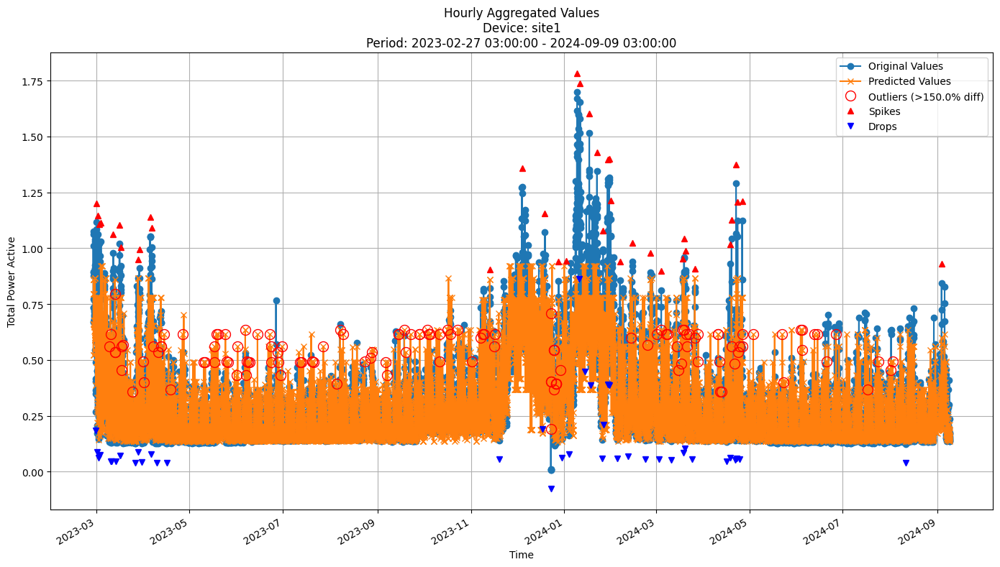


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1269
MAE: 0.0768
MAPE: 26.5748%

Directional Metrics:
Directional Accuracy: 40.5462%
First-Diff Correlation: 0.1105

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


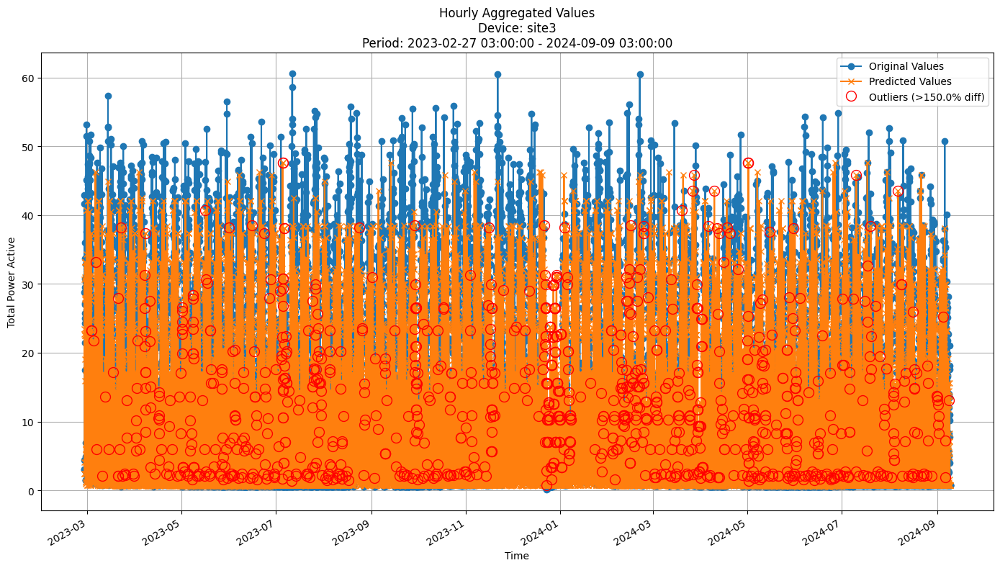


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 7.8787
MAE: 5.1312
MAPE: 84.8135%

Directional Metrics:
Directional Accuracy: 49.2596%
First-Diff Correlation: 0.4670

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


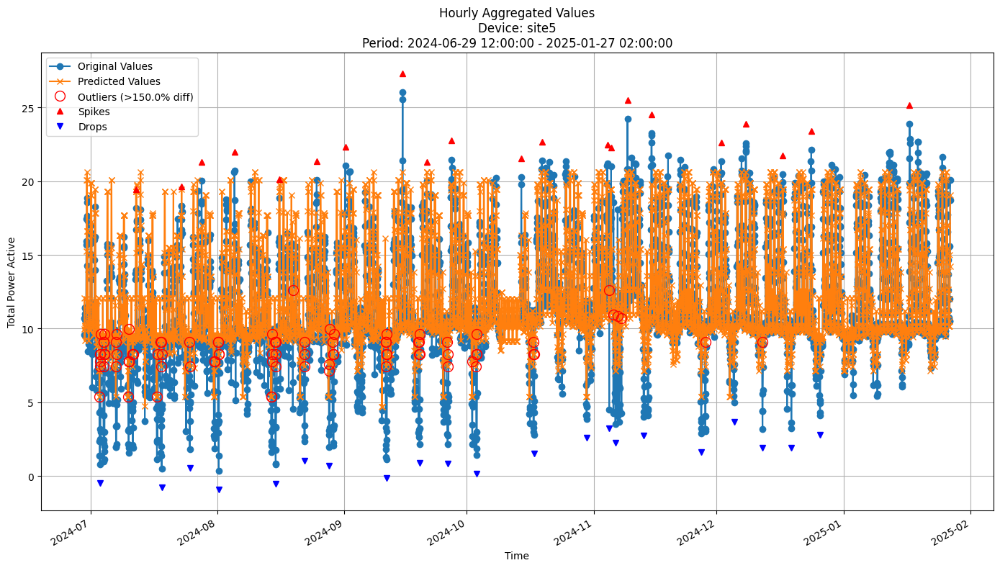


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.3300
MAE: 1.5898
MAPE: 20.5524%

Directional Metrics:
Directional Accuracy: 38.7281%
First-Diff Correlation: 0.2765

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0541
  Recall: 0.0952
  F1 Score: 0.0690
Drops:
  Precision: 0.0500
  Recall: 0.0476
  F1 Score: 0.0488

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0811
  Recall: 0.1429
  F1 Score: 0.1034
Drops:
  Precision: 0.0500
  Recall: 0.0476
  F1 Score: 0.0488


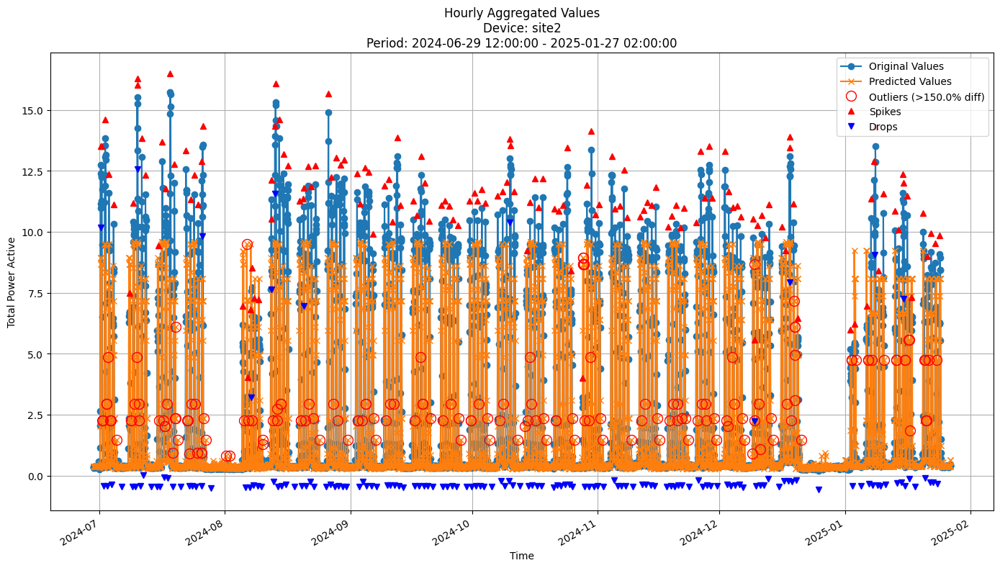


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.4456
MAE: 0.7177
MAPE: 32.1565%

Directional Metrics:
Directional Accuracy: 36.8183%
First-Diff Correlation: 0.5521

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1243
  Recall: 0.1486
  F1 Score: 0.1354
Drops:
  Precision: 0.0497
  Recall: 0.0608
  F1 Score: 0.0547

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3446
  Recall: 0.4122
  F1 Score: 0.3754
Drops:
  Precision: 0.1602
  Recall: 0.1959
  F1 Score: 0.1763


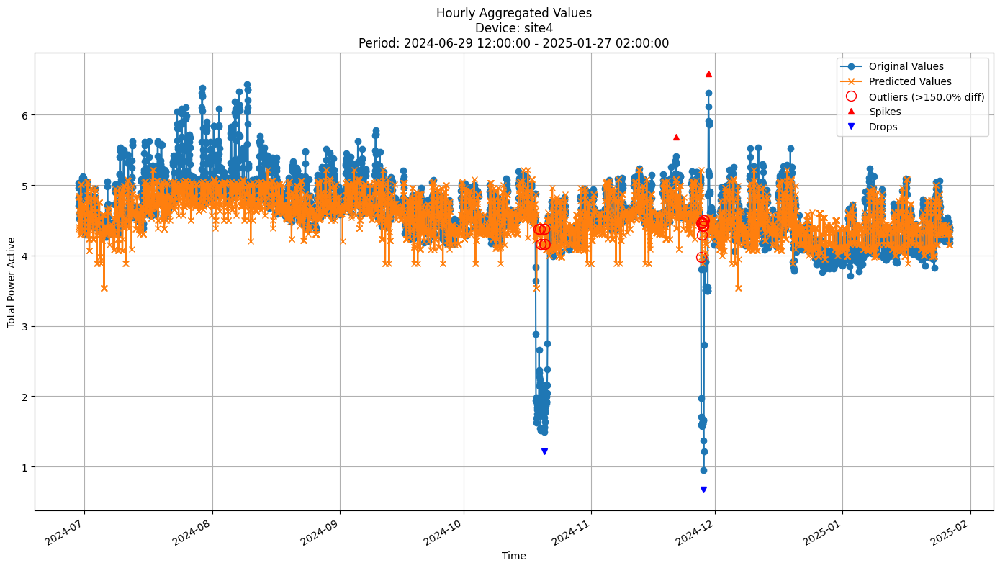


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.4218
MAE: 0.2315
MAPE: 6.3525%

Directional Metrics:
Directional Accuracy: 27.9386%
First-Diff Correlation: 0.0845

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


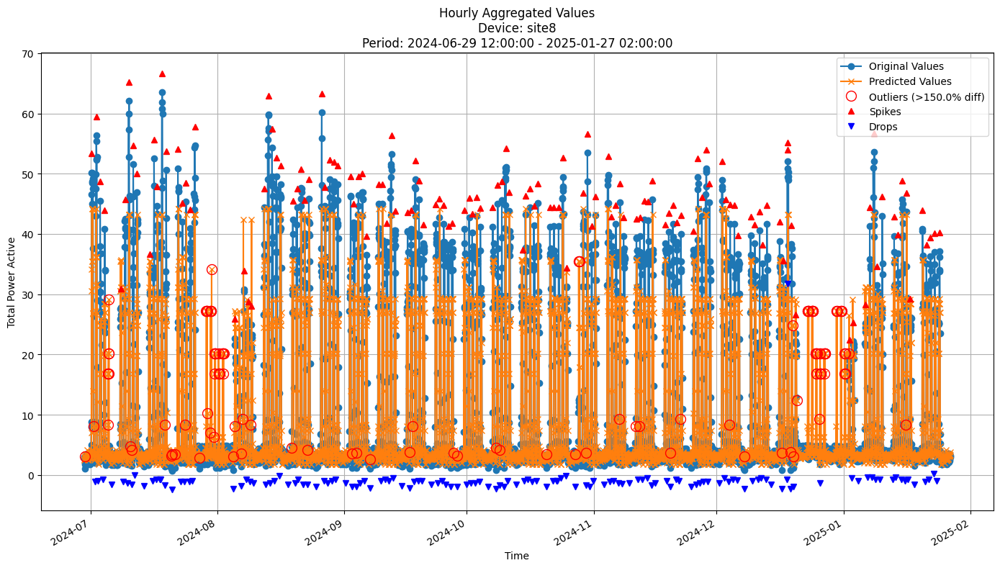


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 6.1576
MAE: 3.1621
MAPE: 36.1987%

Directional Metrics:
Directional Accuracy: 43.5125%
First-Diff Correlation: 0.5041

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1095
  Recall: 0.1704
  F1 Score: 0.1333
Drops:
  Precision: 0.0885
  Recall: 0.1471
  F1 Score: 0.1105

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2714
  Recall: 0.4222
  F1 Score: 0.3304
Drops:
  Precision: 0.2212
  Recall: 0.3676
  F1 Score: 0.2762


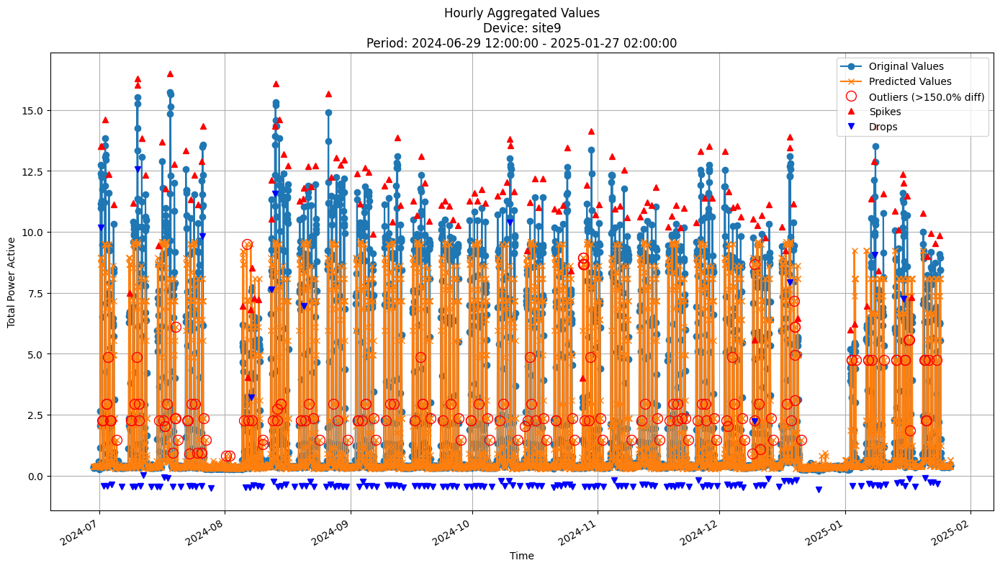


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.4456
MAE: 0.7177
MAPE: 32.1565%

Directional Metrics:
Directional Accuracy: 36.8183%
First-Diff Correlation: 0.5521

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1243
  Recall: 0.1486
  F1 Score: 0.1354
Drops:
  Precision: 0.0497
  Recall: 0.0608
  F1 Score: 0.0547

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3446
  Recall: 0.4122
  F1 Score: 0.3754
Drops:
  Precision: 0.1602
  Recall: 0.1959
  F1 Score: 0.1763


In [ ]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

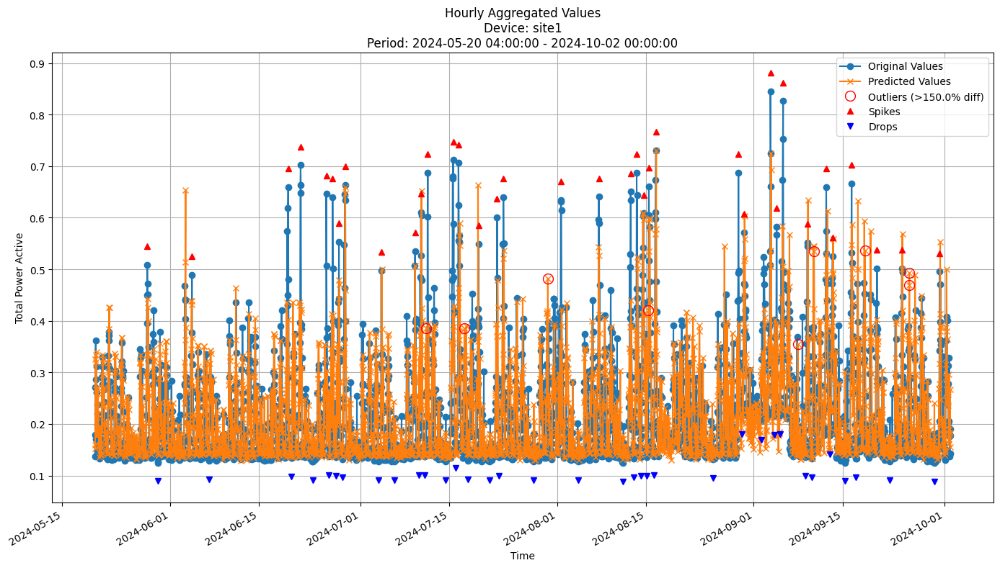


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0777
MAE: 0.0473
MAPE: 20.0677%

Directional Metrics:
Directional Accuracy: 52.6576%
First-Diff Correlation: 0.1740

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0526
  Recall: 0.0286
  F1 Score: 0.0370

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1667
  Recall: 0.0833
  F1 Score: 0.1111
Drops:
  Precision: 0.1053
  Recall: 0.0571
  F1 Score: 0.0741


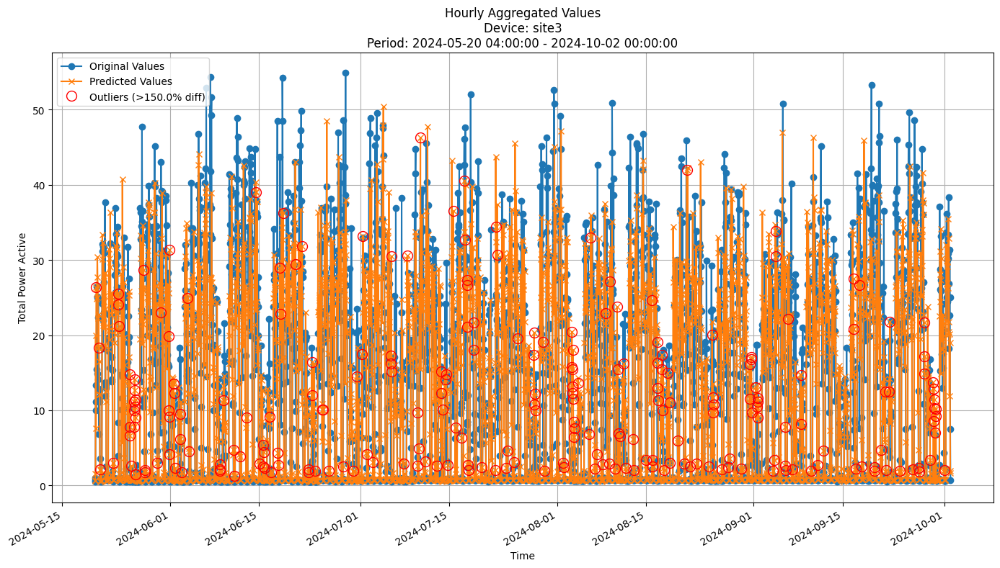


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 7.6404
MAE: 4.9873
MAPE: 64.5629%

Directional Metrics:
Directional Accuracy: 47.9604%
First-Diff Correlation: 0.3705

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


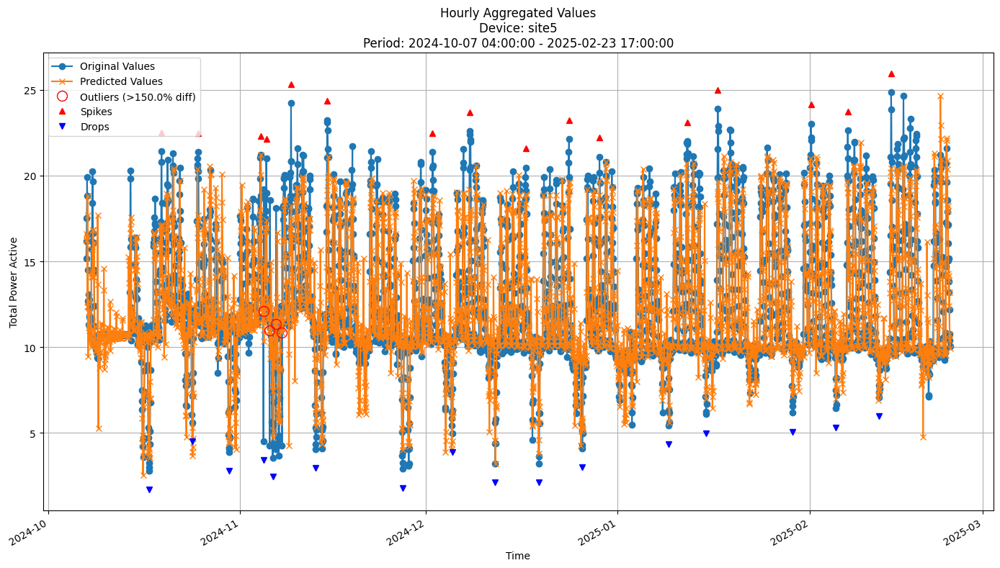


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.8311
MAE: 1.1969
MAPE: 9.8418%

Directional Metrics:
Directional Accuracy: 53.0448%
First-Diff Correlation: 0.3064

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1429
  Recall: 0.0625
  F1 Score: 0.0870
Drops:
  Precision: 0.3750
  Recall: 0.1875
  F1 Score: 0.2500


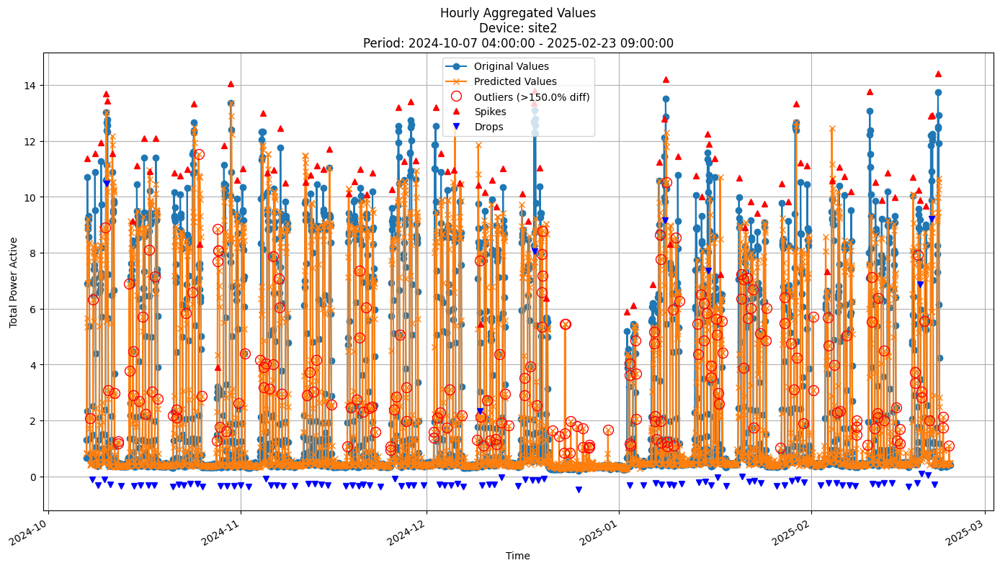


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.5889
MAE: 0.7885
MAPE: 43.4063%

Directional Metrics:
Directional Accuracy: 48.2047%
First-Diff Correlation: 0.3162

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0654
  Recall: 0.1010
  F1 Score: 0.0794
Drops:
  Precision: 0.0645
  Recall: 0.1020
  F1 Score: 0.0791

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2549
  Recall: 0.3939
  F1 Score: 0.3095
Drops:
  Precision: 0.2258
  Recall: 0.3571
  F1 Score: 0.2767


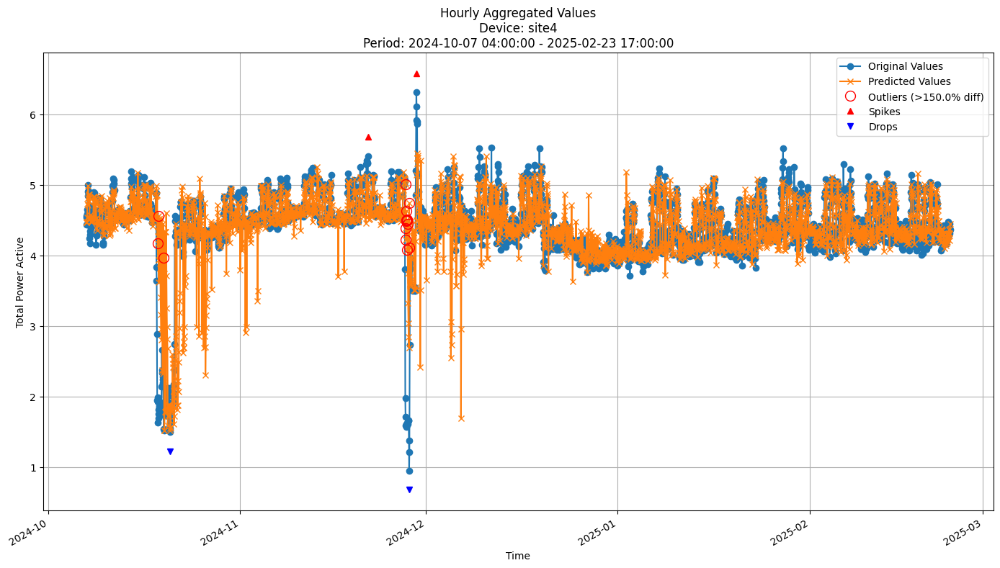


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.4073
MAE: 0.1992
MAPE: 5.7506%

Directional Metrics:
Directional Accuracy: 43.8507%
First-Diff Correlation: 0.0111

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.1333
  Recall: 1.0000
  F1 Score: 0.2353


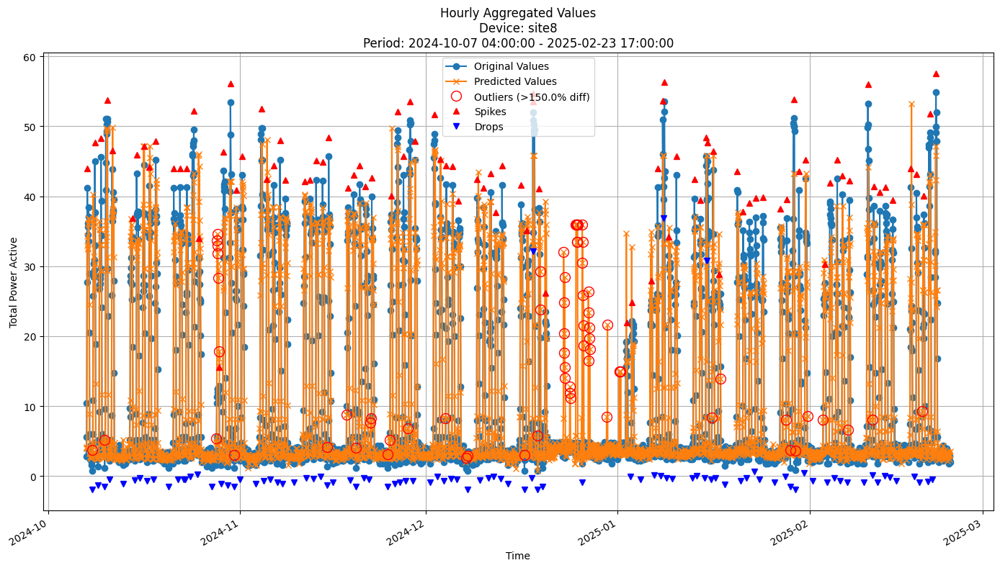


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 5.1202
MAE: 2.6009
MAPE: 31.2931%

Directional Metrics:
Directional Accuracy: 48.3284%
First-Diff Correlation: 0.5737

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1311
  Recall: 0.1684
  F1 Score: 0.1475
Drops:
  Precision: 0.0476
  Recall: 0.0632
  F1 Score: 0.0543

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3607
  Recall: 0.4632
  F1 Score: 0.4055
Drops:
  Precision: 0.2143
  Recall: 0.2842
  F1 Score: 0.2443


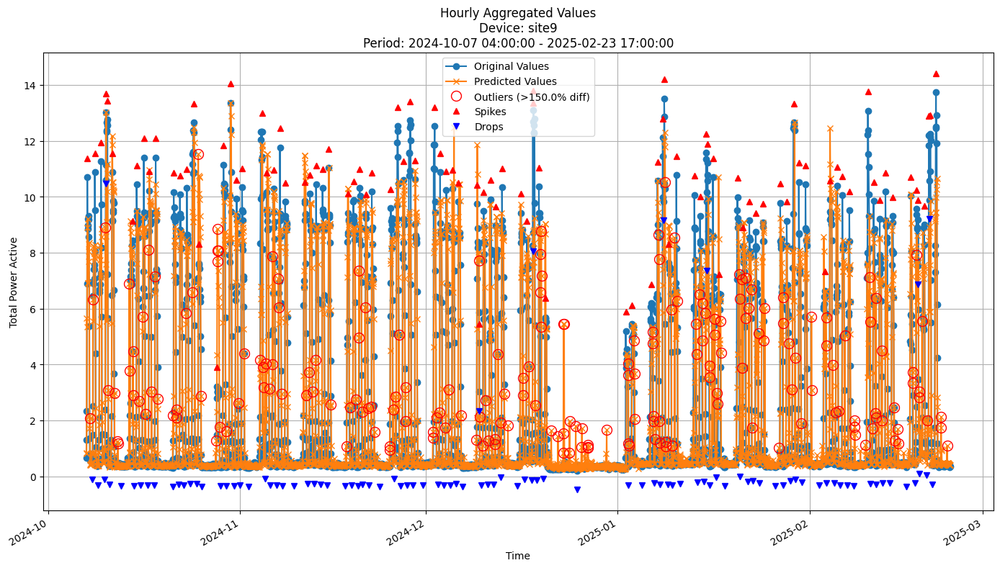


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.5870
MAE: 0.7868
MAPE: 43.3435%

Directional Metrics:
Directional Accuracy: 48.1791%
First-Diff Correlation: 0.3162

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0654
  Recall: 0.1010
  F1 Score: 0.0794
Drops:
  Precision: 0.0645
  Recall: 0.1020
  F1 Score: 0.0791

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2549
  Recall: 0.3939
  F1 Score: 0.3095
Drops:
  Precision: 0.2258
  Recall: 0.3571
  F1 Score: 0.2767


In [ ]:
join_periods = [-5, -4, -3, -2, -1]
# Device iteration
for device_id in fodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (FastODT)

In [ ]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf = ARFRegressorFODT
arf_params = {
    'n_models': 60, 
     'max_feature': 0.5, 
     'max_depth': 30, 
     'aggregation_method': 'mean', 
     'disable_weighted_vote': True, 
     'eagerness': 0, 
     'tau': 0.01, 
     'delta': 0.1, 
     'grace_period': 0, 
     'grace_period_depth': 0, 
     'bin_type': 'mean', 
     'split_criterion': 'vr_rel'
}

In [ ]:
arf_all_train_preds, arf_all_valid_preds, \
arf_all_train_metrics, arf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf,
    model_params=arf_params,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 03:00:00+01:00 to 2023-03-27 03:00:00+02:00
Model's memory usage: 146.282555 MB
Metrics for Device: site1 | Period: 2023-03-27 04:00:00+02:00 - 2023-04-24 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0743
	MAE: 0.0547
	MAPE: 20.9156%

Directional Metrics:
	Directional Accuracy: 62.1461%
	First-Diff Correlation: 0.3296

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2000
		Recall: 0.1739
		F1: 0.1860
	Drops:
		Precision: 0.2632
		Recall: 0.2273
		F1: 0.2439

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.4000
		Recall: 0.3478
		F1: 0.3721
	Drops:
		Precision: 0.4211
		Recall: 0.3636
		F1: 0.3902
--------------------------------------------------
D

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 03:00:00+01:00 to 2023-04-24 03:00:00+02:00
Model's memory usage: 179.969505 MB
Metrics for Device: site1 | Period: 2023-04-24 04:00:00+02:00 - 2023-05-22 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0460
	MAE: 0.0344
	MAPE: 18.2216%

Directional Metrics:
	Directional Accuracy: 60.6557%
	First-Diff Correlation: 0.3979

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0800
		Recall: 0.0465
		F1: 0.0588
	Drops:
		Precision: 0.1250
		Recall: 0.0652
		F1: 0.0857

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2000
		Recall: 0.1163
		F1: 0.1471
	Drops:
		Precision: 0.4167
		Recall: 0.2174
		F1: 0.2857
--------------------------------------------------
D

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 12:00:00+02:00 to 2024-12-30 02:00:00+01:00
Model's memory usage: 335.307808 MB
Metrics for Device: site5 | Period: 2024-12-30 03:00:00+01:00 - 2025-01-27 02:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.3834
	MAE: 0.9855
	MAPE: 7.4085%

Directional Metrics:
	Directional Accuracy: 69.5976%
	First-Diff Correlation: 0.5488

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1667
		Recall: 0.1667
		F1: 0.1667
	Drops:
		Precision: 0.3158
		Recall: 0.3158
		F1: 0.3158

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5556
		Recall: 0.5556
		F1: 0.5556
	Drops:
		Precision: 0.7895
		Recall: 0.7895
		F1: 0.7895
--------------------------------------------------
Da

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 12:00:00+02:00 to 2025-01-27 02:00:00+01:00
Model's memory usage: 320.963341 MB
Metrics for Device: site5 | Period: 2025-01-27 03:00:00+01:00 - 2025-02-23 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.3711
	MAE: 0.9389
	MAPE: 6.6674%

Directional Metrics:
	Directional Accuracy: 72.2054%
	First-Diff Correlation: 0.5894

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2632
		Recall: 0.2632
		F1: 0.2632
	Drops:
		Precision: 0.2105
		Recall: 0.2000
		F1: 0.2051

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6842
		Recall: 0.6842
		F1: 0.6842
	Drops:
		Precision: 0.7895
		Recall: 0.7500
		F1: 0.7692
--------------------------------------------------
Da

#### Results

In [ ]:
print("\n\nTrain period metrics:")
arf_all_time_train_metrics = all_time_aggregation_metrics(arf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_all_time_valid_metrics = all_time_aggregation_metrics(arf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.1040 ± 0.0353
	MAE: 0.0740 ± 0.0336
	MAPE: 29.9317% ± 20.7818%

	Directional Metrics:
		Directional Accuracy: 61.7936% ± 7.1092%
		First-Diff Correlation: 0.4351 ± 0.1656

	Immediate Detection (delta=0):
		Spike Precision: 0.2381 ± 0.1374
		Spike Recall: 0.2040 ± 0.0992
		Spike F1: 0.2124 ± 0.1012
		Drop Precision: 0.1370 ± 0.0777
		Drop Recall: 0.1237 ± 0.0860
		Drop F1: 0.1266 ± 0.0791

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4179 ± 0.1315
		Spike Recall: 0.3754 ± 0.1099
		Spike F1: 0.3831 ± 0.0866
		Drop Precision: 0.2829 ± 0.0961
		Drop Recall: 0.2593 ± 0.1267
		Drop F1: 0.2631 ± 0.1040
Daily Metrics:
	RMSE: 1.8505 ± 0.8970
	MAE: 1.2724 ± 0.8574
	MAPE: 19.3793% ± 18.9648%

	Directional Metrics:
		Directional Accuracy: 84.9263% ± 7.6546%
		First-Diff Correlation: 0.8832 ± 0.0449

	Immediate Detection (delta=0):
		S

#### Training plots

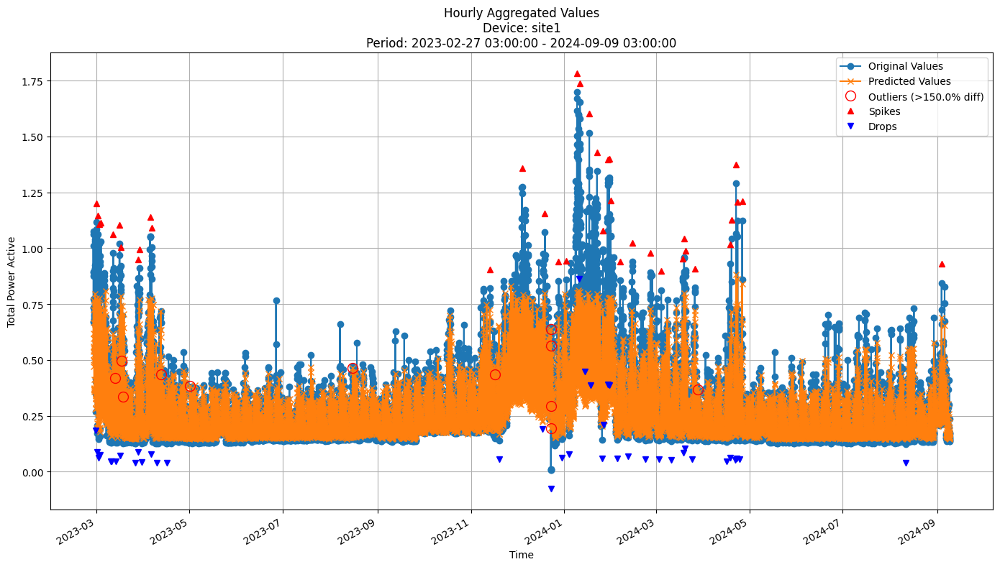


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1242
MAE: 0.0730
MAPE: 23.2104%

Directional Metrics:
Directional Accuracy: 57.4150%
First-Diff Correlation: 0.2571

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2143
  Recall: 0.1579
  F1 Score: 0.1818
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3571
  Recall: 0.2632
  F1 Score: 0.3030
Drops:
  Precision: 0.0357
  Recall: 0.0250
  F1 Score: 0.0294


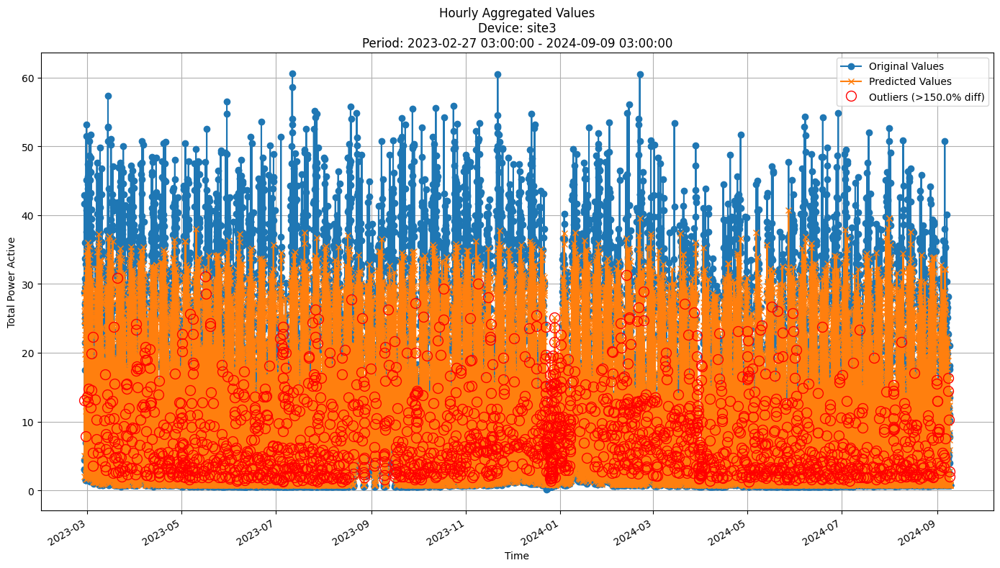


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 6.8290
MAE: 4.6884
MAPE: 85.9587%

Directional Metrics:
Directional Accuracy: 61.0164%
First-Diff Correlation: 0.5451

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


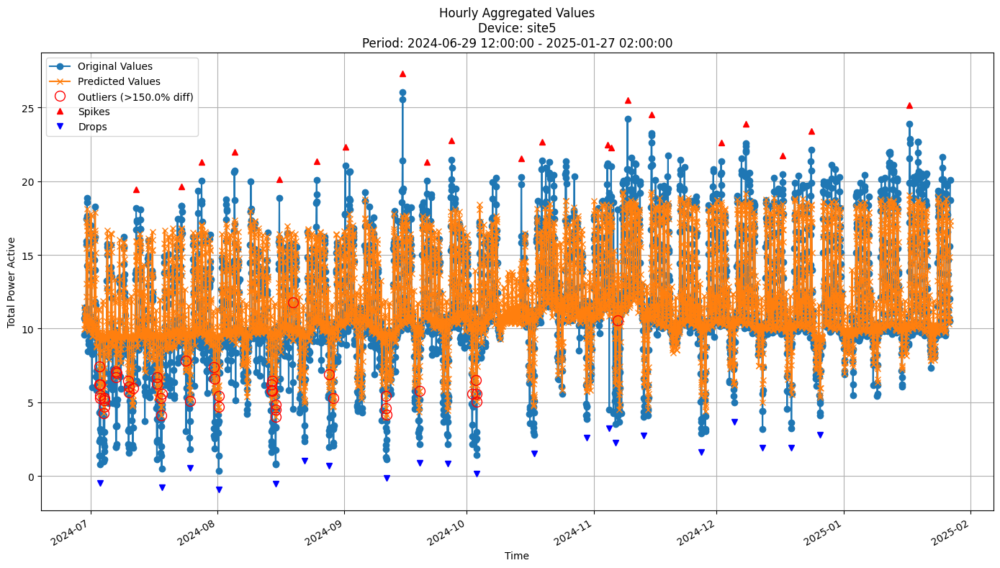


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.6267
MAE: 1.1472
MAPE: 14.1618%

Directional Metrics:
Directional Accuracy: 64.4221%
First-Diff Correlation: 0.4533

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


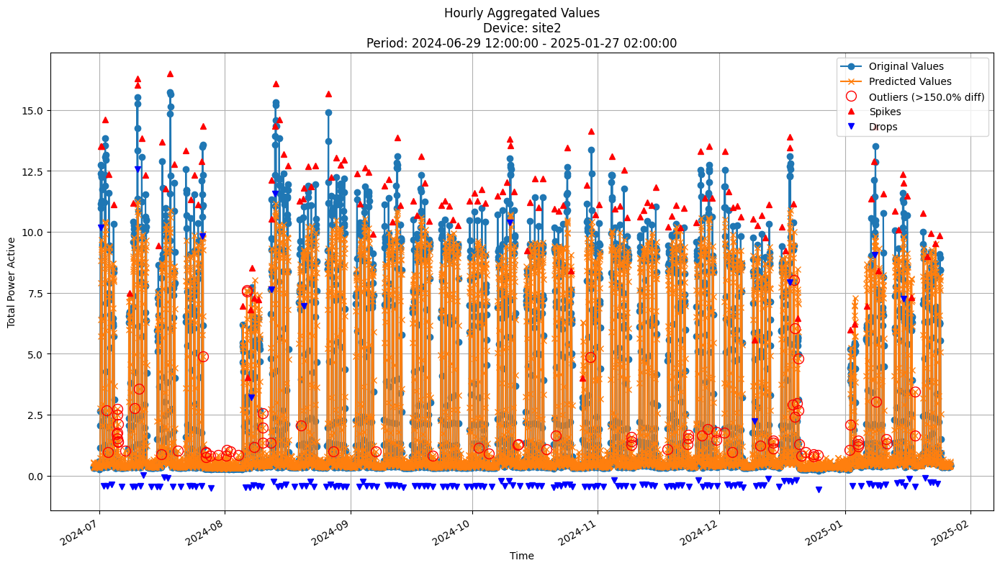


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.9525
MAE: 0.4686
MAPE: 24.8993%

Directional Metrics:
Directional Accuracy: 65.0128%
First-Diff Correlation: 0.7551

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1223
  Recall: 0.1149
  F1 Score: 0.1185
Drops:
  Precision: 0.0870
  Recall: 0.0811
  F1 Score: 0.0839

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2518
  Recall: 0.2365
  F1 Score: 0.2439
Drops:
  Precision: 0.2174
  Recall: 0.2027
  F1 Score: 0.2098


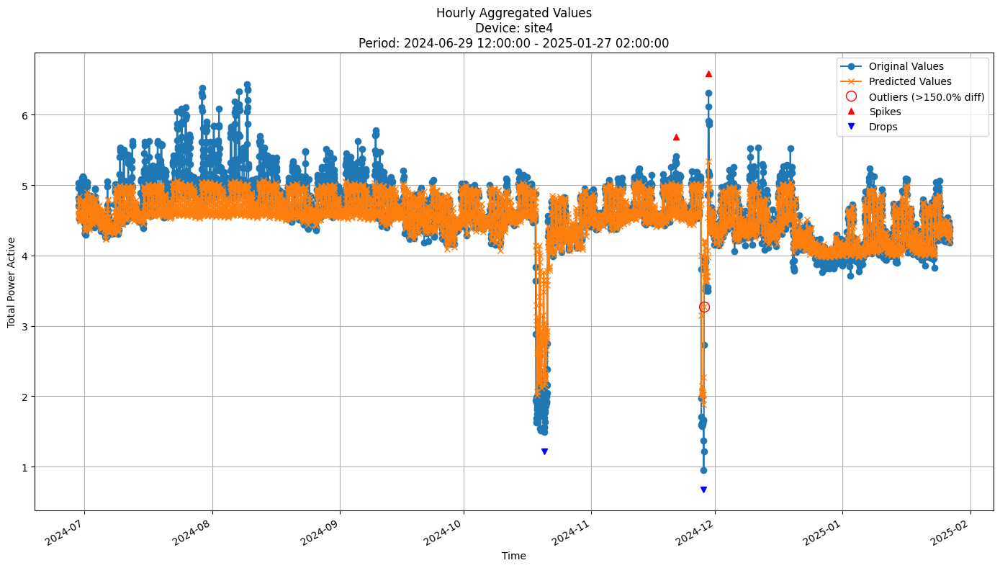


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2774
MAE: 0.1677
MAPE: 4.0086%

Directional Metrics:
Directional Accuracy: 59.4211%
First-Diff Correlation: 0.3664

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


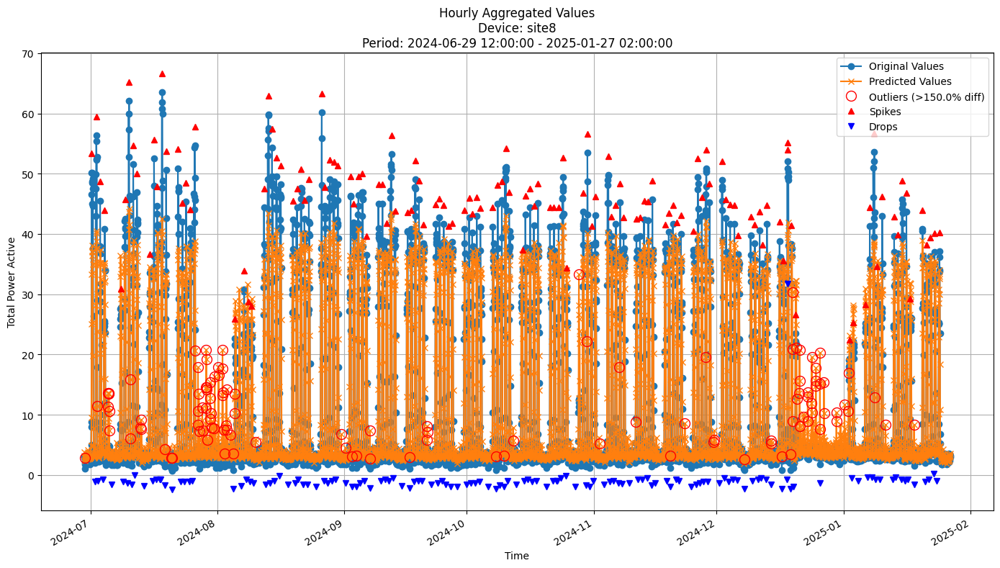


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 4.2015
MAE: 2.2474
MAPE: 28.5855%

Directional Metrics:
Directional Accuracy: 65.8200%
First-Diff Correlation: 0.7308

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1060
  Recall: 0.1185
  F1 Score: 0.1119
Drops:
  Precision: 0.1867
  Recall: 0.2059
  F1 Score: 0.1958

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2517
  Recall: 0.2815
  F1 Score: 0.2657
Drops:
  Precision: 0.3400
  Recall: 0.3750
  F1 Score: 0.3566


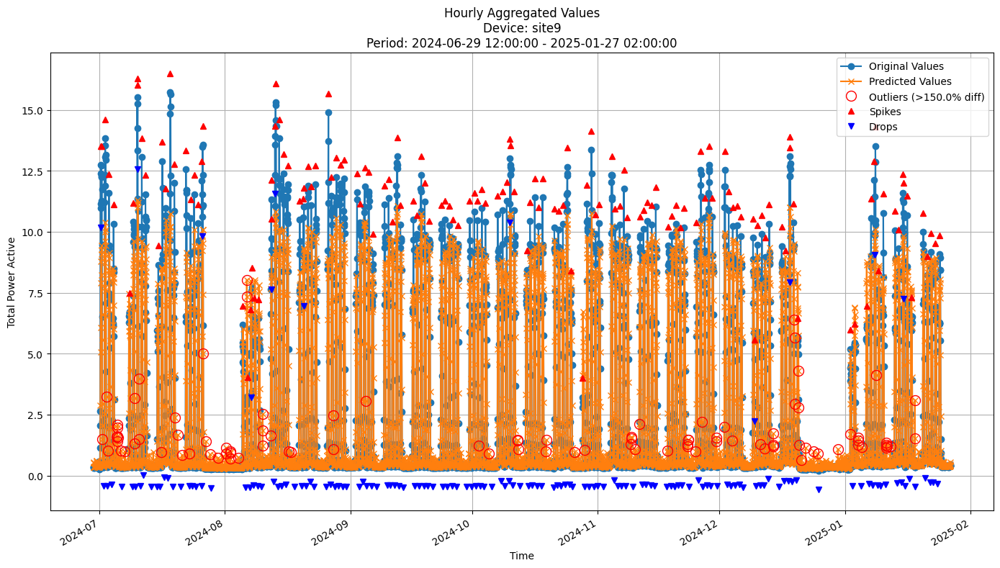


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.9760
MAE: 0.4804
MAPE: 25.7924%

Directional Metrics:
Directional Accuracy: 65.2097%
First-Diff Correlation: 0.7696

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0797
  Recall: 0.0743
  F1 Score: 0.0769
Drops:
  Precision: 0.1095
  Recall: 0.1014
  F1 Score: 0.1053

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2319
  Recall: 0.2162
  F1 Score: 0.2238
Drops:
  Precision: 0.2555
  Recall: 0.2365
  F1 Score: 0.2456


In [ ]:
for device_id in arf_all_train_preds.keys():
    y_train = arf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

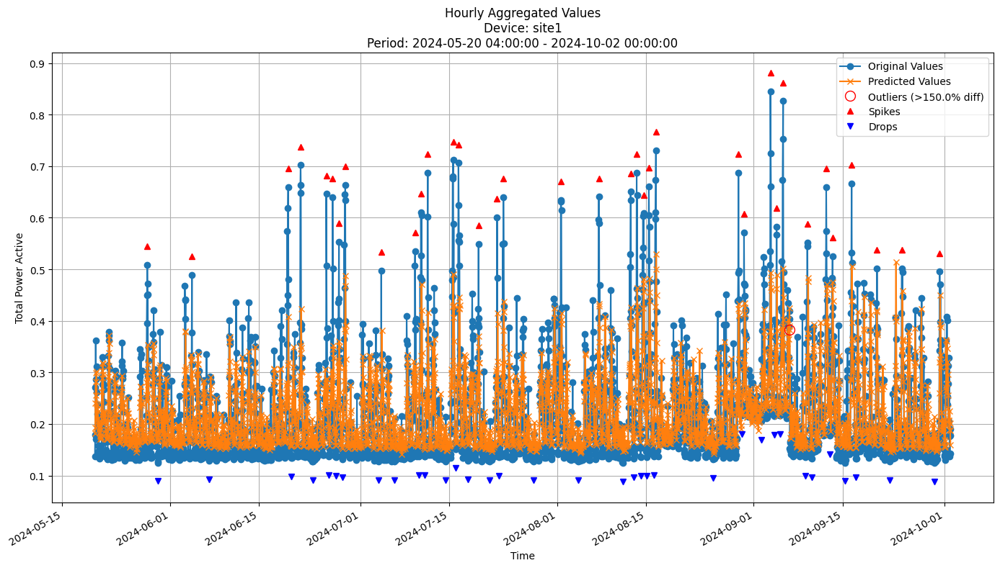


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0685
MAE: 0.0455
MAPE: 20.4706%

Directional Metrics:
Directional Accuracy: 56.6749%
First-Diff Correlation: 0.2639

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6667
  Recall: 0.0556
  F1 Score: 0.1026
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


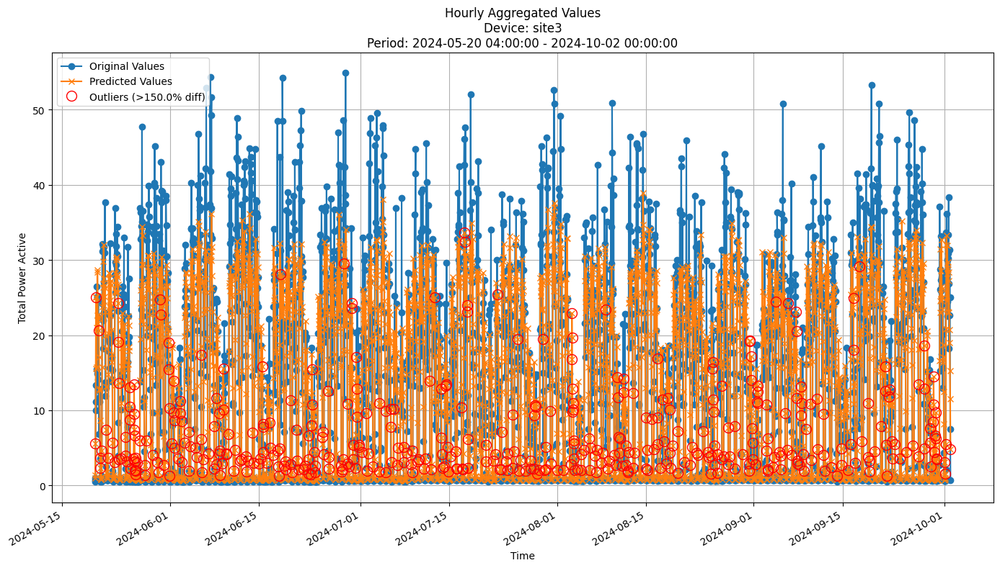


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 6.8740
MAE: 4.6684
MAPE: 77.4656%

Directional Metrics:
Directional Accuracy: 54.4499%
First-Diff Correlation: 0.4087

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


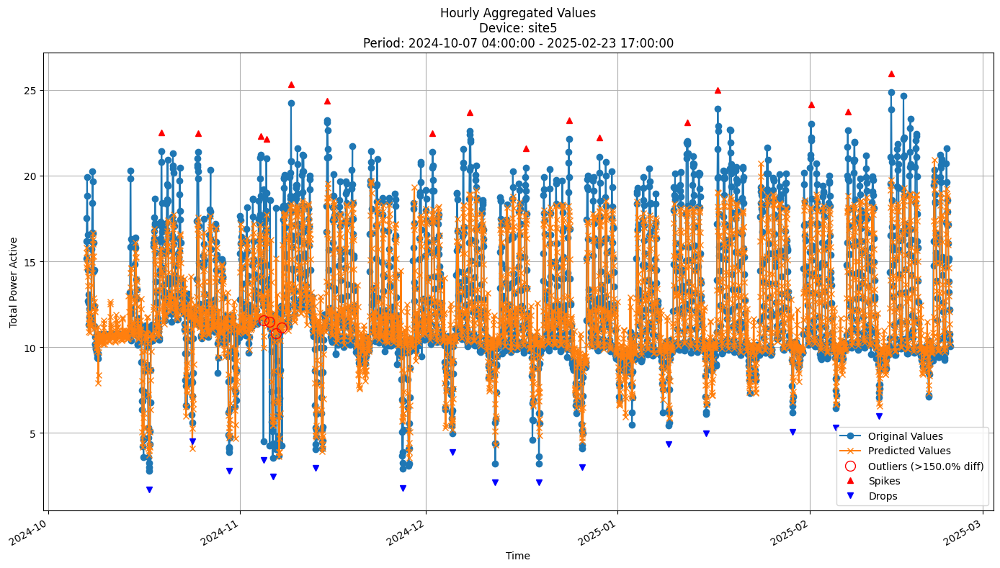


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.5275
MAE: 1.0522
MAPE: 8.4365%

Directional Metrics:
Directional Accuracy: 64.3284%
First-Diff Correlation: 0.4538

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


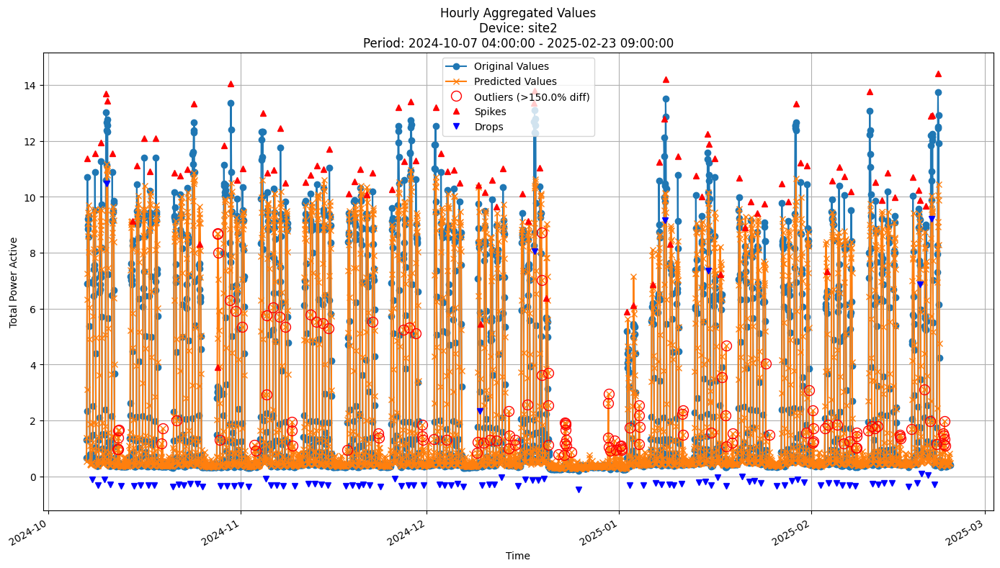


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.9940
MAE: 0.5265
MAPE: 31.9940%

Directional Metrics:
Directional Accuracy: 61.3704%
First-Diff Correlation: 0.6638

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0745
  Recall: 0.0707
  F1 Score: 0.0725
Drops:
  Precision: 0.1290
  Recall: 0.1224
  F1 Score: 0.1257

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1809
  Recall: 0.1717
  F1 Score: 0.1762
Drops:
  Precision: 0.2688
  Recall: 0.2551
  F1 Score: 0.2618


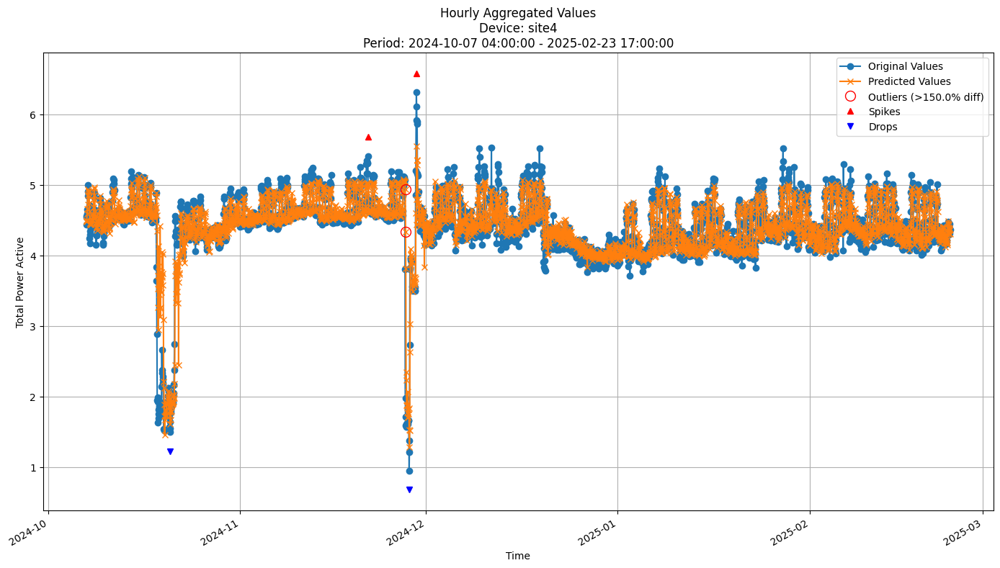


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2463
MAE: 0.1305
MAPE: 3.4969%

Directional Metrics:
Directional Accuracy: 52.2985%
First-Diff Correlation: 0.1441

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000


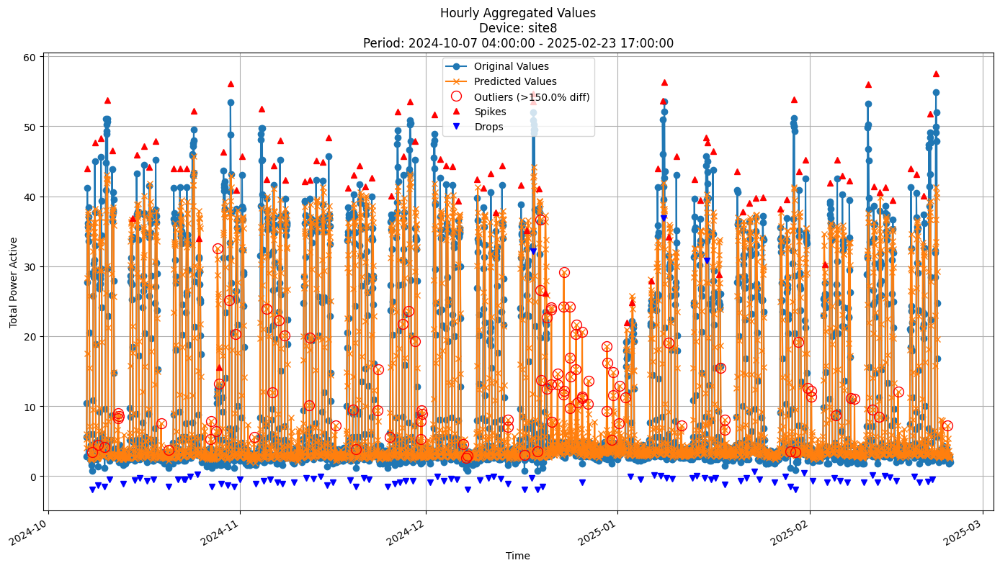


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 4.3506
MAE: 2.3872
MAPE: 31.7451%

Directional Metrics:
Directional Accuracy: 57.8507%
First-Diff Correlation: 0.6103

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0495
  Recall: 0.0526
  F1 Score: 0.0510
Drops:
  Precision: 0.0600
  Recall: 0.0632
  F1 Score: 0.0615

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1782
  Recall: 0.1895
  F1 Score: 0.1837
Drops:
  Precision: 0.2000
  Recall: 0.2105
  F1 Score: 0.2051


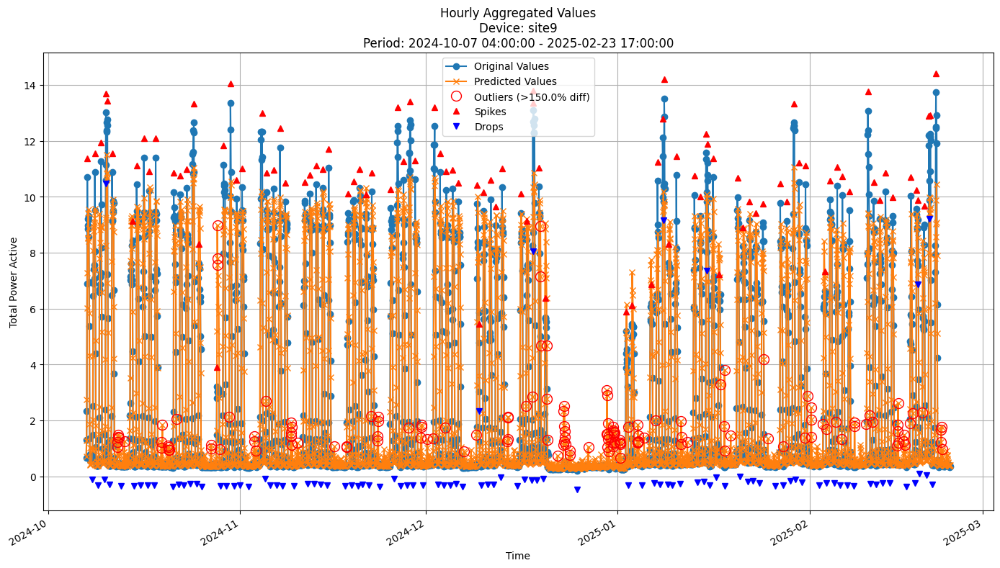


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.9751
MAE: 0.5209
MAPE: 33.7665%

Directional Metrics:
Directional Accuracy: 62.0000%
First-Diff Correlation: 0.6950

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0851
  Recall: 0.0808
  F1 Score: 0.0829
Drops:
  Precision: 0.1075
  Recall: 0.1020
  F1 Score: 0.1047

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2021
  Recall: 0.1919
  F1 Score: 0.1969
Drops:
  Precision: 0.1613
  Recall: 0.1531
  F1 Score: 0.1571


In [ ]:
join_periods = [-5, -4, -3, -2, -1]
# Device iteration
for device_id in arf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost

In [ ]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:


incb = IncubationBoost
incb_params = {
    "base_learner": fastodt.FastODT,
    'length': 20, 
    'learning_rate': 0.5, 
    'depth': 5, 
    'grace_period': 48, 
    'grace_period_depth': -1, 
    'split_confidence': 0.5, 
    'max_feature': 1.0, 
    'tie_threshold': 0.05, 
    'bin_type': 'adaptive', 
    'max_bins': 4, 
    'split_criterion': 'vr_rel', 
    'verbose': False
}


In [ ]:
incb_all_train_preds, incb_all_valid_preds, \
incb_all_train_metrics, incb_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=incb, 
    model_params=incb_params,
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    # end_split=1,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 03:00:00+01:00 to 2023-03-27 03:00:00+02:00
Model's memory usage: 0.447441 MB
Metrics for Device: site1 | Period: 2023-03-27 04:00:00+02:00 - 2023-04-24 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2072
	MAE: 0.1371
	MAPE: 36.9027%

Directional Metrics:
	Directional Accuracy: 9.5380%
	First-Diff Correlation: 0.0842

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1818
		Recall: 0.0870
		F1: 0.1176
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5455
		Recall: 0.2609
		F1: 0.3529
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Dail

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 03:00:00+01:00 to 2023-04-24 03:00:00+02:00
Model's memory usage: 0.606918 MB
Metrics for Device: site1 | Period: 2023-04-24 04:00:00+02:00 - 2023-05-22 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0782
	MAE: 0.0568
	MAPE: 30.5727%

Directional Metrics:
	Directional Accuracy: 8.6438%
	First-Diff Correlation: 0.0145

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1818
		Recall: 0.0465
		F1: 0.0741
	Drops:
		Precision: 0.0625
		Recall: 0.0217
		F1: 0.0323

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6364
		Recall: 0.1628
		F1: 0.2593
	Drops:
		Precision: 0.0625
		Recall: 0.0217
		F1: 0.0323
--------------------------------------------------
Dail

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 12:00:00+02:00 to 2024-12-30 02:00:00+01:00
Model's memory usage: 0.627052 MB
Metrics for Device: site5 | Period: 2024-12-30 03:00:00+01:00 - 2025-01-27 02:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 5.5235
	MAE: 4.5849
	MAPE: 33.3484%

Directional Metrics:
	Directional Accuracy: 12.3696%
	First-Diff Correlation: 0.1978

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.1176
		Recall: 0.2105
		F1: 0.1509

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2121
		Recall: 0.3889
		F1: 0.2745
	Drops:
		Precision: 0.4706
		Recall: 0.8421
		F1: 0.6038
--------------------------------------------------
Dai

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 12:00:00+02:00 to 2025-01-27 02:00:00+01:00
Model's memory usage: 0.627647 MB
Metrics for Device: site5 | Period: 2025-01-27 03:00:00+01:00 - 2025-02-23 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 5.9436
	MAE: 4.9127
	MAPE: 34.0855%

Directional Metrics:
	Directional Accuracy: 11.4804%
	First-Diff Correlation: 0.1050

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1724
		Recall: 0.2632
		F1: 0.2083
	Drops:
		Precision: 0.1034
		Recall: 0.1500
		F1: 0.1224

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3793
		Recall: 0.5789
		F1: 0.4583
	Drops:
		Precision: 0.3448
		Recall: 0.5000
		F1: 0.4082
--------------------------------------------------
Dai

#### Results

In [ ]:
print("\n\nTrain period metrics:")
incb_all_time_train_metrics = all_time_aggregation_metrics(incb_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
incb_all_time_valid_metrics = all_time_aggregation_metrics(incb_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.1712 ± 0.0529
	MAE: 0.1153 ± 0.0438
	MAPE: 35.7924% ± 6.7952%

	Directional Metrics:
		Directional Accuracy: 15.1525% ± 3.2500%
		First-Diff Correlation: 0.0522 ± 0.0223

	Immediate Detection (delta=0):
		Spike Precision: 0.1119 ± 0.0189
		Spike Recall: 0.1246 ± 0.0502
		Spike F1: 0.1121 ± 0.0300
		Drop Precision: 0.0342 ± 0.0194
		Drop Recall: 0.0380 ± 0.0220
		Drop F1: 0.0339 ± 0.0159

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3196 ± 0.0711
		Spike Recall: 0.3331 ± 0.1028
		Spike F1: 0.3071 ± 0.0458
		Drop Precision: 0.1106 ± 0.0521
		Drop Recall: 0.1206 ± 0.0518
		Drop F1: 0.1091 ± 0.0380
Daily Metrics:
	RMSE: 3.3180 ± 1.2477
	MAE: 2.2465 ± 1.1149
	MAPE: 26.5746% ± 9.2780%

	Directional Metrics:
		Directional Accuracy: 48.6607% ± 8.9282%
		First-Diff Correlation: 0.4660 ± 0.1280

	Immediate Detection (delta=0):
		Spi

#### Train plots

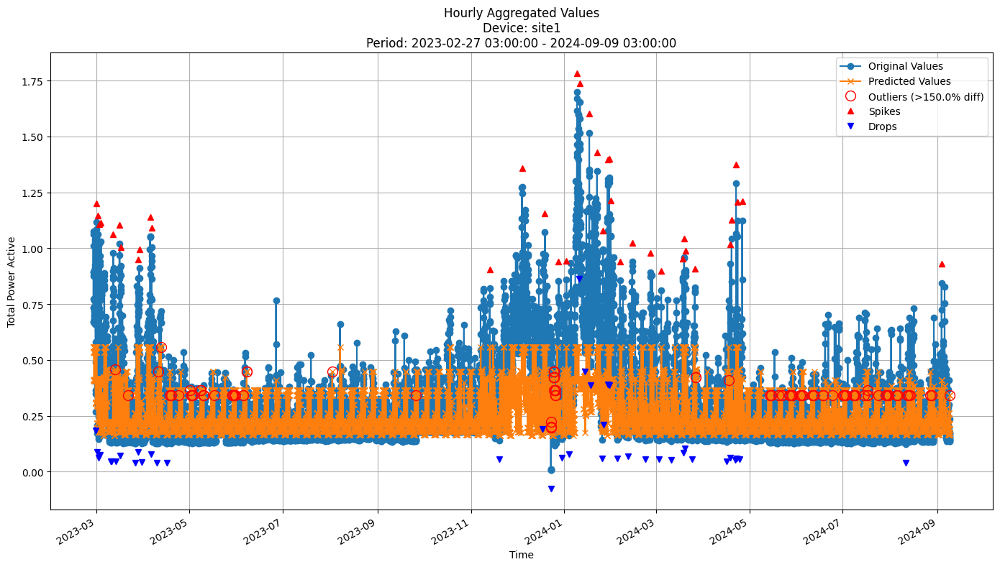


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1697
MAE: 0.1122
MAPE: 37.0658%

Directional Metrics:
Directional Accuracy: 15.8345%
First-Diff Correlation: 0.0239

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0769
  Recall: 0.2368
  F1 Score: 0.1161
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1197
  Recall: 0.3684
  F1 Score: 0.1806
Drops:
  Precision: 0.0160
  Recall: 0.0750
  F1 Score: 0.0264


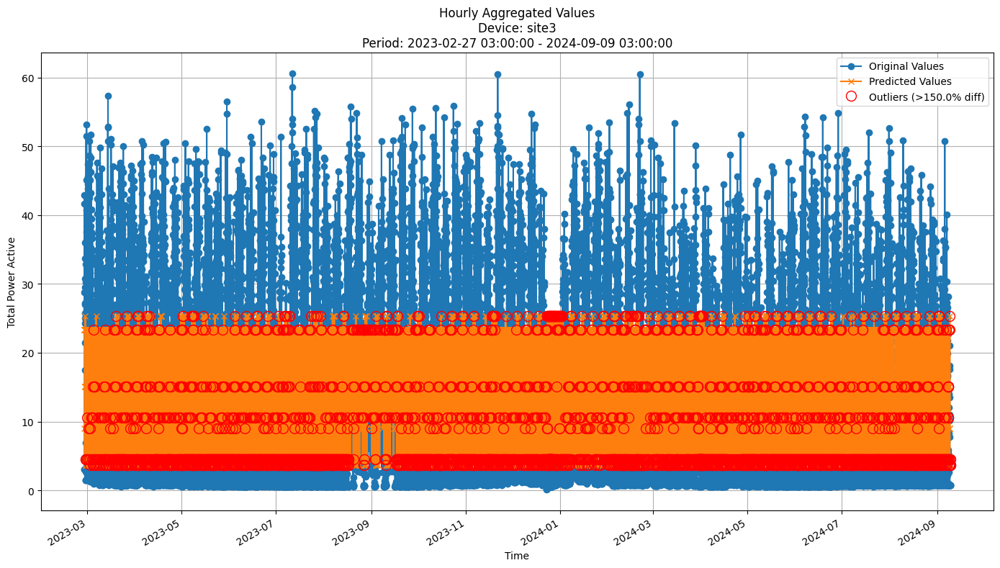


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 11.9005
MAE: 9.0685
MAPE: 283.1177%

Directional Metrics:
Directional Accuracy: 20.9465%
First-Diff Correlation: 0.1645

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


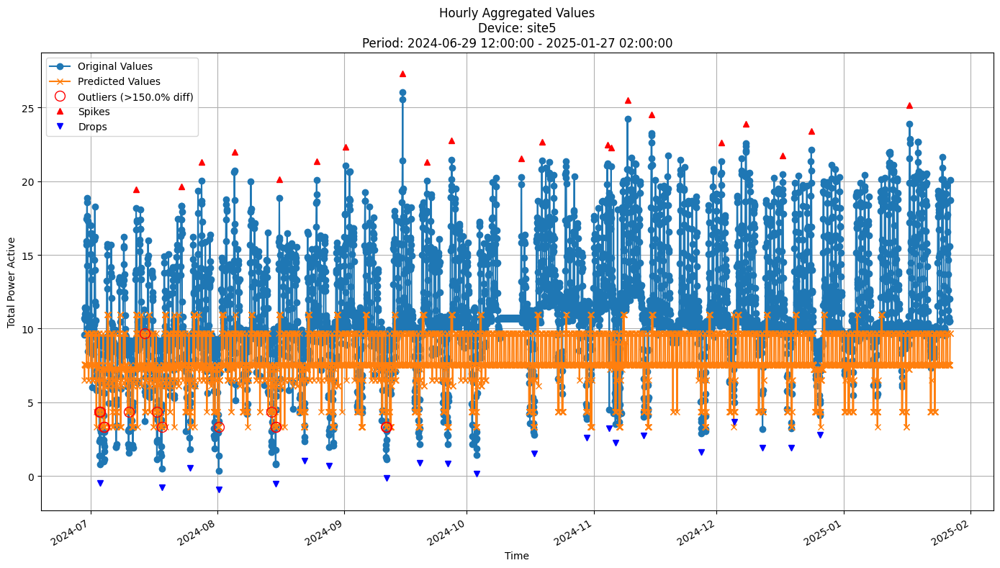


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 4.6584
MAE: 3.8245
MAPE: 32.0148%

Directional Metrics:
Directional Accuracy: 15.3377%
First-Diff Correlation: 0.0909

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0143
  Recall: 0.0952
  F1 Score: 0.0248
Drops:
  Precision: 0.0323
  Recall: 0.1429
  F1 Score: 0.0526

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0357
  Recall: 0.2381
  F1 Score: 0.0621
Drops:
  Precision: 0.1183
  Recall: 0.5238
  F1 Score: 0.1930


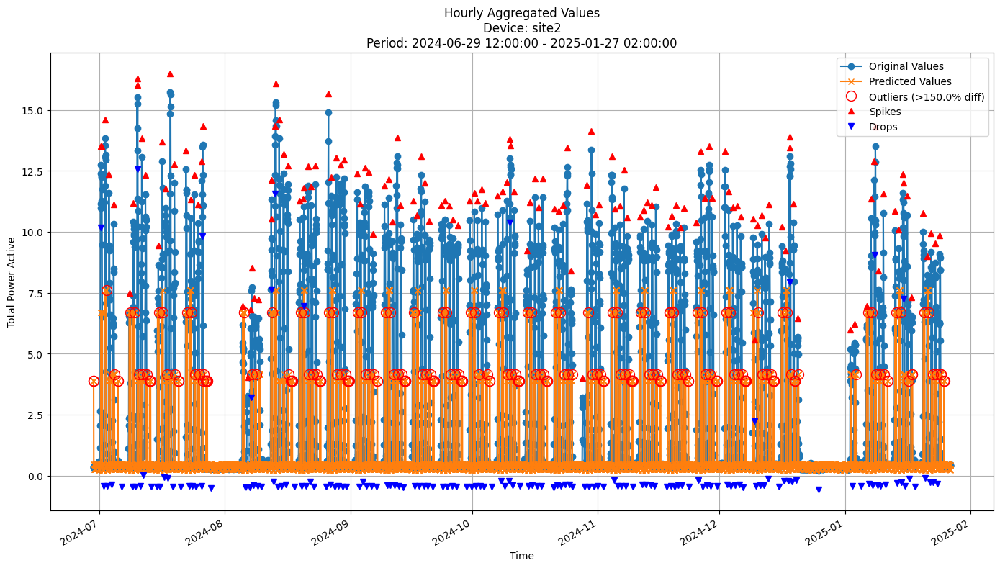


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.7953
MAE: 1.4898
MAPE: 71.4997%

Directional Metrics:
Directional Accuracy: 9.2341%
First-Diff Correlation: 0.0779

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0428
  Recall: 0.0541
  F1 Score: 0.0478
Drops:
  Precision: 0.0898
  Recall: 0.1014
  F1 Score: 0.0952

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1444
  Recall: 0.1824
  F1 Score: 0.1612
Drops:
  Precision: 0.2216
  Recall: 0.2500
  F1 Score: 0.2349


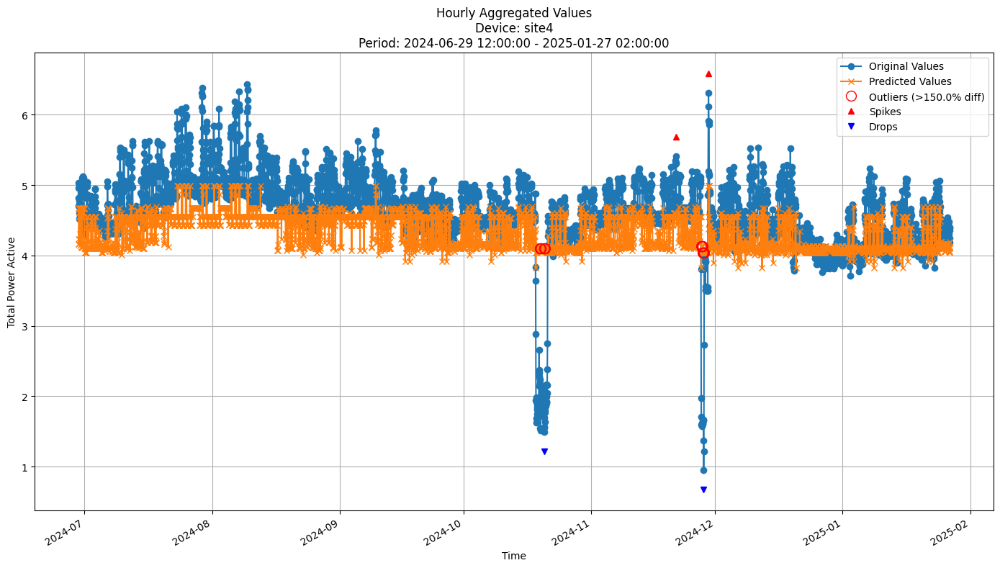


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.5073
MAE: 0.3735
MAPE: 9.1138%

Directional Metrics:
Directional Accuracy: 22.1697%
First-Diff Correlation: 0.0136

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


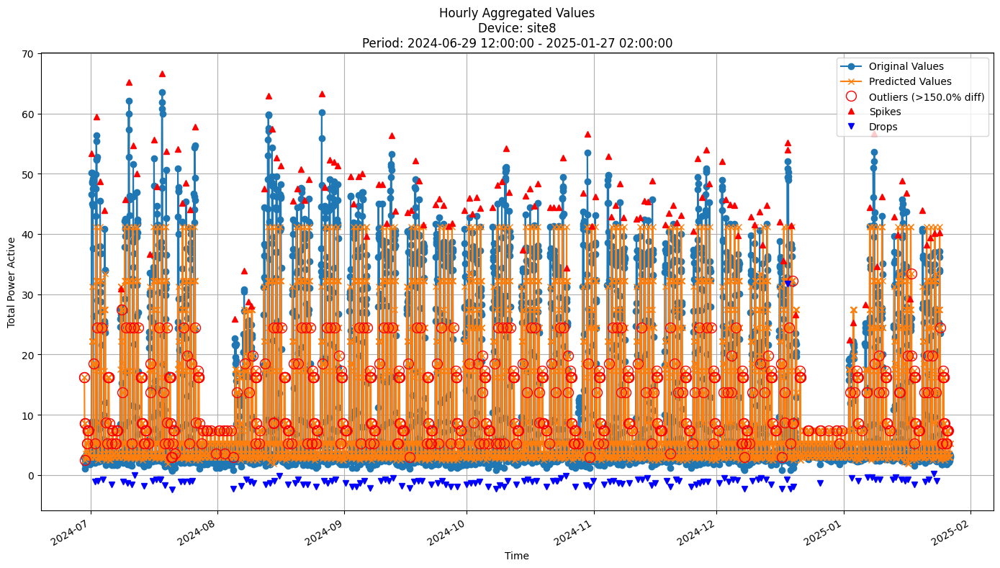


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 8.4845
MAE: 4.9126
MAPE: 72.8190%

Directional Metrics:
Directional Accuracy: 17.9957%
First-Diff Correlation: 0.1104

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1295
  Recall: 0.1333
  F1 Score: 0.1314
Drops:
  Precision: 0.0340
  Recall: 0.0368
  F1 Score: 0.0353

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3885
  Recall: 0.4000
  F1 Score: 0.3942
Drops:
  Precision: 0.0680
  Recall: 0.0735
  F1 Score: 0.0707


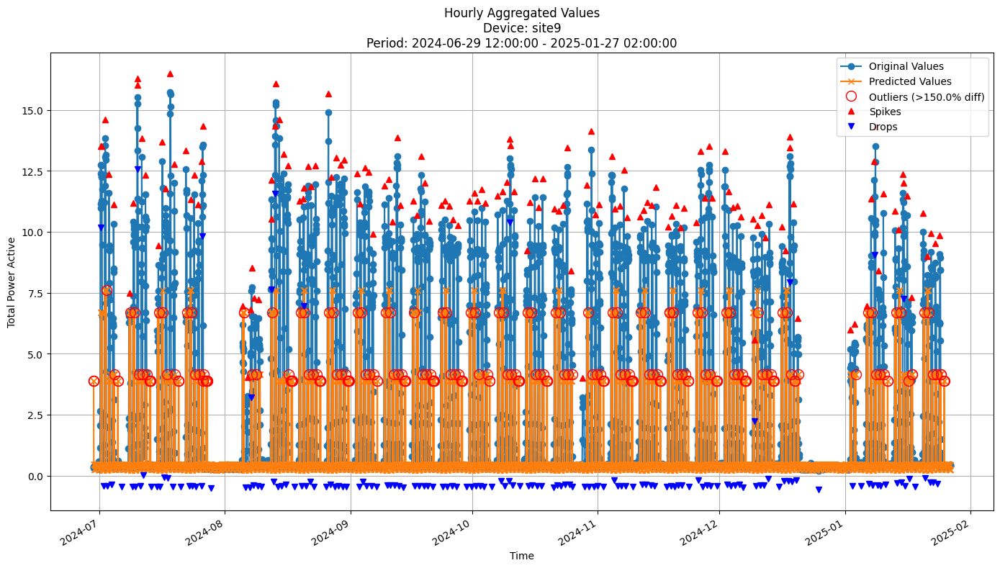


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.7953
MAE: 1.4898
MAPE: 71.4997%

Directional Metrics:
Directional Accuracy: 9.2341%
First-Diff Correlation: 0.0779

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0428
  Recall: 0.0541
  F1 Score: 0.0478
Drops:
  Precision: 0.0898
  Recall: 0.1014
  F1 Score: 0.0952

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1444
  Recall: 0.1824
  F1 Score: 0.1612
Drops:
  Precision: 0.2216
  Recall: 0.2500
  F1 Score: 0.2349


In [ ]:
for device_id in incb_all_train_preds.keys():
    y_train = incb_all_train_preds[device_id][-1]['y_true']
    y_pred_train = incb_all_train_preds[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

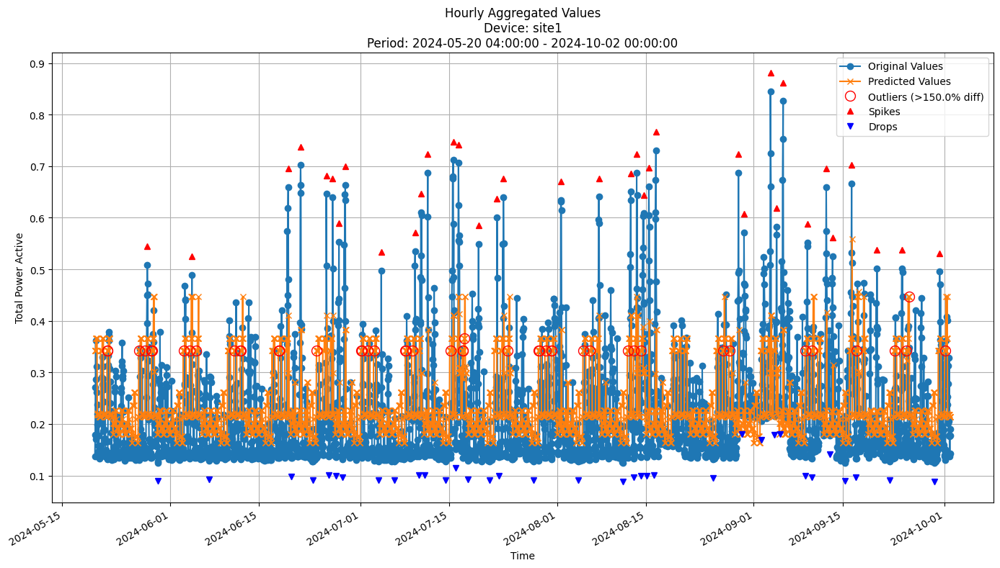


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1087
MAE: 0.0807
MAPE: 40.0773%

Directional Metrics:
Directional Accuracy: 13.5043%
First-Diff Correlation: -0.0326

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0667
  Recall: 0.0278
  F1 Score: 0.0392
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2000
  Recall: 0.0833
  F1 Score: 0.1176
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


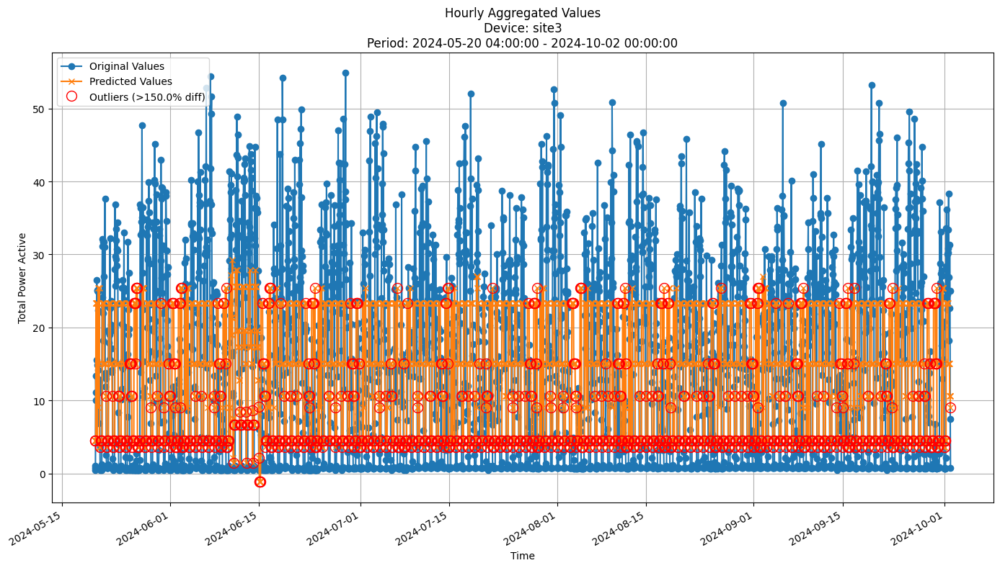


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 10.8823
MAE: 8.3724
MAPE: 287.6052%

Directional Metrics:
Directional Accuracy: 22.7441%
First-Diff Correlation: 0.1562

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


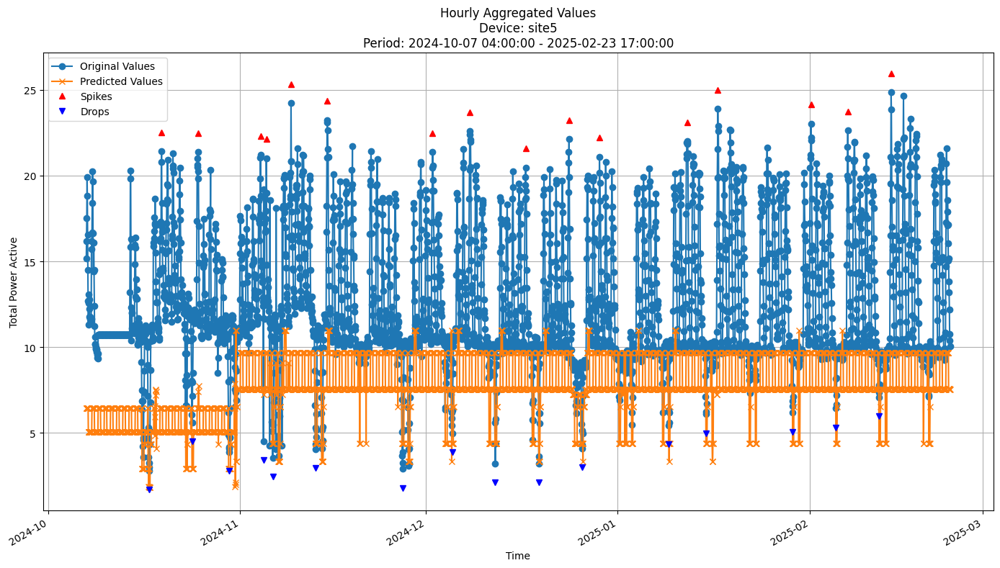


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 5.8954
MAE: 4.9952
MAPE: 37.1991%

Directional Metrics:
Directional Accuracy: 14.3582%
First-Diff Correlation: 0.0996

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


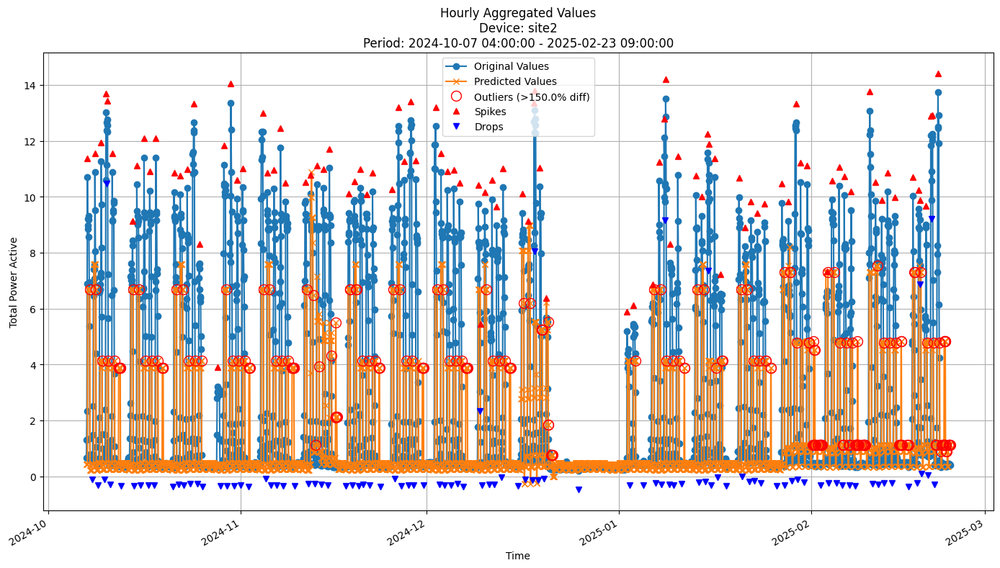


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.5529
MAE: 1.3864
MAPE: 74.8522%

Directional Metrics:
Directional Accuracy: 10.2633%
First-Diff Correlation: 0.0820

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0403
  Recall: 0.0505
  F1 Score: 0.0448
Drops:
  Precision: 0.0833
  Recall: 0.0918
  F1 Score: 0.0874

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1532
  Recall: 0.1919
  F1 Score: 0.1704
Drops:
  Precision: 0.2593
  Recall: 0.2857
  F1 Score: 0.2718


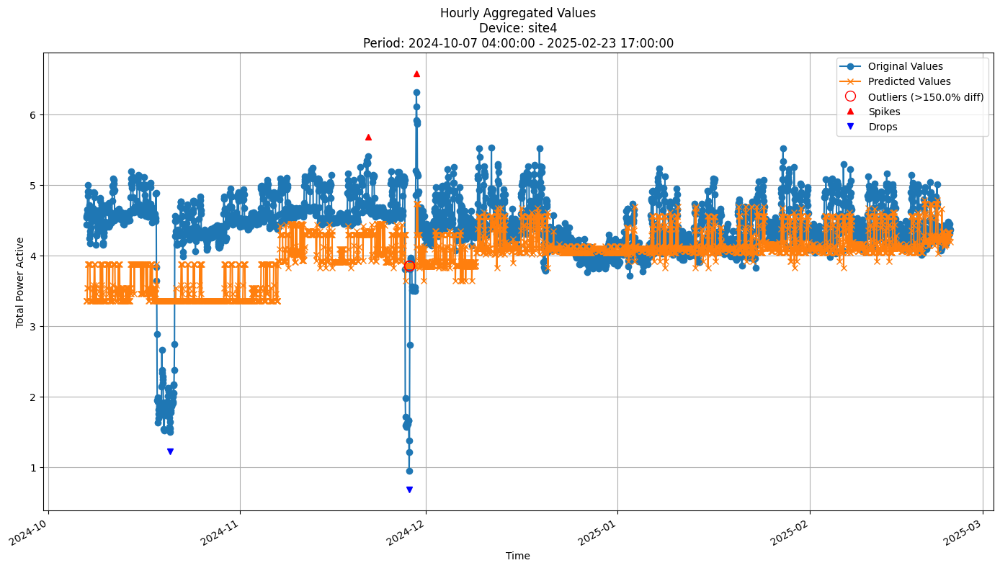


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.6491
MAE: 0.5004
MAPE: 12.3846%

Directional Metrics:
Directional Accuracy: 20.7463%
First-Diff Correlation: -0.0027

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


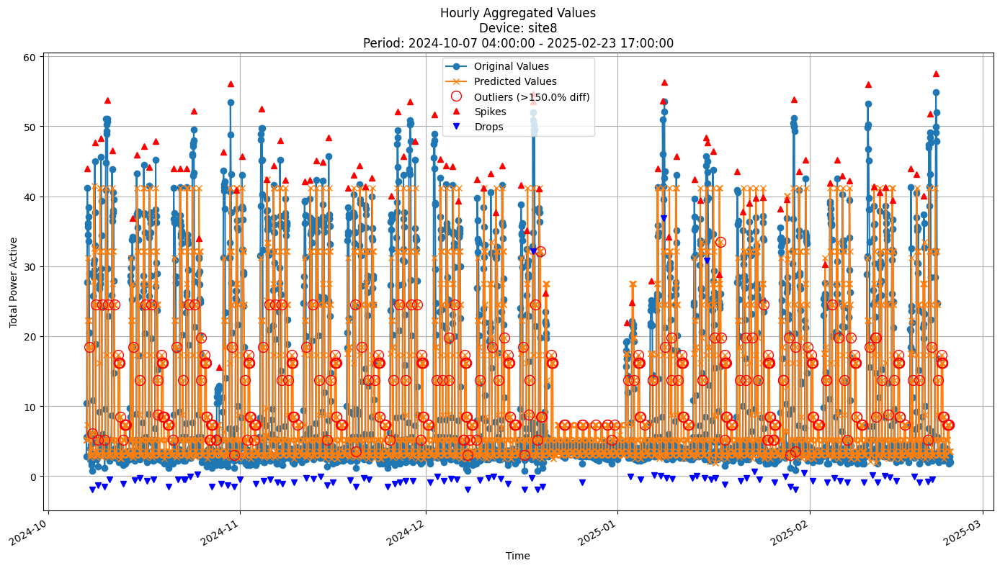


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 8.0616
MAE: 4.6651
MAPE: 68.9991%

Directional Metrics:
Directional Accuracy: 18.3582%
First-Diff Correlation: 0.0960

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0532
  Recall: 0.0526
  F1 Score: 0.0529
Drops:
  Precision: 0.0297
  Recall: 0.0316
  F1 Score: 0.0306

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3723
  Recall: 0.3684
  F1 Score: 0.3704
Drops:
  Precision: 0.0792
  Recall: 0.0842
  F1 Score: 0.0816


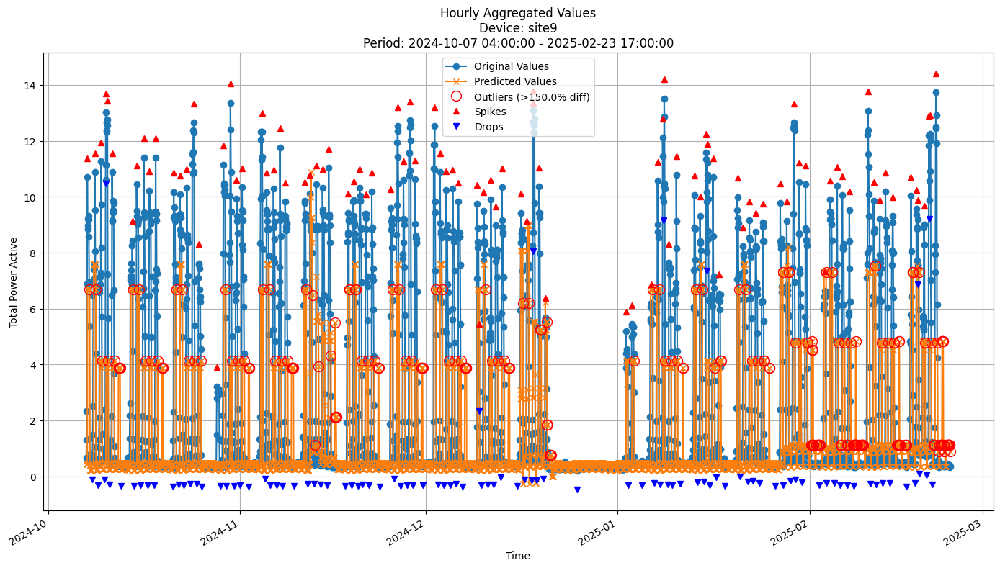


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.5501
MAE: 1.3848
MAPE: 75.1425%

Directional Metrics:
Directional Accuracy: 10.2388%
First-Diff Correlation: 0.0820

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0403
  Recall: 0.0505
  F1 Score: 0.0448
Drops:
  Precision: 0.0833
  Recall: 0.0918
  F1 Score: 0.0874

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1532
  Recall: 0.1919
  F1 Score: 0.1704
Drops:
  Precision: 0.2593
  Recall: 0.2857
  F1 Score: 0.2718


In [ ]:
join_periods = [-5, -4, -3, -2, -1]
# Device iteration
for device_id in incb_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

# Test-set Model Evaluation
(`train[-1]` + `valid[-1]`) vs `test`

In [ ]:
# Define model classes and params for test-set evaluation
models_classes = [bl_prev, bl_mean, gbdt, rf, hoef, arf_hf, fodt, arf, incb]
models_params = [
    bl_prev_params,
    bl_mean_params,
    gbdt_params,
    rf_params,
    hoef_params,
    arf_hf_params,
    fodt_params,
    arf_params,
    incb_params,
 ]

model_test_results = {}
for model_class, params in zip(models_classes, models_params):
    if model_class in [gbdt, rf, bl_mean]:
        incremental = False
        update_freq = "14D"
        print(f"Model: {model_class.__name__} - update_freq: {update_freq}")
    else:
        incremental = True
        update_freq = "1h"
        print(f"Model: {model_class.__name__} - update_freq: {update_freq}")

    _, test_preds, \
    _, test_metrics = test_set_seq_fit_predict(
        model_class=model_class,
        model_params=params,
        train=train,
        valid=valid,
        test=test,
        incremental=incremental,
        data_freq=DATA_FREQUENCY,
        forecast_horizon=FORECAST_HORIZON,
        features=FEATURES,
        update_freq=update_freq,
        spike_prominence=SPIKE_PROMINENCE,
        normalize_robust=True,
        predict_train=False,
        verbose=True
    )
    model_test_results[model_class.__name__] = {
        "test_preds": test_preds,
        "test_metrics": test_metrics
    }




Model: PreviousValueRegressor - update_freq: 1h


Processing devices for test predictions:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 12:00:00+02:00 to 2025-02-23 17:00:00+01:00
Model's memory usage: 0.000214 MB
Metrics for Device: site5 | Period: 2025-02-23 19:00:00+01:00 - 2025-04-24 21:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.1956
	MAE: 0.7621
	MAPE: 5.8800%

Directional Metrics:
	Directional Accuracy: 58.8480%
	First-Diff Correlation: 0.4214

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dail

Processing devices for test predictions:   0%|          | 0/7 [00:00<?, ?it/s]


Retraining model on data from 2024-06-29 12:00:00+02:00 to 2025-02-23 17:00:00+01:00

Time: 1.98 seconds
Predicting for chunk from 2025-02-23 19:00:00+01:00 to 2025-03-09 19:00:00+01:00

-------------------------

Retraining model on data from 2024-06-29 12:00:00+02:00 to 2025-03-09 19:00:00+01:00

Time: 2.10 seconds
Predicting for chunk from 2025-03-09 20:00:00+01:00 to 2025-03-23 20:00:00+01:00

-------------------------

Retraining model on data from 2024-06-29 12:00:00+02:00 to 2025-03-23 20:00:00+01:00

Time: 2.25 seconds
Predicting for chunk from 2025-03-23 21:00:00+01:00 to 2025-04-06 22:00:00+02:00

-------------------------

Retraining model on data from 2024-06-29 12:00:00+02:00 to 2025-04-06 22:00:00+02:00

Time: 2.35 seconds
Predicting for chunk from 2025-04-06 23:00:00+02:00 to 2025-04-20 23:00:00+02:00

-------------------------

Retraining model on data from 2024-06-29 12:00:00+02:00 to 2025-04-20 23:00:00+02:00

Time: 2.46 seconds
Predicting for chunk from 2025-04-21 0

Processing devices for test predictions:   0%|          | 0/7 [00:00<?, ?it/s]

... (7 outputs left out)

Processing devices for test predictions:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 12:00:00+02:00 to 2025-02-23 17:00:00+01:00
Model's memory usage: 339.884216 MB
Metrics for Device: site5 | Period: 2025-02-23 19:00:00+01:00 - 2025-04-24 21:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.4576
	MAE: 1.0380
	MAPE: 8.5307%

Directional Metrics:
	Directional Accuracy: 62.1790%
	First-Diff Correlation: 0.4559

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1429
		Recall: 0.1282
		F1: 0.1351
	Drops:
		Precision: 0.1176
		Recall: 0.1053
		F1: 0.1111

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8000
		Recall: 0.7179
		F1: 0.7568
	Drops:
		Precision: 0.3529
		Recall: 0.3158
		F1: 0.3333
--------------------------------------------------
Da

Processing devices for test predictions:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 12:00:00+02:00 to 2025-02-23 17:00:00+01:00
Model's memory usage: 0.645729 MB
Metrics for Device: site5 | Period: 2025-02-23 19:00:00+01:00 - 2025-04-24 21:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 5.2405
	MAE: 3.9223
	MAPE: 28.6487%

Directional Metrics:
	Directional Accuracy: 10.8952%
	First-Diff Correlation: 0.0601

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0471
		Recall: 0.1026
		F1: 0.0645
	Drops:
		Precision: 0.0120
		Recall: 0.0263
		F1: 0.0165

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.1882
		Recall: 0.4103
		F1: 0.2581
	Drops:
		Precision: 0.0843
		Recall: 0.1842
		F1: 0.1157
--------------------------------------------------
Dai

In [ ]:
for model in models_classes:
    model_test_results[model.__name__]['test_metrics'] = all_time_aggregation_metrics(
        model_test_results[model.__name__]['test_metrics'],
        data_freq=DATA_FREQUENCY,
        verbose=False)

# Model Comparison

In [ ]:
AGG_LEVEL = "hourly"
METRICS = ["rmse", "mae", "mape", "dir_accuracy", "first_diff_corr"]
PERC_METRICS = ["mape", "dir_accuracy", "first_diff_corr"]
# SPIKES_METRICS = ["spikes_immediate.precision", "spikes_immediate.recall", "spikes_immediate.f1",
#                   "spikes_delayed.precision", "spikes_delayed.recall", "spikes_delayed.f1",
#                   "drops_immediate.precision", "drops_immediate.recall", "drops_immediate.f1",
#                   "drops_delayed.precision", "drops_delayed.recall", "drops_delayed.f1"]
SPIKES_METRICS = ["spikes_immediate.f1", "spikes_delayed.f1",
                  "drops_immediate.f1", "drops_delayed.f1"]

METRICS.extend(SPIKES_METRICS)
PERC_METRICS.extend(SPIKES_METRICS)

## Test results

In [ ]:
MODEL_TEST_METRICS = {
    "BL_Prev": model_test_results[bl_prev.__name__]["test_metrics"],
    "BL_Mean": model_test_results[bl_mean.__name__]["test_metrics"],
    "GBDT": model_test_results[gbdt.__name__]["test_metrics"],
    "RandomForest": model_test_results[rf.__name__]["test_metrics"],
    "HoeffdingTree": model_test_results[hoef.__name__]["test_metrics"],
    "ARF_Hoeffding": model_test_results[arf_hf.__name__]["test_metrics"],
    "FastODT": model_test_results[fodt.__name__]["test_metrics"],
    "ARF_FastODT": model_test_results[arf.__name__]["test_metrics"],
    "IncubationBoost": model_test_results[incb.__name__]["test_metrics"],
}

In [ ]:
def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f} ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

def display_aggregated_results(model_metrics, device_ids, agg_level):
    for device_id in device_ids:
        rows = []
        for model, mdict in model_metrics.items():
            if device_id in mdict and agg_level in mdict[device_id]:
                vals = mdict[device_id][agg_level]
                row = [model]
                for m in METRICS:
                    is_perc = (m in PERC_METRICS)
                    row.append(format_metric(vals.get(m, None), is_perc=is_perc))
                rows.append(row)
        df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)",
                                         "Spikes Immediate F1 (%)", "Spikes Delayed F1 (%)", "Drops Immediate F1 (%)", "Drops Delayed F1 (%)"])
        print(f"\n\nDevice: {device_id} | Aggregation: {agg_level}")
        display(df)

In [ ]:
device_ids = set()
for m in MODEL_TEST_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

print("\n\n============================Hourly Test Results============================")
display_aggregated_results(MODEL_TEST_METRICS, device_ids, AGG_LEVEL)



============================Hourly Test Results============================


Device: site1 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,0.091 ± 0.000,0.064 ± 0.000,13.586 ± 0.000,49.600 ± 0.000,-4.671 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,100.000 ± 0.000
1,GBDT,0.078 ± 0.000,0.058 ± 0.000,12.213 ± 0.000,63.478 ± 0.000,47.615 ± 0.000,19.048 ± 0.000,31.746 ± 0.000,12.903 ± 0.000,41.935 ± 0.000
2,RandomForest,0.083 ± 0.000,0.061 ± 0.000,12.919 ± 0.000,61.708 ± 0.000,40.104 ± 0.000,16.667 ± 0.000,36.667 ± 0.000,13.559 ± 0.000,40.678 ± 0.000
3,HoeffdingTree,0.118 ± 0.000,0.088 ± 0.000,18.172 ± 0.000,54.112 ± 0.000,28.034 ± 0.000,4.819 ± 0.000,36.145 ± 0.000,2.439 ± 0.000,36.585 ± 0.000
4,ARF_Hoeffding,0.109 ± 0.000,0.079 ± 0.000,16.163 ± 0.000,59.423 ± 0.000,25.762 ± 0.000,19.231 ± 0.000,38.462 ± 0.000,11.765 ± 0.000,19.608 ± 0.000
5,FastODT,0.127 ± 0.000,0.092 ± 0.000,18.492 ± 0.000,51.428 ± 0.000,27.209 ± 0.000,11.594 ± 0.000,28.986 ± 0.000,5.882 ± 0.000,23.529 ± 0.000
6,ARF_FastODT,0.090 ± 0.000,0.066 ± 0.000,14.129 ± 0.000,59.709 ± 0.000,28.762 ± 0.000,12.245 ± 0.000,32.653 ± 0.000,4.167 ± 0.000,29.167 ± 0.000
7,IncubationBoost,0.262 ± 0.000,0.213 ± 0.000,37.946 ± 0.000,22.616 ± 0.000,3.254 ± 0.000,21.687 ± 0.000,31.325 ± 0.000,0.000 ± 0.000,0.000 ± 0.000




Device: site2 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,1.458 ± 0.000,0.641 ± 0.000,27.145 ± 0.000,53.857 ± 0.000,32.903 ± 0.000,0.000 ± 0.000,99.200 ± 0.000,0.000 ± 0.000,100.000 ± 0.000
1,GBDT,0.805 ± 0.000,0.401 ± 0.000,18.126 ± 0.000,61.293 ± 0.000,78.678 ± 0.000,8.197 ± 0.000,24.590 ± 0.000,4.959 ± 0.000,14.876 ± 0.000
2,RandomForest,0.824 ± 0.000,0.409 ± 0.000,19.374 ± 0.000,60.042 ± 0.000,78.075 ± 0.000,6.452 ± 0.000,22.581 ± 0.000,3.252 ± 0.000,14.634 ± 0.000
3,HoeffdingTree,1.000 ± 0.000,0.464 ± 0.000,24.574 ± 0.000,57.054 ± 0.000,68.848 ± 0.000,12.403 ± 0.000,40.310 ± 0.000,9.375 ± 0.000,20.312 ± 0.000
4,ARF_Hoeffding,1.070 ± 0.000,0.603 ± 0.000,50.292 ± 0.000,59.486 ± 0.000,77.317 ± 0.000,16.981 ± 0.000,28.302 ± 0.000,9.524 ± 0.000,17.143 ± 0.000
5,FastODT,1.503 ± 0.000,0.766 ± 0.000,42.721 ± 0.000,44.684 ± 0.000,36.360 ± 0.000,10.000 ± 0.000,33.750 ± 0.000,8.861 ± 0.000,34.177 ± 0.000
6,ARF_FastODT,0.946 ± 0.000,0.501 ± 0.000,27.156 ± 0.000,57.054 ± 0.000,73.120 ± 0.000,3.636 ± 0.000,16.364 ± 0.000,1.835 ± 0.000,7.339 ± 0.000
7,IncubationBoost,2.670 ± 0.000,1.645 ± 0.000,126.431 ± 0.000,14.246 ± 0.000,6.331 ± 0.000,7.692 ± 0.000,29.231 ± 0.000,1.626 ± 0.000,11.382 ± 0.000




Device: site3 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,8.845 ± 0.000,5.426 ± 0.000,53.730 ± 0.000,44.232 ± 0.000,-6.889 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,100.000 ± 0.000
1,GBDT,5.989 ± 0.000,3.851 ± 0.000,46.131 ± 0.000,59.652 ± 0.000,62.827 ± 0.000,2.151 ± 0.000,12.903 ± 0.000,9.346 ± 0.000,18.692 ± 0.000
2,RandomForest,5.989 ± 0.000,3.845 ± 0.000,45.609 ± 0.000,60.394 ± 0.000,63.589 ± 0.000,4.255 ± 0.000,17.021 ± 0.000,3.704 ± 0.000,9.259 ± 0.000
3,HoeffdingTree,7.465 ± 0.000,4.904 ± 0.000,69.478 ± 0.000,52.627 ± 0.000,42.244 ± 0.000,0.000 ± 0.000,2.299 ± 0.000,3.960 ± 0.000,7.921 ± 0.000
4,ARF_Hoeffding,28.460 ± 0.000,5.562 ± 0.000,91.613 ± 0.000,56.453 ± 0.000,3.855 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
5,FastODT,7.319 ± 0.000,4.647 ± 0.000,59.581 ± 0.000,53.055 ± 0.000,48.609 ± 0.000,0.000 ± 0.000,9.615 ± 0.000,6.780 ± 0.000,20.339 ± 0.000
6,ARF_FastODT,6.814 ± 0.000,4.709 ± 0.000,64.538 ± 0.000,58.053 ± 0.000,44.896 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
7,IncubationBoost,12.360 ± 0.000,9.224 ± 0.000,188.095 ± 0.000,19.589 ± 0.000,16.593 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000


... (4 outputs left out)



Device: site8 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,5.878 ± 0.000,2.907 ± 0.000,35.259 ± 0.000,46.565 ± 0.000,30.963 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,100.000 ± 0.000
1,GBDT,3.717 ± 0.000,1.976 ± 0.000,26.151 ± 0.000,57.946 ± 0.000,71.284 ± 0.000,12.500 ± 0.000,28.571 ± 0.000,9.091 ± 0.000,21.818 ± 0.000
2,RandomForest,3.608 ± 0.000,1.943 ± 0.000,25.943 ± 0.000,60.167 ± 0.000,73.903 ± 0.000,14.815 ± 0.000,29.630 ± 0.000,5.660 ± 0.000,13.208 ± 0.000
3,HoeffdingTree,5.205 ± 0.000,2.649 ± 0.000,37.682 ± 0.000,52.672 ± 0.000,51.831 ± 0.000,6.557 ± 0.000,31.148 ± 0.000,10.000 ± 0.000,23.333 ± 0.000
4,ARF_Hoeffding,4.938 ± 0.000,2.720 ± 0.000,38.136 ± 0.000,58.501 ± 0.000,54.367 ± 0.000,0.000 ± 0.000,8.791 ± 0.000,6.742 ± 0.000,24.719 ± 0.000
5,FastODT,5.071 ± 0.000,2.640 ± 0.000,36.978 ± 0.000,49.827 ± 0.000,56.174 ± 0.000,10.370 ± 0.000,40.000 ± 0.000,10.219 ± 0.000,20.438 ± 0.000
6,ARF_FastODT,4.368 ± 0.000,2.442 ± 0.000,33.858 ± 0.000,56.836 ± 0.000,63.097 ± 0.000,3.960 ± 0.000,17.822 ± 0.000,10.101 ± 0.000,26.263 ± 0.000
7,IncubationBoost,8.775 ± 0.000,5.229 ± 0.000,77.387 ± 0.000,18.668 ± 0.000,13.664 ± 0.000,9.615 ± 0.000,44.231 ± 0.000,5.882 ± 0.000,11.765 ± 0.000




Device: site9 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,1.467 ± 0.000,0.648 ± 0.000,27.563 ± 0.000,53.990 ± 0.000,33.128 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,100.000 ± 0.000
1,GBDT,0.824 ± 0.000,0.410 ± 0.000,18.413 ± 0.000,62.110 ± 0.000,78.464 ± 0.000,11.200 ± 0.000,24.000 ± 0.000,4.878 ± 0.000,14.634 ± 0.000
2,RandomForest,0.822 ± 0.000,0.407 ± 0.000,19.364 ± 0.000,59.958 ± 0.000,78.355 ± 0.000,4.959 ± 0.000,23.140 ± 0.000,1.681 ± 0.000,10.084 ± 0.000
3,HoeffdingTree,1.000 ± 0.000,0.466 ± 0.000,24.662 ± 0.000,57.391 ± 0.000,69.207 ± 0.000,10.938 ± 0.000,40.625 ± 0.000,9.524 ± 0.000,20.635 ± 0.000
4,ARF_Hoeffding,1.084 ± 0.000,0.610 ± 0.000,50.898 ± 0.000,59.264 ± 0.000,77.531 ± 0.000,13.208 ± 0.000,28.302 ± 0.000,9.615 ± 0.000,19.231 ± 0.000
5,FastODT,1.508 ± 0.000,0.772 ± 0.000,42.847 ± 0.000,44.761 ± 0.000,36.479 ± 0.000,10.000 ± 0.000,35.000 ± 0.000,8.861 ± 0.000,35.443 ± 0.000
6,ARF_FastODT,0.909 ± 0.000,0.493 ± 0.000,27.003 ± 0.000,58.779 ± 0.000,76.149 ± 0.000,7.207 ± 0.000,19.820 ± 0.000,1.835 ± 0.000,11.009 ± 0.000
7,IncubationBoost,2.692 ± 0.000,1.661 ± 0.000,125.938 ± 0.000,14.365 ± 0.000,6.257 ± 0.000,7.752 ± 0.000,29.457 ± 0.000,1.653 ± 0.000,11.570 ± 0.000


## Validation results

In [ ]:
MODEL_VALID_METRICS = {
    "BL_Prev": bl_prev_all_time_valid_metrics,
    "BL_Mean": bl_mean_all_time_valid_metrics,
    "GBDT": gbdt_all_time_valid_metrics,
    "RandomForest": rf_all_time_valid_metrics,
    "HoeffdingTree": hoef_all_time_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_time_valid_metrics,
    "FastODT": fodt_all_time_valid_metrics,
    "ARF_FastODT": arf_all_time_valid_metrics,
    "IncubationBoost": incb_all_time_valid_metrics,
}


device_ids = set()
for m in MODEL_VALID_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)


print("\n\n============================Hourly Validation Results============================")
display_aggregated_results(MODEL_VALID_METRICS, device_ids, AGG_LEVEL)



============================Hourly Validation Results============================


Device: site1 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,0.072 ± 0.009,0.047 ± 0.007,17.668 ± 2.250,44.671 ± 3.509,-9.708 ± 9.598,0.000 ± 0.000,98.931 ± 2.624,0.000 ± 0.000,99.740 ± 0.665
1,GBDT,0.070 ± 0.025,0.046 ± 0.020,17.167 ± 6.370,60.582 ± 2.073,45.654 ± 10.528,22.389 ± 12.910,40.891 ± 13.638,12.424 ± 7.290,27.503 ± 8.689
2,RandomForest,0.072 ± 0.027,0.048 ± 0.021,18.045 ± 6.305,58.421 ± 2.225,40.766 ± 10.635,19.165 ± 11.720,35.520 ± 14.353,7.799 ± 5.866,23.912 ± 7.092
3,HoeffdingTree,0.096 ± 0.045,0.065 ± 0.035,23.410 ± 6.159,54.939 ± 2.859,31.728 ± 12.187,11.820 ± 11.038,31.099 ± 12.203,8.246 ± 5.029,23.495 ± 6.376
4,FastODT,0.089 ± 0.041,0.060 ± 0.032,21.749 ± 7.178,51.732 ± 1.996,27.253 ± 10.270,11.118 ± 6.835,32.677 ± 9.831,7.993 ± 5.737,19.473 ± 10.125
5,ARF_FastODT,0.070 ± 0.017,0.050 ± 0.014,20.630 ± 6.626,58.594 ± 2.891,31.411 ± 9.404,16.301 ± 9.938,34.153 ± 11.710,8.888 ± 7.645,25.127 ± 17.885
6,IncubationBoost,0.143 ± 0.086,0.107 ± 0.075,35.149 ± 8.258,13.828 ± 4.664,0.819 ± 5.139,8.829 ± 7.122,27.944 ± 7.293,1.838 ± 2.937,7.533 ± 4.830




Device: site2 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,1.403 ± 0.140,0.604 ± 0.095,26.846 ± 3.425,48.975 ± 5.632,29.302 ± 3.311,0.000 ± 0.000,99.513 ± 1.289,0.000 ± 0.000,99.500 ± 1.323
1,GBDT,1.088 ± 0.323,0.518 ± 0.140,25.504 ± 10.575,61.816 ± 3.254,68.499 ± 13.547,12.204 ± 5.687,34.250 ± 9.446,6.817 ± 4.457,20.417 ± 8.944
2,RandomForest,1.001 ± 0.201,0.486 ± 0.093,25.850 ± 12.776,62.949 ± 3.577,71.860 ± 11.535,10.569 ± 6.168,30.100 ± 12.075,6.291 ± 3.491,20.838 ± 7.852
3,HoeffdingTree,1.440 ± 0.331,0.702 ± 0.186,42.993 ± 23.158,52.285 ± 5.179,40.403 ± 14.615,7.597 ± 5.459,29.761 ± 8.716,6.136 ± 5.642,21.707 ± 6.912
4,FastODT,1.628 ± 0.282,0.815 ± 0.153,45.474 ± 14.119,46.516 ± 3.290,31.036 ± 7.511,7.961 ± 5.003,31.562 ± 5.011,7.401 ± 3.609,26.887 ± 5.022
5,ARF_FastODT,1.011 ± 0.132,0.533 ± 0.064,34.597 ± 9.797,60.955 ± 5.203,65.078 ± 13.142,7.661 ± 2.718,24.828 ± 9.349,7.245 ± 4.414,19.160 ± 6.711
6,IncubationBoost,2.727 ± 0.388,1.498 ± 0.292,79.381 ± 15.752,12.537 ± 6.015,8.221 ± 4.535,6.343 ± 3.574,20.388 ± 5.194,8.523 ± 7.031,21.170 ± 8.956




Device: site3 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,9.039 ± 0.794,5.779 ± 0.712,68.480 ± 10.968,42.504 ± 3.538,-11.459 ± 5.142,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,100.000 ± 0.000
1,GBDT,6.708 ± 0.506,4.434 ± 0.453,78.624 ± 36.306,58.443 ± 2.819,55.197 ± 6.471,2.688 ± 5.767,5.888 ± 11.173,1.527 ± 3.413,4.989 ± 10.601
2,RandomForest,6.653 ± 0.459,4.391 ± 0.431,77.675 ± 36.845,58.522 ± 3.029,55.716 ± 6.926,1.882 ± 4.714,5.128 ± 11.354,2.570 ± 5.669,4.899 ± 10.909
3,HoeffdingTree,8.213 ± 0.600,5.568 ± 0.542,124.069 ± 46.175,50.158 ± 3.524,30.914 ± 5.621,3.372 ± 6.488,8.893 ± 13.164,3.240 ± 5.819,8.639 ± 11.521
4,FastODT,8.011 ± 0.601,5.244 ± 0.600,96.538 ± 39.491,48.968 ± 2.385,38.038 ± 7.629,4.166 ± 6.005,14.872 ± 15.802,3.265 ± 5.050,13.288 ± 13.401
5,ARF_FastODT,6.932 ± 0.494,4.802 ± 0.432,92.650 ± 19.774,56.433 ± 2.732,43.045 ± 8.560,4.467 ± 8.125,6.638 ± 10.772,1.285 ± 3.398,3.423 ± 8.496
6,IncubationBoost,11.656 ± 0.902,8.934 ± 0.664,297.914 ± 62.567,25.457 ± 5.350,15.610 ± 4.635,0.000 ± 0.000,0.145 ± 0.632,2.154 ± 5.422,4.715 ± 11.464


... (4 outputs left out)



Device: site8 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,5.619 ± 0.556,2.688 ± 0.328,32.534 ± 2.452,46.592 ± 3.266,26.976 ± 3.766,0.000 ± 0.000,99.479 ± 1.378,0.000 ± 0.000,99.457 ± 1.438
1,GBDT,4.348 ± 1.129,2.287 ± 0.530,25.826 ± 6.514,58.760 ± 3.554,65.687 ± 12.351,9.839 ± 2.885,31.473 ± 9.375,10.674 ± 6.286,19.284 ± 6.151
2,RandomForest,4.128 ± 0.778,2.175 ± 0.373,25.496 ± 6.100,59.434 ± 3.042,68.890 ± 10.162,9.335 ± 7.244,26.919 ± 7.684,10.399 ± 7.858,21.483 ± 9.925
3,HoeffdingTree,5.504 ± 0.904,2.866 ± 0.517,33.356 ± 7.965,51.744 ± 4.139,48.825 ± 6.313,7.383 ± 3.756,27.538 ± 9.929,6.854 ± 2.951,27.833 ± 8.017
4,FastODT,5.622 ± 1.530,2.892 ± 0.685,36.705 ± 18.744,47.177 ± 3.456,56.872 ± 12.087,12.506 ± 3.694,35.180 ± 9.079,5.428 ± 2.849,19.558 ± 5.407
5,ARF_FastODT,4.340 ± 0.575,2.406 ± 0.314,33.283 ± 9.586,58.573 ± 3.953,61.938 ± 11.680,6.411 ± 5.029,21.130 ± 8.146,6.710 ± 7.565,20.164 ± 13.780
6,IncubationBoost,8.783 ± 1.303,5.012 ± 0.806,67.562 ± 12.101,16.834 ± 3.778,9.717 ± 2.425,10.850 ± 9.068,34.159 ± 9.297,4.563 ± 3.309,9.209 ± 7.139




Device: site9 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,1.401 ± 0.140,0.603 ± 0.095,26.821 ± 3.431,48.952 ± 5.617,29.302 ± 3.311,0.000 ± 0.000,99.513 ± 1.289,0.000 ± 0.000,99.500 ± 1.323
1,GBDT,1.087 ± 0.323,0.518 ± 0.140,25.491 ± 10.583,61.800 ± 3.261,68.499 ± 13.547,12.117 ± 5.663,34.009 ± 9.356,6.793 ± 4.474,20.323 ± 9.009
2,RandomForest,1.000 ± 0.201,0.485 ± 0.093,25.838 ± 12.782,62.935 ± 3.591,71.863 ± 11.536,10.483 ± 6.173,30.251 ± 12.101,6.291 ± 3.491,21.170 ± 7.473
3,HoeffdingTree,1.439 ± 0.332,0.702 ± 0.187,42.972 ± 23.174,52.237 ± 5.139,40.403 ± 14.615,7.870 ± 5.736,30.307 ± 8.511,6.136 ± 5.642,21.986 ± 6.581
4,FastODT,1.626 ± 0.281,0.814 ± 0.151,45.421 ± 14.095,46.502 ± 3.288,31.036 ± 7.511,7.911 ± 5.026,31.970 ± 5.188,7.295 ± 3.478,26.972 ± 5.085
5,ARF_FastODT,0.994 ± 0.113,0.524 ± 0.052,34.792 ± 9.164,61.651 ± 5.076,67.819 ± 11.929,7.758 ± 2.031,22.878 ± 9.371,5.717 ± 4.646,13.573 ± 5.255
6,IncubationBoost,2.725 ± 0.388,1.497 ± 0.292,79.514 ± 15.999,12.519 ± 6.018,8.220 ± 4.535,6.296 ± 3.564,20.247 ± 5.169,8.497 ± 7.048,21.092 ± 9.043


### By-period validation results

In [ ]:
MODEL_VALID_PERIOD_METRICS = {
    "BL_Prev": bl_prev_valid_period_metrics,
    "BL_Mean": bl_mean_valid_period_metrics,
    "GBDT": gbdt_valid_period_metrics,
    "RandomForest": rf_valid_period_metrics,
    "HoeffdingTree": hoef_all_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_valid_metrics,
    "FastODT": fodt_all_valid_metrics,
    "ARF_FastODT": arf_all_valid_metrics,
    "IncubationBoost": incb_all_valid_metrics,
}

def show_per_period_metric_tables(device_ids, MODEL_VALID_PERIOD_METRICS, AGG_LEVEL, metric_name, display_gain=True):
    """
    Display per-period metric tables and gain/drop tables for a given metric.
    Args:
        device_ids: List of device IDs to display metrics for.
        MODEL_VALID_PERIOD_METRICS: Dictionary containing model period metrics.
        AGG_LEVEL: Aggregation level (e.g., "hourly").
        metric_name: The name of the metric to display.
        display_gain: Whether to display gain/drop tables.
    """
    for device_id in device_ids:
        period_vals = {}
        n_periods = None
        for model, mdict in MODEL_VALID_PERIOD_METRICS.items():
                if metric_name in PERC_METRICS:
                    vals = [period[AGG_LEVEL][metric_name]*100 for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                else:
                    vals = [period[AGG_LEVEL][metric_name] for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                n_periods = len(vals)
        if not period_vals:
            continue

        df_metric = pd.DataFrame(period_vals)
        df_metric.index = [f"Period {i+1}" for i in range(n_periods)]
        df_metric['Agg. Per Period'] = df_metric.astype(float).mean(axis=1)

        metric_label = f"{metric_name.upper()} (%)" if metric_name in PERC_METRICS else metric_name.upper()
        print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL} | {metric_label} per period")
        display(df_metric)


        if display_gain:
            # Absolute gain/drop
            abs_gain = df_metric.astype(float).diff().iloc[1:]
            abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")
            abs_gain.index = [f"{df_metric.index[i]} - {df_metric.index[i-1]}" for i in range(1, len(df_metric))]
            print(f"\nAbsolute gain/drop in {metric_label}:")
            display(abs_gain)
            # Percentage gain/drop
            # pct_gain = df_metric.astype(float).pct_change().iloc[1:] * 100
            # pct_gain = pct_gain.applymap(lambda v: f"{v:.3f}")
            # pct_gain.index = abs_gain.index
            # print(f"\nPercentage gain/drop in {metric_label} (lower is better):")
            # display(pct_gain)

#### Directional accuracy (higher is better)

In [ ]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="dir_accuracy",
    display_gain=True
)


Device: site1 | Aggregation: hourly | DIR_ACCURACY (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,49.776,63.487,57.973,53.204,63.040,51.118,62.146,9.538,51.285250
Period 2,41.729,60.358,56.185,52.459,60.507,48.286,60.656,8.644,48.603000
Period 3,42.474,62.593,61.252,59.463,62.891,52.310,60.805,9.389,51.397125
Period 4,44.262,62.444,59.463,56.185,59.165,53.353,63.040,8.495,50.800875
Period 5,44.560,63.338,61.699,57.973,61.252,52.459,62.593,8.197,51.508875
Period 6,41.580,57.824,57.675,62.444,60.209,49.776,59.613,9.687,49.851000
Period 7,43.964,60.656,58.867,55.887,56.483,51.565,61.401,10.581,49.925500
Period 8,40.984,61.401,58.420,55.589,60.209,52.757,54.247,12.370,49.497125
Period 9,46.796,60.060,58.271,54.844,57.526,49.776,54.694,22.653,50.577500
Period 10,46.796,58.122,55.440,52.012,55.291,46.796,55.291,22.951,49.087375



Absolute gain/drop in DIR_ACCURACY (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-8.047,-3.129,-1.788,-0.745,-2.533,-2.832,-1.490,-0.894,-2.682
Period 3 - Period 2,0.745,2.235,5.067,7.004,2.384,4.024,0.149,0.745,2.794
Period 4 - Period 3,1.788,-0.149,-1.789,-3.278,-3.726,1.043,2.235,-0.894,-0.596
Period 5 - Period 4,0.298,0.894,2.236,1.788,2.087,-0.894,-0.447,-0.298,0.708
Period 6 - Period 5,-2.980,-5.514,-4.024,4.471,-1.043,-2.683,-2.980,1.490,-1.658
Period 7 - Period 6,2.384,2.832,1.192,-6.557,-3.726,1.789,1.788,0.894,0.074
Period 8 - Period 7,-2.980,0.745,-0.447,-0.298,3.726,1.192,-7.154,1.789,-0.428
Period 9 - Period 8,5.812,-1.341,-0.149,-0.745,-2.683,-2.981,0.447,10.283,1.080
Period 10 - Period 9,0.000,-1.938,-2.831,-2.832,-2.235,-2.980,0.597,0.298,-1.490
Period 11 - Period 10,7.600,3.875,4.023,-1.937,4.620,4.173,4.471,-3.130,2.962



Device: site2 | Aggregation: hourly | DIR_ACCURACY (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,50.075,55.887,59.016,40.984,54.993,42.623,51.565,28.167,47.913750
Period 2,57.079,62.444,63.785,59.911,66.766,46.349,62.444,10.879,53.707125
Period 3,49.329,64.978,67.660,49.776,66.021,42.325,67.064,9.836,52.123625
Period 4,51.416,67.362,68.852,52.906,62.295,47.988,65.574,9.091,53.185500
Period 5,40.835,62.146,64.382,53.353,62.146,52.310,66.021,10.879,51.509000
Period 6,39.195,61.997,60.060,51.565,53.651,49.776,60.954,11.624,48.602750
Period 7,51.118,59.314,60.358,53.055,58.271,43.815,54.694,8.197,48.602750
Period 8,52.752,60.398,59.480,56.728,61.162,46.942,59.327,11.621,51.051250


... (18 outputs left out)


Device: site9 | Aggregation: hourly | DIR_ACCURACY (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,50.075,55.887,59.016,40.984,54.993,42.623,52.310,28.167,48.006875
Period 2,57.079,62.444,63.785,59.911,66.766,46.349,63.338,10.879,53.818875
Period 3,49.329,64.978,67.660,49.776,66.021,42.325,67.809,9.836,52.216750
Period 4,51.416,67.362,68.852,52.906,62.295,47.988,67.511,9.091,53.427625
Period 5,40.835,62.146,64.382,53.353,62.146,52.310,65.723,10.879,51.471750
Period 6,39.195,61.997,60.060,51.565,53.651,49.776,58.569,11.624,48.304625
Period 7,51.118,59.314,60.358,53.055,58.271,43.815,57.675,8.197,48.975375
Period 8,52.568,60.272,59.366,56.344,61.027,46.828,60.272,11.480,51.019625



Absolute gain/drop in DIR_ACCURACY (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,7.004,6.557,4.769,18.927,11.773,3.726,11.028,-17.288,5.812
Period 3 - Period 2,-7.750,2.534,3.875,-10.135,-0.745,-4.024,4.471,-1.043,-1.602
Period 4 - Period 3,2.087,2.384,1.192,3.130,-3.726,5.663,-0.298,-0.745,1.211
Period 5 - Period 4,-10.581,-5.216,-4.470,0.447,-0.149,4.322,-1.788,1.788,-1.956
Period 6 - Period 5,-1.640,-0.149,-4.322,-1.788,-8.495,-2.534,-7.154,0.745,-3.167
Period 7 - Period 6,11.923,-2.683,0.298,1.490,4.620,-5.961,-0.894,-3.427,0.671
Period 8 - Period 7,1.450,0.958,-0.992,3.289,2.756,3.013,2.597,3.283,2.044


#### MAPE (lower is better)

In [ ]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="mape",
    display_gain=True
)


Device: site1 | Aggregation: hourly | MAPE (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,19.048,22.962,24.877,29.501,28.612,27.038,20.916,36.903,26.232125
Period 2,18.136,16.157,18.406,22.488,23.112,18.839,18.222,30.573,20.741625
Period 3,19.114,13.213,15.471,19.861,21.178,17.060,18.512,29.059,19.183500
Period 4,18.635,13.321,14.030,17.080,17.917,17.541,17.156,29.994,18.209250
Period 5,17.999,11.935,12.559,16.734,15.556,14.854,15.436,27.063,16.517000
Period 6,17.382,17.124,17.113,18.397,16.924,18.158,16.573,26.600,18.533875
Period 7,17.974,13.517,13.977,18.437,14.901,15.414,15.366,26.790,17.047000
Period 8,17.110,13.257,13.530,17.351,16.412,15.245,15.794,25.895,16.824250
Period 9,13.348,17.826,18.196,22.436,20.855,19.974,14.678,38.179,20.686500
Period 10,18.069,42.628,42.950,45.496,53.351,48.601,43.876,59.934,44.363125



Absolute gain/drop in MAPE (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.912,-6.805,-6.471,-7.013,-5.500,-8.199,-2.694,-6.330,-5.491
Period 3 - Period 2,0.978,-2.944,-2.935,-2.627,-1.934,-1.779,0.290,-1.514,-1.558
Period 4 - Period 3,-0.479,0.108,-1.441,-2.781,-3.261,0.481,-1.356,0.935,-0.974
Period 5 - Period 4,-0.636,-1.386,-1.471,-0.346,-2.361,-2.687,-1.720,-2.931,-1.692
Period 6 - Period 5,-0.617,5.189,4.554,1.663,1.368,3.304,1.137,-0.463,2.017
Period 7 - Period 6,0.592,-3.607,-3.136,0.040,-2.023,-2.744,-1.207,0.190,-1.487
Period 8 - Period 7,-0.864,-0.260,-0.447,-1.086,1.511,-0.169,0.428,-0.895,-0.223
Period 9 - Period 8,-3.762,4.569,4.666,5.085,4.443,4.729,-1.116,12.284,3.862
Period 10 - Period 9,4.721,24.802,24.754,23.060,32.496,28.627,29.198,21.755,23.677
Period 11 - Period 10,-8.320,-27.681,-27.479,-20.702,-28.928,-23.971,-31.086,-14.114,-22.785



Device: site2 | Aggregation: hourly | MAPE (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,22.607,48.442,56.594,99.563,108.091,72.570,58.713,90.931,69.688875
Period 2,27.691,21.604,20.033,39.602,43.388,46.917,33.019,83.504,39.469750
Period 3,30.268,15.563,16.230,31.325,34.595,27.052,25.041,85.505,33.197375
Period 4,30.176,16.801,17.667,27.997,35.934,32.898,26.423,70.986,32.360250
Period 5,31.704,18.335,18.292,25.344,35.663,31.992,30.167,77.070,33.570875
Period 6,23.771,32.904,33.345,52.620,55.095,43.364,33.704,65.703,42.563250
Period 7,22.532,31.204,26.133,42.184,62.525,56.923,36.452,53.007,41.370000
Period 8,26.017,19.179,18.506,25.311,47.039,52.074,33.256,108.342,41.215500


... (18 outputs left out)


Device: site9 | Aggregation: hourly | MAPE (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,22.607,48.442,56.594,99.563,108.091,72.570,54.603,90.931,69.175125
Period 2,27.691,21.604,20.033,39.602,43.388,46.917,33.787,83.504,39.565750
Period 3,30.268,15.563,16.230,31.325,34.595,27.052,21.111,85.505,32.706125
Period 4,30.176,16.801,17.667,27.997,35.934,32.898,28.581,70.986,32.630000
Period 5,31.704,18.335,18.292,25.344,35.663,31.992,30.923,77.070,33.665375
Period 6,23.771,32.904,33.338,52.620,55.095,43.364,34.854,65.703,42.706125
Period 7,22.532,31.204,26.133,42.184,62.525,56.923,40.817,53.007,41.915625
Period 8,25.817,19.072,18.414,25.144,47.733,51.652,33.656,109.405,41.361625



Absolute gain/drop in MAPE (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,5.084,-26.838,-36.561,-59.961,-64.703,-25.653,-20.816,-7.427,-29.609
Period 3 - Period 2,2.577,-6.041,-3.803,-8.277,-8.793,-19.865,-12.676,2.001,-6.860
Period 4 - Period 3,-0.092,1.238,1.437,-3.328,1.339,5.846,7.470,-14.519,-0.076
Period 5 - Period 4,1.528,1.534,0.625,-2.653,-0.271,-0.906,2.342,6.084,1.035
Period 6 - Period 5,-7.933,14.569,15.046,27.276,19.432,11.372,3.931,-11.367,9.041
Period 7 - Period 6,-1.239,-1.700,-7.205,-10.436,7.430,13.559,5.963,-12.696,-0.791
Period 8 - Period 7,3.285,-12.132,-7.719,-17.040,-14.792,-5.271,-7.161,56.398,-0.554


#### RMSE (lower is better)

In [ ]:
# RMSE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="rmse",
    display_gain=True
)


Device: site1 | Aggregation: hourly | RMSE per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.078,0.074,0.078,0.103,0.089,0.102,0.074,0.207,0.100625
Period 2,0.060,0.045,0.048,0.064,0.052,0.059,0.046,0.078,0.056500
Period 3,0.065,0.040,0.044,0.062,0.051,0.052,0.047,0.073,0.054250
Period 4,0.067,0.054,0.054,0.064,0.057,0.065,0.056,0.086,0.062875
Period 5,0.062,0.048,0.047,0.061,0.049,0.055,0.050,0.076,0.056000
Period 6,0.060,0.056,0.055,0.062,0.054,0.062,0.055,0.081,0.060625
Period 7,0.070,0.054,0.055,0.062,0.056,0.062,0.058,0.089,0.063250
Period 8,0.073,0.058,0.058,0.071,0.069,0.068,0.063,0.105,0.070625
Period 9,0.077,0.106,0.105,0.132,0.127,0.107,0.084,0.231,0.121125
Period 10,0.082,0.099,0.101,0.144,0.121,0.131,0.095,0.270,0.130375



Absolute gain/drop in RMSE:


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.018,-0.029,-0.030,-0.039,-0.037,-0.043,-0.028,-0.129,-0.044
Period 3 - Period 2,0.005,-0.005,-0.004,-0.002,-0.001,-0.007,0.001,-0.005,-0.002
Period 4 - Period 3,0.002,0.014,0.010,0.002,0.006,0.013,0.009,0.013,0.009
Period 5 - Period 4,-0.005,-0.006,-0.007,-0.003,-0.008,-0.010,-0.006,-0.010,-0.007
Period 6 - Period 5,-0.002,0.008,0.008,0.001,0.005,0.007,0.005,0.005,0.005
Period 7 - Period 6,0.010,-0.002,0.000,0.000,0.002,0.000,0.003,0.008,0.003
Period 8 - Period 7,0.003,0.004,0.003,0.009,0.013,0.006,0.005,0.016,0.007
Period 9 - Period 8,0.004,0.048,0.047,0.061,0.058,0.039,0.021,0.126,0.050
Period 10 - Period 9,0.005,-0.007,-0.004,0.012,-0.006,0.024,0.011,0.039,0.009
Period 11 - Period 10,0.004,0.051,0.062,0.105,0.475,0.102,0.014,0.159,0.121



Device: site2 | Aggregation: hourly | RMSE per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,1.247,1.490,1.372,2.206,1.356,2.011,1.276,2.684,1.705250
Period 2,1.604,1.742,1.261,1.745,1.323,1.898,1.064,3.446,1.760375
Period 3,1.521,0.773,0.764,1.241,0.858,1.243,0.778,3.002,1.272500
Period 4,1.440,0.938,0.957,1.283,1.006,1.487,0.989,2.893,1.374125
Period 5,1.516,0.794,0.767,1.299,1.081,1.357,0.986,2.794,1.324250
Period 6,1.240,0.944,0.955,1.263,1.091,1.348,0.994,2.123,1.244750
Period 7,1.212,1.038,0.968,1.281,1.101,1.889,0.922,2.292,1.337875
Period 8,1.441,0.983,0.965,1.204,1.222,1.790,1.074,2.580,1.407375


... (18 outputs left out)


Device: site9 | Aggregation: hourly | RMSE per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,1.247,1.490,1.372,2.206,1.356,2.011,1.194,2.684,1.695000
Period 2,1.604,1.742,1.261,1.745,1.323,1.898,1.090,3.446,1.763625
Period 3,1.521,0.773,0.764,1.241,0.858,1.243,0.799,3.002,1.275125
Period 4,1.440,0.938,0.957,1.283,1.006,1.487,0.941,2.893,1.368125
Period 5,1.516,0.794,0.767,1.299,1.081,1.357,0.930,2.794,1.317250
Period 6,1.240,0.944,0.955,1.263,1.091,1.348,1.017,2.123,1.247625
Period 7,1.212,1.038,0.968,1.281,1.101,1.889,0.934,2.292,1.339375
Period 8,1.432,0.977,0.959,1.197,1.215,1.779,1.048,2.565,1.396500



Absolute gain/drop in RMSE:


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,0.357,0.252,-0.111,-0.461,-0.033,-0.113,-0.104,0.762,0.069
Period 3 - Period 2,-0.083,-0.969,-0.497,-0.504,-0.465,-0.655,-0.291,-0.444,-0.488
Period 4 - Period 3,-0.081,0.165,0.193,0.042,0.148,0.244,0.142,-0.109,0.093
Period 5 - Period 4,0.076,-0.144,-0.190,0.016,0.075,-0.130,-0.011,-0.099,-0.051
Period 6 - Period 5,-0.276,0.150,0.188,-0.036,0.010,-0.009,0.087,-0.671,-0.070
Period 7 - Period 6,-0.028,0.094,0.013,0.018,0.010,0.541,-0.083,0.169,0.092
Period 8 - Period 7,0.220,-0.061,-0.009,-0.084,0.114,-0.110,0.114,0.273,0.057
